In [1]:
import sys
import os
import random
import time
from pathlib import Path

import torch
import numpy as np
import pytorch_lightning as pl

In [2]:
project_root = Path.cwd().parent 
sys.path.append(str(project_root))

In [3]:
from img_generation.models.pixel_cnn import train_pixel_cnn
from img_generation.utils import show_imgs
from img_generation.datasets import Config, DatasetType, load_dataloaders, PIXEL_CNN_TRANSFORM

In [4]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [5]:
config = Config(dataset_type=DatasetType.FASHION_MNIST, data_dir="../data/fashion_mnist", model_type="pixel_cnn", batch_size=128, num_workers=4)
dataloaders, classes = load_dataloaders(config=config, transform=PIXEL_CNN_TRANSFORM)

print(f"All classes: {classes}")
print(f"Number of all classes: {len(classes)}")

Loaded train dataset: 54000 images, 10 classes.
All classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Number of all classes: 10


In [6]:
for x, y in dataloaders["train"]:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1095: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input img shape: torch.Size([128, 1, 28, 28])
class: tensor([8, 0, 4, 9, 0, 9, 7, 5, 6, 8, 2, 5, 0, 6, 1, 9, 1, 1, 6, 9, 1, 0, 9, 2,
        5, 5, 4, 0, 9, 5, 3, 5, 9, 2, 4, 5, 6, 9, 0, 8, 0, 6, 5, 6, 1, 3, 9, 0,
        6, 8, 8, 8, 0, 8, 5, 0, 5, 8, 8, 2, 7, 0, 9, 3, 5, 6, 4, 4, 5, 8, 2, 7,
        8, 2, 6, 8, 3, 2, 0, 0, 6, 2, 5, 4, 1, 1, 6, 3, 0, 1, 9, 6, 2, 3, 8, 1,
        1, 0, 0, 5, 2, 3, 6, 1, 5, 5, 9, 7, 6, 7, 3, 9, 8, 9, 9, 1, 3, 3, 5, 2,
        7, 2, 6, 1, 8, 1, 9, 4])


In [7]:
for x, _ in dataloaders["train"]:
    input_channels, input_size = x.shape[1], x.shape[2] # (B, C, H, W)
    break

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type                       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ conv_vstack │ VerticalStackConvolution   │    640 │ train │     0 │
│ 1 │ conv_hstack │ HorizontalStackConvolution │    256 │ train │     0 │
│ 2 │ conv_layers │ ModuleList                 │  834 K │ train │     0 │
│ 3 │ conv_out    │ Conv2d                     │ 16.6 K │ train │     0 │
└───┴─────────────┴────────────────────────────┴────────┴───────┴───────┘

Trainable params: 852 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 852 K                                                                                                
Total estimated model params size (MB): 3.409                                                                      
Modules in train mode: 55                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'val_dataloader' to speed up the dataloader worker initialization.


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]
Validation bpd: 8.036


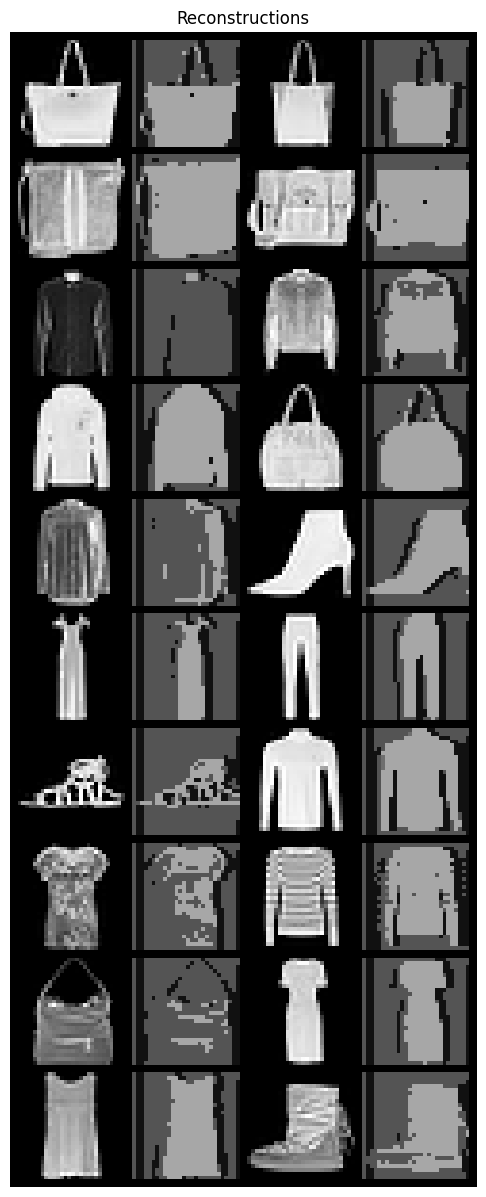

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00,  2.05it/s]
Validation bpd: 8.027


/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'train_dataloader' to speed up the dataloader worker initialization.


Epoch 0: 100%|██████████| 421/421 [02:42<00:00,  2.59it/s, v_num=3]
Validation bpd: 3.476


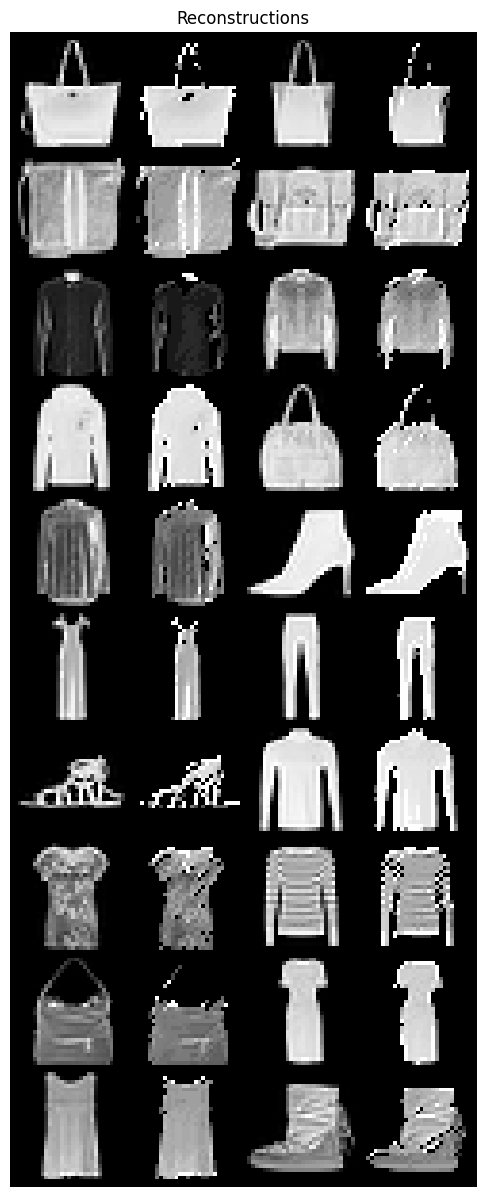


Validation bpd: 3.207

Validation bpd: 3.359

Validation bpd: 3.313

Validation bpd: 3.257

Validation bpd: 3.234

Validation bpd: 3.232

Validation bpd: 3.242

Validation bpd: 3.356

Validation bpd: 3.197

Validation bpd: 3.506

Validation bpd: 3.239

Validation bpd: 3.219

Validation bpd: 3.258

Validation bpd: 3.212

Validation bpd: 3.338

Validation bpd: 3.245

Validation bpd: 3.257

Validation bpd: 3.261

Validation bpd: 3.321

Validation bpd: 3.325

Validation bpd: 3.319

Validation bpd: 3.253

Validation bpd: 3.340

Validation bpd: 3.189

Validation bpd: 3.304

Validation bpd: 3.211

Validation bpd: 3.122

Validation bpd: 3.220

Validation bpd: 3.180

Validation bpd: 3.358

Validation bpd: 3.245

Validation bpd: 3.260

Validation bpd: 3.208

Validation bpd: 3.131

Validation bpd: 3.276

Validation bpd: 3.209

Validation bpd: 3.309

Validation bpd: 3.348

Validation bpd: 3.153

Validation bpd: 3.227

Validation bpd: 3.228

Validation bpd: 3.202

Validation bpd: 3.274

Validation

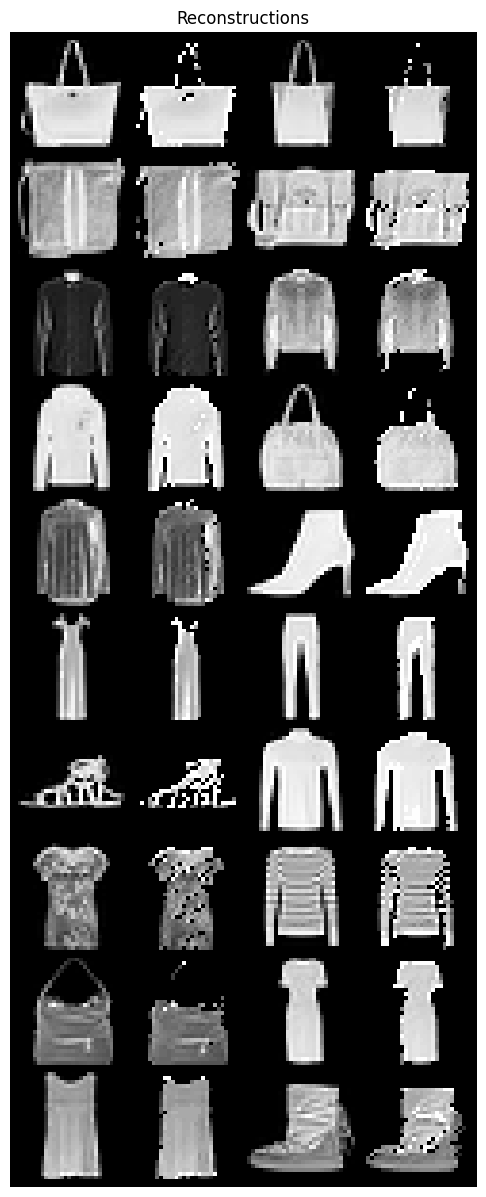


Validation bpd: 3.034

Validation bpd: 3.179

Validation bpd: 3.129

Validation bpd: 3.087

Validation bpd: 3.074

Validation bpd: 3.066

Validation bpd: 3.073

Validation bpd: 3.164

Validation bpd: 3.016

Validation bpd: 3.319

Validation bpd: 3.054

Validation bpd: 3.057

Validation bpd: 3.066

Validation bpd: 3.022

Validation bpd: 3.159

Validation bpd: 3.080

Validation bpd: 3.084

Validation bpd: 3.095

Validation bpd: 3.134

Validation bpd: 3.148

Validation bpd: 3.144

Validation bpd: 3.082

Validation bpd: 3.157

Validation bpd: 3.007

Validation bpd: 3.138

Validation bpd: 3.024

Validation bpd: 2.947

Validation bpd: 3.033

Validation bpd: 3.005

Validation bpd: 3.168

Validation bpd: 3.049

Validation bpd: 3.084

Validation bpd: 3.030

Validation bpd: 2.956

Validation bpd: 3.079

Validation bpd: 3.038

Validation bpd: 3.129

Validation bpd: 3.162

Validation bpd: 2.985

Validation bpd: 3.034

Validation bpd: 3.041

Validation bpd: 3.031

Validation bpd: 3.091

Validation

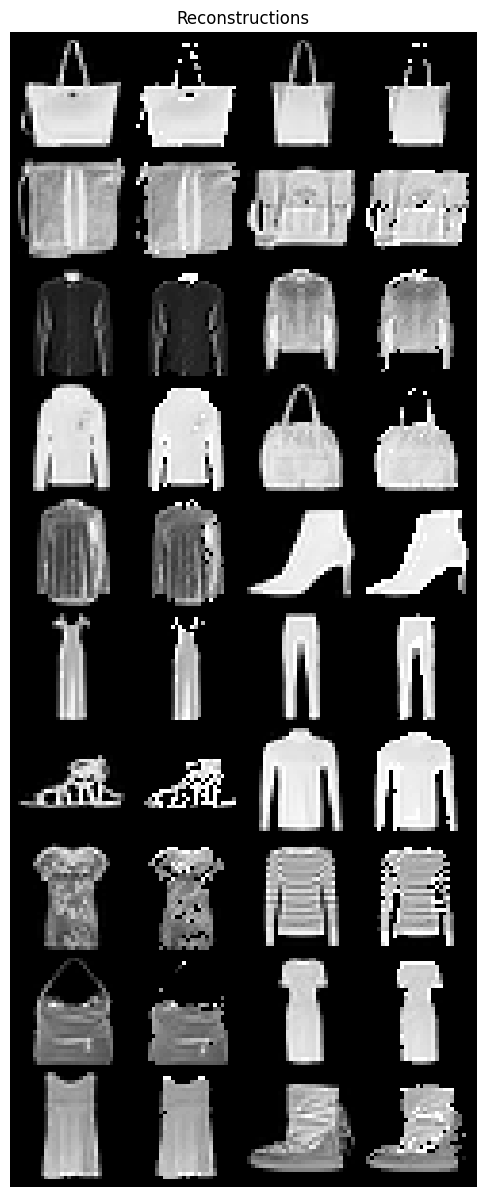


Validation bpd: 2.969

Validation bpd: 3.110

Validation bpd: 3.054

Validation bpd: 3.017

Validation bpd: 3.010

Validation bpd: 2.994

Validation bpd: 3.005

Validation bpd: 3.090

Validation bpd: 2.945

Validation bpd: 3.247

Validation bpd: 2.988

Validation bpd: 2.995

Validation bpd: 2.995

Validation bpd: 2.946

Validation bpd: 3.090

Validation bpd: 3.012

Validation bpd: 3.013

Validation bpd: 3.034

Validation bpd: 3.060

Validation bpd: 3.082

Validation bpd: 3.078

Validation bpd: 3.015

Validation bpd: 3.085

Validation bpd: 2.937

Validation bpd: 3.072

Validation bpd: 2.951

Validation bpd: 2.879

Validation bpd: 2.959

Validation bpd: 2.939

Validation bpd: 3.095

Validation bpd: 2.974

Validation bpd: 3.015

Validation bpd: 2.962

Validation bpd: 2.890

Validation bpd: 3.004

Validation bpd: 2.968

Validation bpd: 3.060

Validation bpd: 3.088

Validation bpd: 2.918

Validation bpd: 2.959

Validation bpd: 2.967

Validation bpd: 2.967

Validation bpd: 3.021

Validation

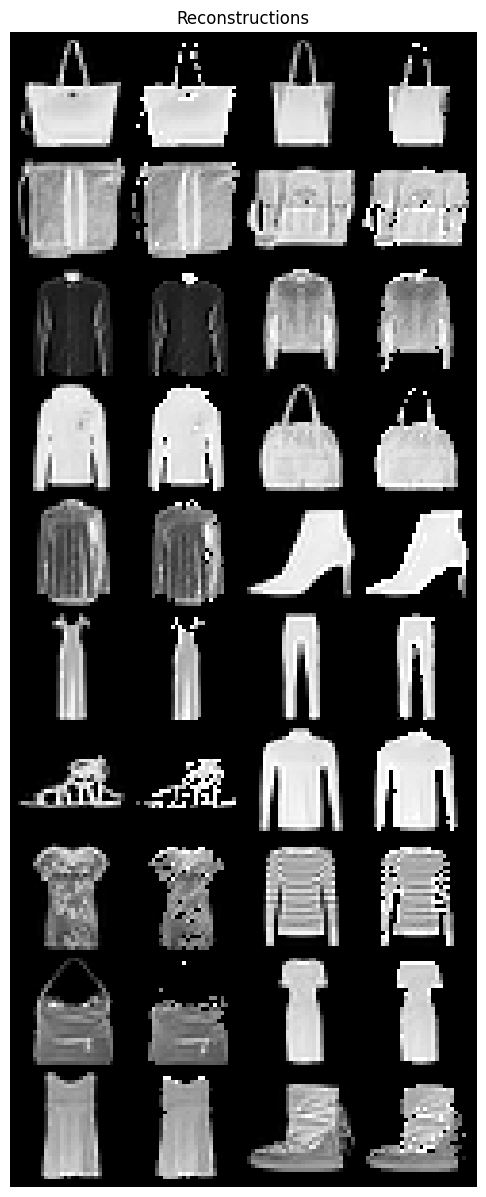


Validation bpd: 2.916

Validation bpd: 3.054

Validation bpd: 2.999

Validation bpd: 2.966

Validation bpd: 2.964

Validation bpd: 2.944

Validation bpd: 2.949

Validation bpd: 3.032

Validation bpd: 2.892

Validation bpd: 3.190

Validation bpd: 2.935

Validation bpd: 2.943

Validation bpd: 2.939

Validation bpd: 2.888

Validation bpd: 3.032

Validation bpd: 2.959

Validation bpd: 2.961

Validation bpd: 2.983

Validation bpd: 3.003

Validation bpd: 3.026

Validation bpd: 3.026

Validation bpd: 2.962

Validation bpd: 3.032

Validation bpd: 2.884

Validation bpd: 3.021

Validation bpd: 2.896

Validation bpd: 2.828

Validation bpd: 2.902

Validation bpd: 2.888

Validation bpd: 3.037

Validation bpd: 2.909

Validation bpd: 2.955

Validation bpd: 2.911

Validation bpd: 2.838

Validation bpd: 2.944

Validation bpd: 2.915

Validation bpd: 3.006

Validation bpd: 3.034

Validation bpd: 2.863

Validation bpd: 2.901

Validation bpd: 2.914

Validation bpd: 2.918

Validation bpd: 2.968

Validation

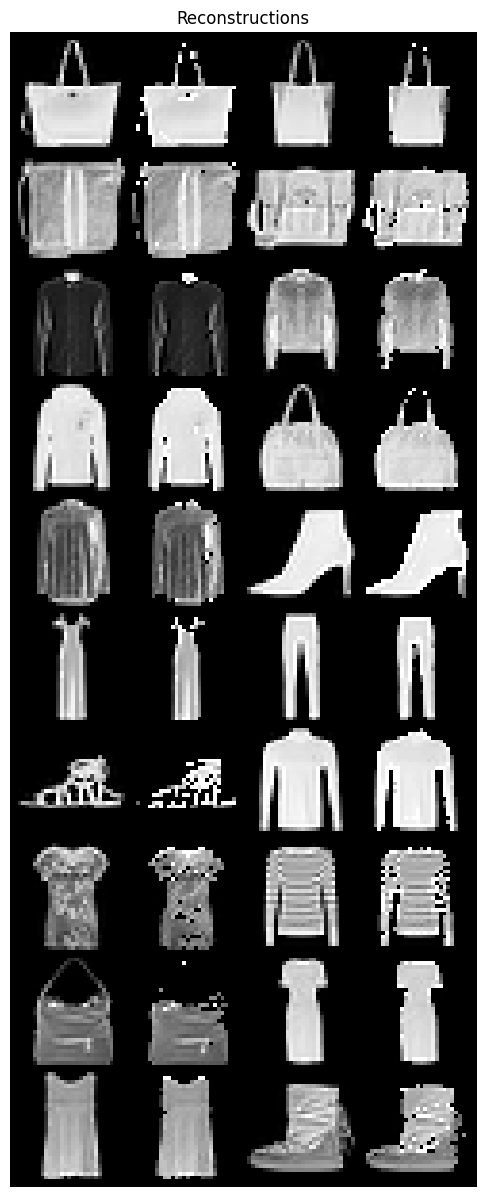


Validation bpd: 2.899

Validation bpd: 3.039

Validation bpd: 2.980

Validation bpd: 2.954

Validation bpd: 2.948

Validation bpd: 2.929

Validation bpd: 2.933

Validation bpd: 3.018

Validation bpd: 2.872

Validation bpd: 3.176

Validation bpd: 2.920

Validation bpd: 2.929

Validation bpd: 2.926

Validation bpd: 2.874

Validation bpd: 3.015

Validation bpd: 2.941

Validation bpd: 2.944

Validation bpd: 2.967

Validation bpd: 2.986

Validation bpd: 3.010

Validation bpd: 3.011

Validation bpd: 2.947

Validation bpd: 3.019

Validation bpd: 2.869

Validation bpd: 3.008

Validation bpd: 2.882

Validation bpd: 2.814

Validation bpd: 2.889

Validation bpd: 2.874

Validation bpd: 3.019

Validation bpd: 2.895

Validation bpd: 2.940

Validation bpd: 2.897

Validation bpd: 2.819

Validation bpd: 2.930

Validation bpd: 2.898

Validation bpd: 2.993

Validation bpd: 3.020

Validation bpd: 2.848

Validation bpd: 2.885

Validation bpd: 2.898

Validation bpd: 2.902

Validation bpd: 2.952

Validation

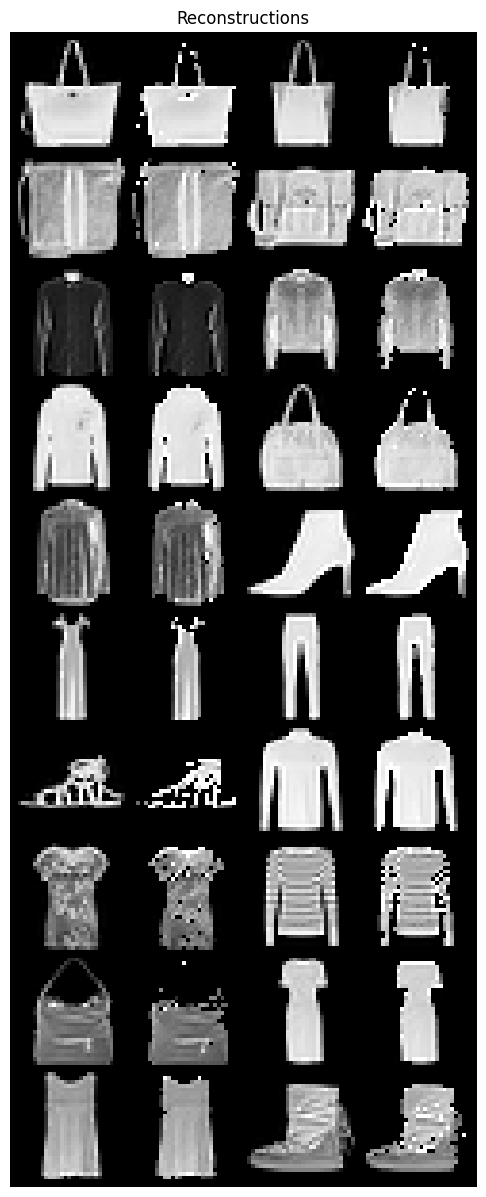


Validation bpd: 2.868

Validation bpd: 3.008

Validation bpd: 2.945

Validation bpd: 2.924

Validation bpd: 2.919

Validation bpd: 2.894

Validation bpd: 2.902

Validation bpd: 2.983

Validation bpd: 2.840

Validation bpd: 3.138

Validation bpd: 2.885

Validation bpd: 2.899

Validation bpd: 2.889

Validation bpd: 2.837

Validation bpd: 2.983

Validation bpd: 2.911

Validation bpd: 2.913

Validation bpd: 2.934

Validation bpd: 2.951

Validation bpd: 2.977

Validation bpd: 2.978

Validation bpd: 2.913

Validation bpd: 2.984

Validation bpd: 2.836

Validation bpd: 2.977

Validation bpd: 2.847

Validation bpd: 2.780

Validation bpd: 2.854

Validation bpd: 2.842

Validation bpd: 2.983

Validation bpd: 2.856

Validation bpd: 2.905

Validation bpd: 2.863

Validation bpd: 2.786

Validation bpd: 2.892

Validation bpd: 2.866

Validation bpd: 2.959

Validation bpd: 2.984

Validation bpd: 2.814

Validation bpd: 2.850

Validation bpd: 2.863

Validation bpd: 2.870

Validation bpd: 2.918

Validation

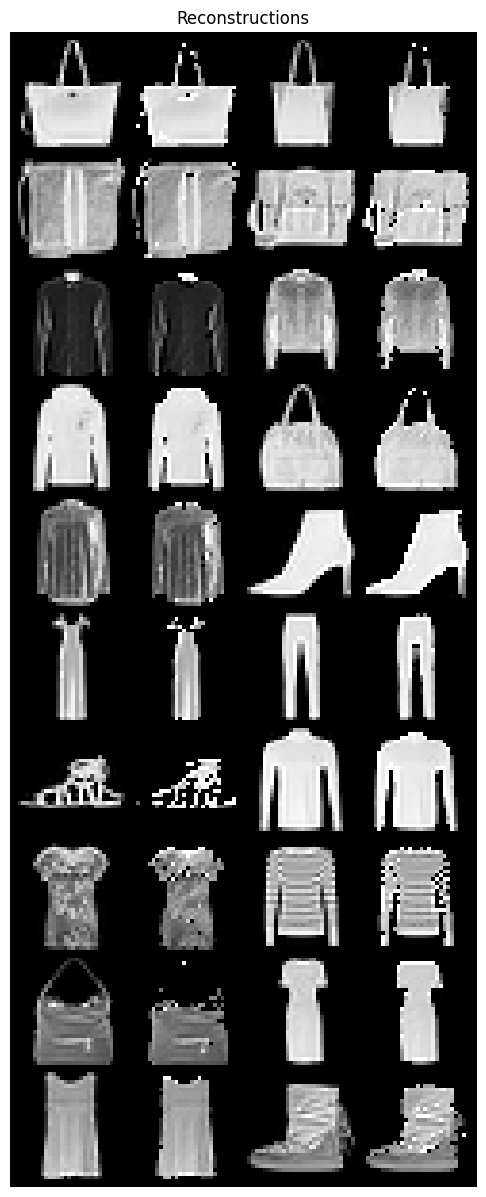


Validation bpd: 2.859

Validation bpd: 2.999

Validation bpd: 2.935

Validation bpd: 2.914

Validation bpd: 2.912

Validation bpd: 2.889

Validation bpd: 2.894

Validation bpd: 2.976

Validation bpd: 2.836

Validation bpd: 3.131

Validation bpd: 2.878

Validation bpd: 2.890

Validation bpd: 2.882

Validation bpd: 2.831

Validation bpd: 2.973

Validation bpd: 2.899

Validation bpd: 2.900

Validation bpd: 2.930

Validation bpd: 2.945

Validation bpd: 2.967

Validation bpd: 2.969

Validation bpd: 2.906

Validation bpd: 2.977

Validation bpd: 2.829

Validation bpd: 2.971

Validation bpd: 2.843

Validation bpd: 2.773

Validation bpd: 2.845

Validation bpd: 2.836

Validation bpd: 2.973

Validation bpd: 2.851

Validation bpd: 2.899

Validation bpd: 2.858

Validation bpd: 2.779

Validation bpd: 2.888

Validation bpd: 2.855

Validation bpd: 2.952

Validation bpd: 2.976

Validation bpd: 2.807

Validation bpd: 2.847

Validation bpd: 2.858

Validation bpd: 2.860

Validation bpd: 2.909

Validation

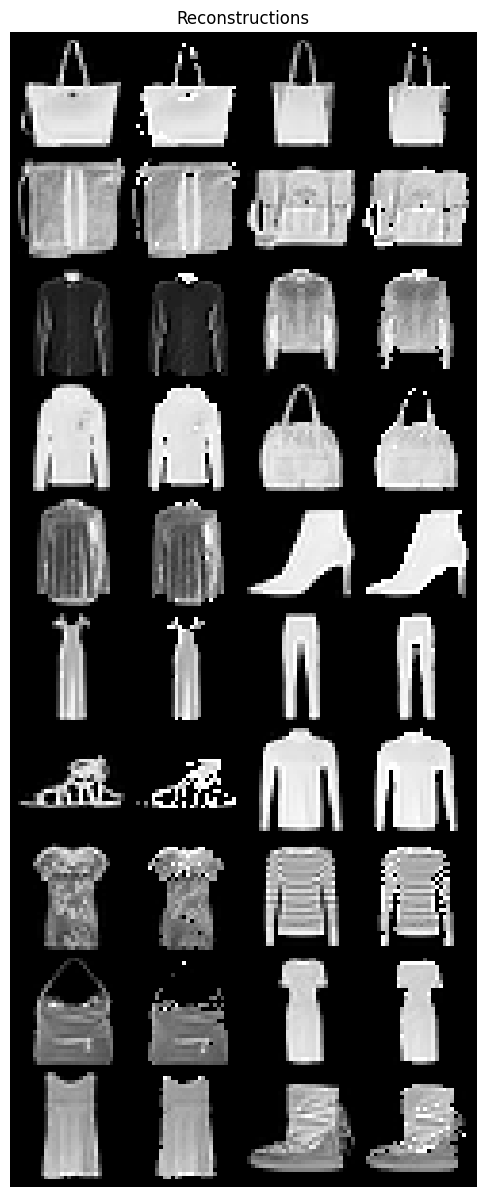


Validation bpd: 2.835

Validation bpd: 2.974

Validation bpd: 2.909

Validation bpd: 2.888

Validation bpd: 2.889

Validation bpd: 2.863

Validation bpd: 2.868

Validation bpd: 2.947

Validation bpd: 2.807

Validation bpd: 3.103

Validation bpd: 2.852

Validation bpd: 2.868

Validation bpd: 2.854

Validation bpd: 2.802

Validation bpd: 2.948

Validation bpd: 2.877

Validation bpd: 2.877

Validation bpd: 2.905

Validation bpd: 2.915

Validation bpd: 2.944

Validation bpd: 2.948

Validation bpd: 2.879

Validation bpd: 2.951

Validation bpd: 2.802

Validation bpd: 2.946

Validation bpd: 2.813

Validation bpd: 2.745

Validation bpd: 2.819

Validation bpd: 2.810

Validation bpd: 2.946

Validation bpd: 2.821

Validation bpd: 2.873

Validation bpd: 2.831

Validation bpd: 2.754

Validation bpd: 2.854

Validation bpd: 2.833

Validation bpd: 2.927

Validation bpd: 2.952

Validation bpd: 2.781

Validation bpd: 2.814

Validation bpd: 2.826

Validation bpd: 2.836

Validation bpd: 2.884

Validation

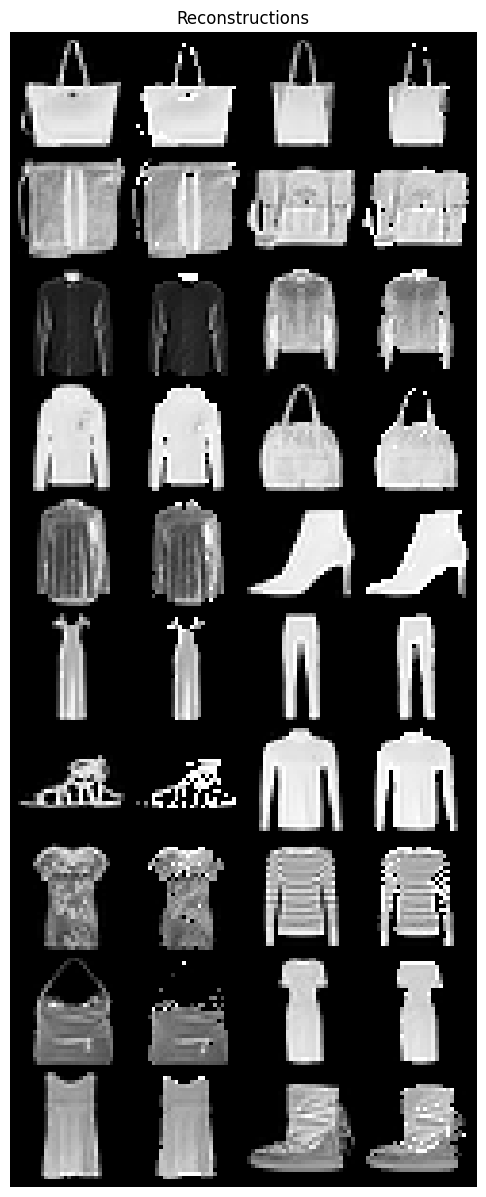


Validation bpd: 2.828

Validation bpd: 2.970

Validation bpd: 2.903

Validation bpd: 2.882

Validation bpd: 2.882

Validation bpd: 2.856

Validation bpd: 2.864

Validation bpd: 2.943

Validation bpd: 2.801

Validation bpd: 3.099

Validation bpd: 2.848

Validation bpd: 2.862

Validation bpd: 2.848

Validation bpd: 2.797

Validation bpd: 2.943

Validation bpd: 2.871

Validation bpd: 2.869

Validation bpd: 2.899

Validation bpd: 2.912

Validation bpd: 2.938

Validation bpd: 2.943

Validation bpd: 2.874

Validation bpd: 2.947

Validation bpd: 2.796

Validation bpd: 2.943

Validation bpd: 2.809

Validation bpd: 2.740

Validation bpd: 2.814

Validation bpd: 2.805

Validation bpd: 2.941

Validation bpd: 2.816

Validation bpd: 2.866

Validation bpd: 2.828

Validation bpd: 2.747

Validation bpd: 2.851

Validation bpd: 2.826

Validation bpd: 2.921

Validation bpd: 2.947

Validation bpd: 2.777

Validation bpd: 2.813

Validation bpd: 2.822

Validation bpd: 2.828

Validation bpd: 2.878

Validation

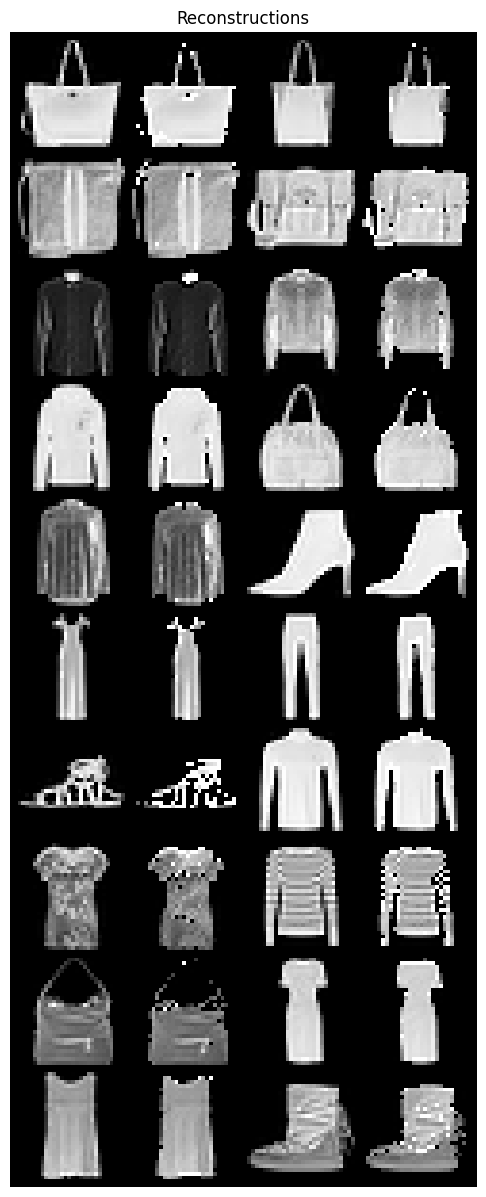


Validation bpd: 2.826

Validation bpd: 2.968

Validation bpd: 2.898

Validation bpd: 2.883

Validation bpd: 2.879

Validation bpd: 2.854

Validation bpd: 2.863

Validation bpd: 2.938

Validation bpd: 2.796

Validation bpd: 3.093

Validation bpd: 2.847

Validation bpd: 2.859

Validation bpd: 2.843

Validation bpd: 2.792

Validation bpd: 2.940

Validation bpd: 2.869

Validation bpd: 2.866

Validation bpd: 2.895

Validation bpd: 2.907

Validation bpd: 2.936

Validation bpd: 2.941

Validation bpd: 2.871

Validation bpd: 2.943

Validation bpd: 2.792

Validation bpd: 2.936

Validation bpd: 2.805

Validation bpd: 2.734

Validation bpd: 2.808

Validation bpd: 2.801

Validation bpd: 2.937

Validation bpd: 2.812

Validation bpd: 2.862

Validation bpd: 2.823

Validation bpd: 2.744

Validation bpd: 2.848

Validation bpd: 2.824

Validation bpd: 2.915

Validation bpd: 2.939

Validation bpd: 2.770

Validation bpd: 2.803

Validation bpd: 2.819

Validation bpd: 2.826

Validation bpd: 2.877

Validation

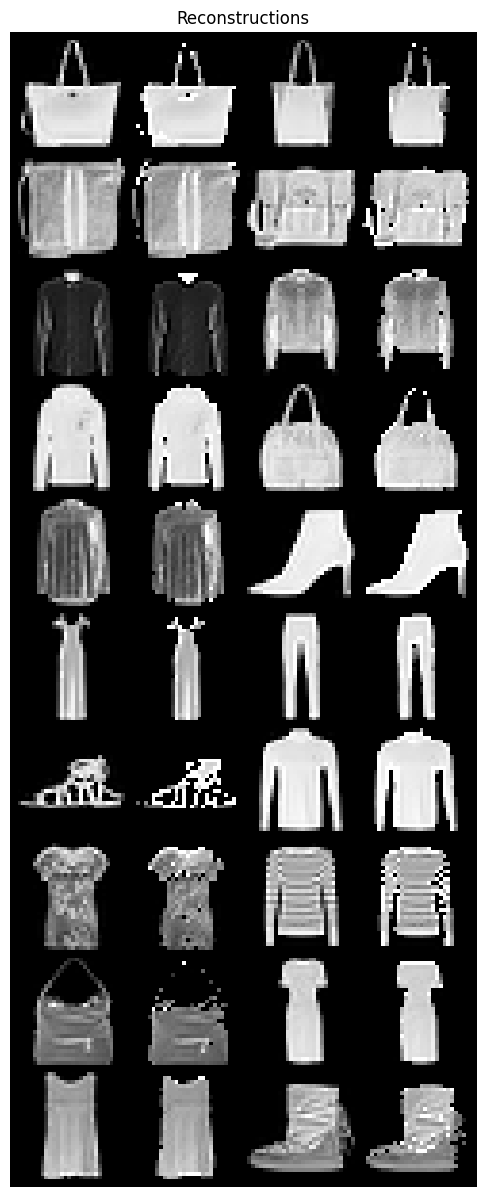


Validation bpd: 2.809

Validation bpd: 2.951

Validation bpd: 2.881

Validation bpd: 2.866

Validation bpd: 2.864

Validation bpd: 2.839

Validation bpd: 2.845

Validation bpd: 2.919

Validation bpd: 2.781

Validation bpd: 3.077

Validation bpd: 2.828

Validation bpd: 2.844

Validation bpd: 2.826

Validation bpd: 2.777

Validation bpd: 2.921

Validation bpd: 2.852

Validation bpd: 2.850

Validation bpd: 2.880

Validation bpd: 2.888

Validation bpd: 2.916

Validation bpd: 2.923

Validation bpd: 2.854

Validation bpd: 2.925

Validation bpd: 2.776

Validation bpd: 2.921

Validation bpd: 2.787

Validation bpd: 2.719

Validation bpd: 2.792

Validation bpd: 2.785

Validation bpd: 2.920

Validation bpd: 2.798

Validation bpd: 2.845

Validation bpd: 2.804

Validation bpd: 2.725

Validation bpd: 2.828

Validation bpd: 2.806

Validation bpd: 2.899

Validation bpd: 2.924

Validation bpd: 2.754

Validation bpd: 2.785

Validation bpd: 2.800

Validation bpd: 2.809

Validation bpd: 2.857

Validation

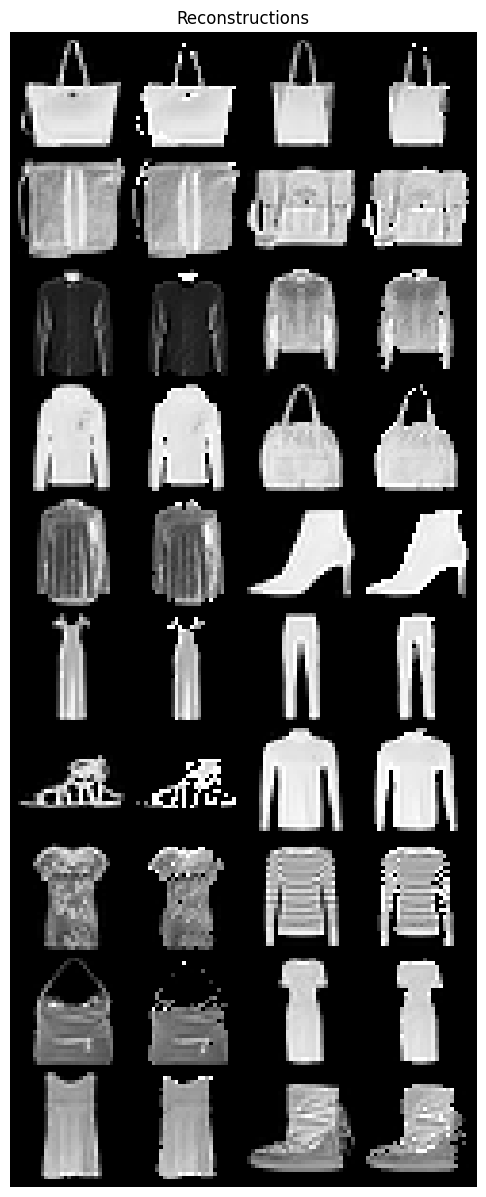


Validation bpd: 2.802

Validation bpd: 2.943

Validation bpd: 2.871

Validation bpd: 2.858

Validation bpd: 2.856

Validation bpd: 2.829

Validation bpd: 2.833

Validation bpd: 2.911

Validation bpd: 2.773

Validation bpd: 3.065

Validation bpd: 2.818

Validation bpd: 2.834

Validation bpd: 2.816

Validation bpd: 2.768

Validation bpd: 2.913

Validation bpd: 2.845

Validation bpd: 2.842

Validation bpd: 2.871

Validation bpd: 2.881

Validation bpd: 2.907

Validation bpd: 2.915

Validation bpd: 2.845

Validation bpd: 2.917

Validation bpd: 2.768

Validation bpd: 2.913

Validation bpd: 2.780

Validation bpd: 2.709

Validation bpd: 2.783

Validation bpd: 2.777

Validation bpd: 2.909

Validation bpd: 2.786

Validation bpd: 2.835

Validation bpd: 2.796

Validation bpd: 2.714

Validation bpd: 2.817

Validation bpd: 2.798

Validation bpd: 2.892

Validation bpd: 2.916

Validation bpd: 2.746

Validation bpd: 2.778

Validation bpd: 2.790

Validation bpd: 2.800

Validation bpd: 2.848

Validation

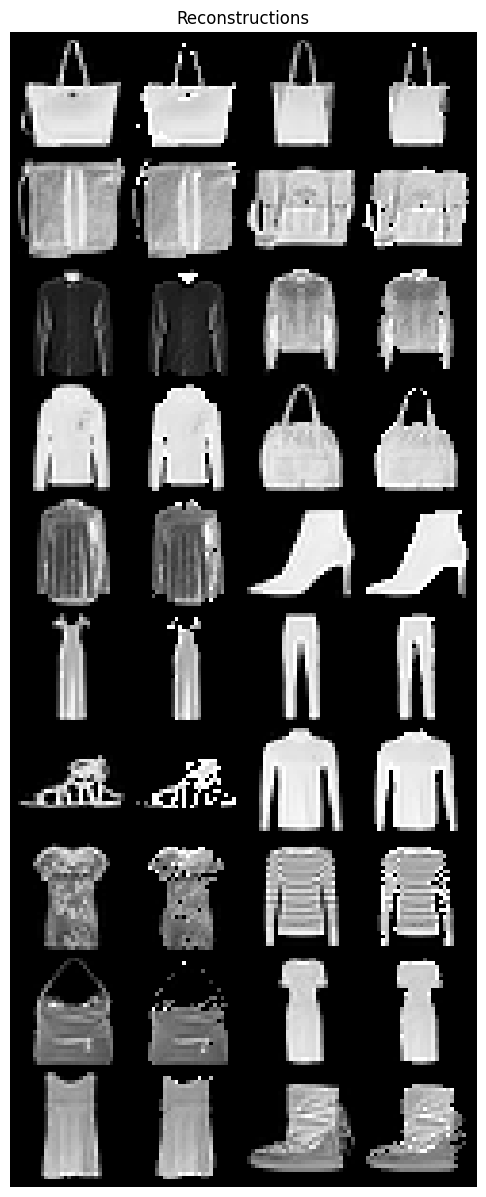


Validation bpd: 2.806

Validation bpd: 2.947

Validation bpd: 2.877

Validation bpd: 2.862

Validation bpd: 2.863

Validation bpd: 2.838

Validation bpd: 2.840

Validation bpd: 2.917

Validation bpd: 2.782

Validation bpd: 3.070

Validation bpd: 2.825

Validation bpd: 2.841

Validation bpd: 2.827

Validation bpd: 2.773

Validation bpd: 2.921

Validation bpd: 2.850

Validation bpd: 2.845

Validation bpd: 2.880

Validation bpd: 2.888

Validation bpd: 2.914

Validation bpd: 2.921

Validation bpd: 2.854

Validation bpd: 2.924

Validation bpd: 2.777

Validation bpd: 2.920

Validation bpd: 2.789

Validation bpd: 2.716

Validation bpd: 2.788

Validation bpd: 2.785

Validation bpd: 2.915

Validation bpd: 2.795

Validation bpd: 2.844

Validation bpd: 2.802

Validation bpd: 2.720

Validation bpd: 2.828

Validation bpd: 2.798

Validation bpd: 2.898

Validation bpd: 2.920

Validation bpd: 2.751

Validation bpd: 2.787

Validation bpd: 2.800

Validation bpd: 2.804

Validation bpd: 2.856

Validation

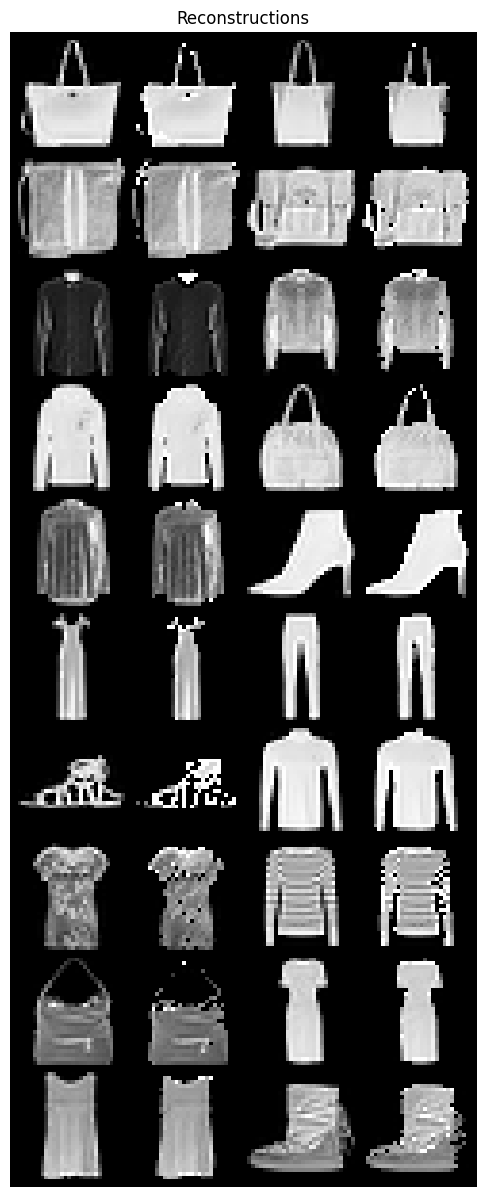


Validation bpd: 2.791

Validation bpd: 2.932

Validation bpd: 2.862

Validation bpd: 2.846

Validation bpd: 2.847

Validation bpd: 2.822

Validation bpd: 2.826

Validation bpd: 2.901

Validation bpd: 2.766

Validation bpd: 3.054

Validation bpd: 2.810

Validation bpd: 2.824

Validation bpd: 2.809

Validation bpd: 2.758

Validation bpd: 2.905

Validation bpd: 2.835

Validation bpd: 2.830

Validation bpd: 2.865

Validation bpd: 2.872

Validation bpd: 2.899

Validation bpd: 2.907

Validation bpd: 2.838

Validation bpd: 2.909

Validation bpd: 2.760

Validation bpd: 2.906

Validation bpd: 2.772

Validation bpd: 2.700

Validation bpd: 2.772

Validation bpd: 2.769

Validation bpd: 2.898

Validation bpd: 2.776

Validation bpd: 2.825

Validation bpd: 2.789

Validation bpd: 2.708

Validation bpd: 2.812

Validation bpd: 2.787

Validation bpd: 2.881

Validation bpd: 2.906

Validation bpd: 2.736

Validation bpd: 2.773

Validation bpd: 2.783

Validation bpd: 2.790

Validation bpd: 2.840

Validation

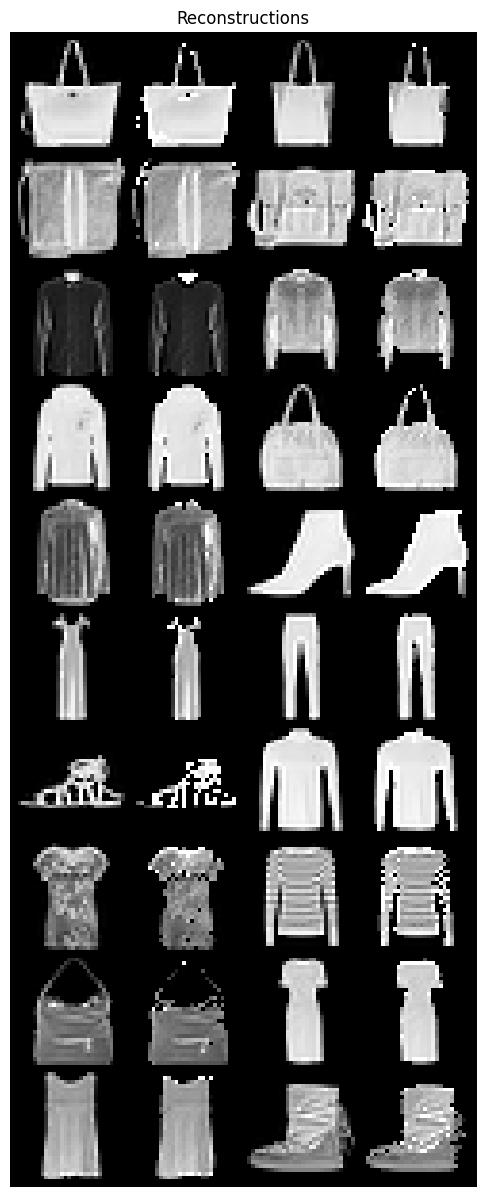


Validation bpd: 2.790

Validation bpd: 2.931

Validation bpd: 2.856

Validation bpd: 2.845

Validation bpd: 2.845

Validation bpd: 2.817

Validation bpd: 2.820

Validation bpd: 2.896

Validation bpd: 2.759

Validation bpd: 3.050

Validation bpd: 2.807

Validation bpd: 2.823

Validation bpd: 2.803

Validation bpd: 2.752

Validation bpd: 2.902

Validation bpd: 2.832

Validation bpd: 2.827

Validation bpd: 2.859

Validation bpd: 2.867

Validation bpd: 2.894

Validation bpd: 2.904

Validation bpd: 2.831

Validation bpd: 2.907

Validation bpd: 2.758

Validation bpd: 2.902

Validation bpd: 2.768

Validation bpd: 2.696

Validation bpd: 2.768

Validation bpd: 2.765

Validation bpd: 2.896

Validation bpd: 2.775

Validation bpd: 2.823

Validation bpd: 2.783

Validation bpd: 2.700

Validation bpd: 2.803

Validation bpd: 2.783

Validation bpd: 2.879

Validation bpd: 2.905

Validation bpd: 2.733

Validation bpd: 2.764

Validation bpd: 2.778

Validation bpd: 2.786

Validation bpd: 2.835

Validation

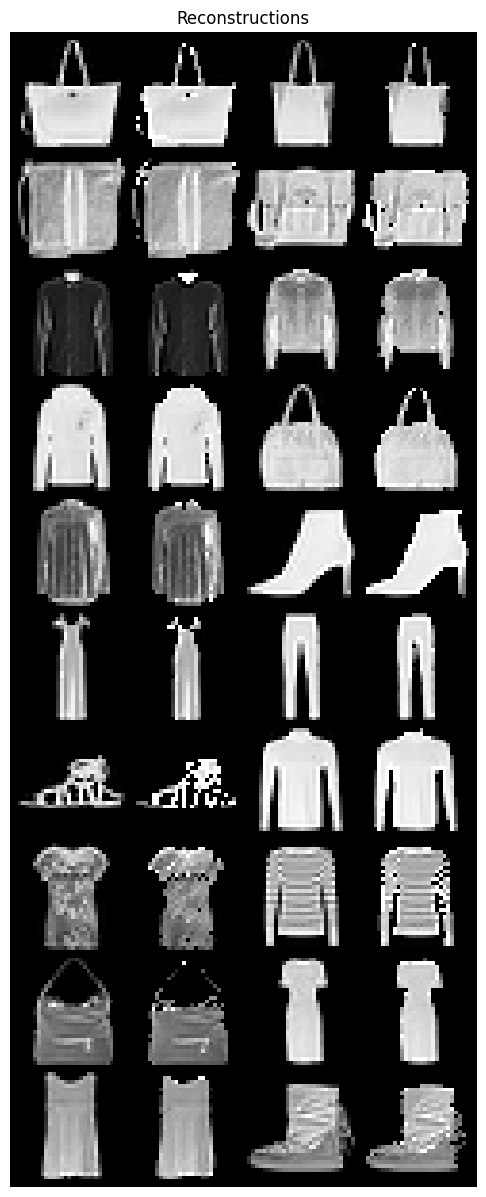


Validation bpd: 2.777

Validation bpd: 2.918

Validation bpd: 2.844

Validation bpd: 2.831

Validation bpd: 2.834

Validation bpd: 2.804

Validation bpd: 2.809

Validation bpd: 2.882

Validation bpd: 2.748

Validation bpd: 3.038

Validation bpd: 2.792

Validation bpd: 2.811

Validation bpd: 2.790

Validation bpd: 2.743

Validation bpd: 2.890

Validation bpd: 2.820

Validation bpd: 2.815

Validation bpd: 2.849

Validation bpd: 2.855

Validation bpd: 2.883

Validation bpd: 2.892

Validation bpd: 2.821

Validation bpd: 2.893

Validation bpd: 2.743

Validation bpd: 2.889

Validation bpd: 2.755

Validation bpd: 2.683

Validation bpd: 2.755

Validation bpd: 2.753

Validation bpd: 2.882

Validation bpd: 2.758

Validation bpd: 2.808

Validation bpd: 2.773

Validation bpd: 2.690

Validation bpd: 2.790

Validation bpd: 2.772

Validation bpd: 2.865

Validation bpd: 2.891

Validation bpd: 2.721

Validation bpd: 2.751

Validation bpd: 2.765

Validation bpd: 2.772

Validation bpd: 2.824

Validation

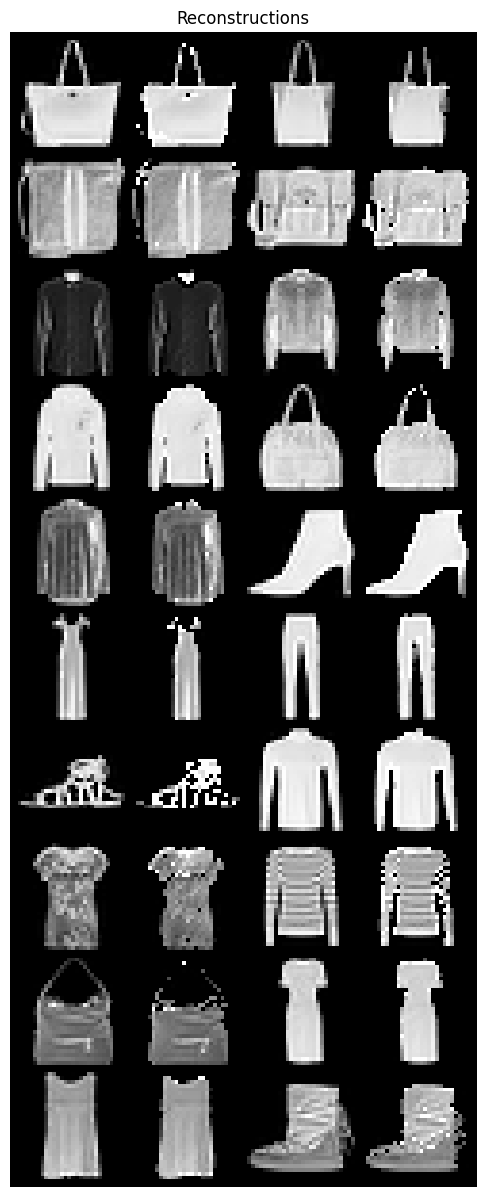


Validation bpd: 2.774

Validation bpd: 2.916

Validation bpd: 2.841

Validation bpd: 2.828

Validation bpd: 2.832

Validation bpd: 2.804

Validation bpd: 2.806

Validation bpd: 2.883

Validation bpd: 2.747

Validation bpd: 3.036

Validation bpd: 2.793

Validation bpd: 2.809

Validation bpd: 2.789

Validation bpd: 2.740

Validation bpd: 2.887

Validation bpd: 2.817

Validation bpd: 2.812

Validation bpd: 2.848

Validation bpd: 2.853

Validation bpd: 2.881

Validation bpd: 2.890

Validation bpd: 2.817

Validation bpd: 2.890

Validation bpd: 2.741

Validation bpd: 2.888

Validation bpd: 2.755

Validation bpd: 2.683

Validation bpd: 2.753

Validation bpd: 2.752

Validation bpd: 2.880

Validation bpd: 2.758

Validation bpd: 2.808

Validation bpd: 2.772

Validation bpd: 2.687

Validation bpd: 2.790

Validation bpd: 2.770

Validation bpd: 2.866

Validation bpd: 2.889

Validation bpd: 2.719

Validation bpd: 2.751

Validation bpd: 2.762

Validation bpd: 2.773

Validation bpd: 2.819

Validation

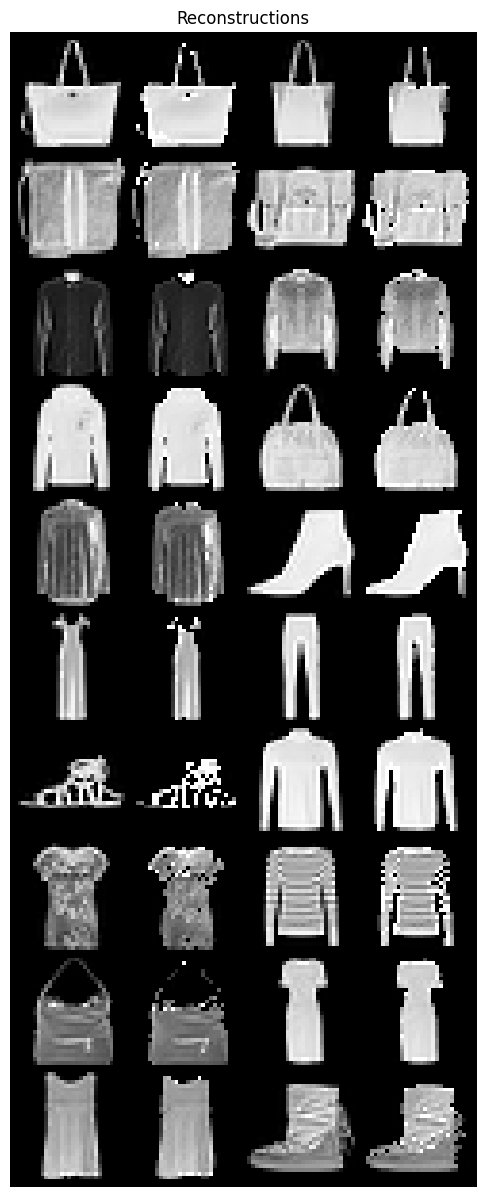


Validation bpd: 2.785

Validation bpd: 2.925

Validation bpd: 2.851

Validation bpd: 2.839

Validation bpd: 2.842

Validation bpd: 2.818

Validation bpd: 2.813

Validation bpd: 2.893

Validation bpd: 2.764

Validation bpd: 3.047

Validation bpd: 2.800

Validation bpd: 2.817

Validation bpd: 2.801

Validation bpd: 2.762

Validation bpd: 2.893

Validation bpd: 2.831

Validation bpd: 2.826

Validation bpd: 2.856

Validation bpd: 2.865

Validation bpd: 2.891

Validation bpd: 2.898

Validation bpd: 2.827

Validation bpd: 2.903

Validation bpd: 2.752

Validation bpd: 2.896

Validation bpd: 2.768

Validation bpd: 2.693

Validation bpd: 2.764

Validation bpd: 2.761

Validation bpd: 2.889

Validation bpd: 2.769

Validation bpd: 2.816

Validation bpd: 2.777

Validation bpd: 2.698

Validation bpd: 2.799

Validation bpd: 2.782

Validation bpd: 2.873

Validation bpd: 2.900

Validation bpd: 2.729

Validation bpd: 2.760

Validation bpd: 2.776

Validation bpd: 2.784

Validation bpd: 2.830

Validation

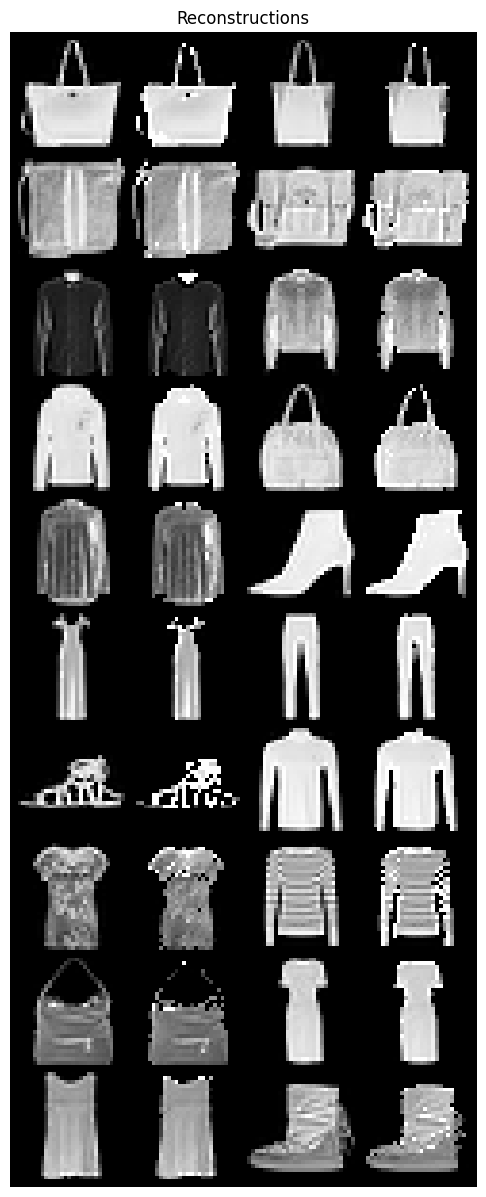


Validation bpd: 2.796

Validation bpd: 2.932

Validation bpd: 2.860

Validation bpd: 2.845

Validation bpd: 2.848

Validation bpd: 2.821

Validation bpd: 2.828

Validation bpd: 2.905

Validation bpd: 2.772

Validation bpd: 3.059

Validation bpd: 2.816

Validation bpd: 2.824

Validation bpd: 2.810

Validation bpd: 2.765

Validation bpd: 2.911

Validation bpd: 2.836

Validation bpd: 2.831

Validation bpd: 2.871

Validation bpd: 2.877

Validation bpd: 2.903

Validation bpd: 2.908

Validation bpd: 2.839

Validation bpd: 2.914

Validation bpd: 2.762

Validation bpd: 2.909

Validation bpd: 2.778

Validation bpd: 2.703

Validation bpd: 2.777

Validation bpd: 2.775

Validation bpd: 2.903

Validation bpd: 2.786

Validation bpd: 2.828

Validation bpd: 2.791

Validation bpd: 2.710

Validation bpd: 2.814

Validation bpd: 2.791

Validation bpd: 2.890

Validation bpd: 2.908

Validation bpd: 2.742

Validation bpd: 2.779

Validation bpd: 2.791

Validation bpd: 2.793

Validation bpd: 2.840

Validation

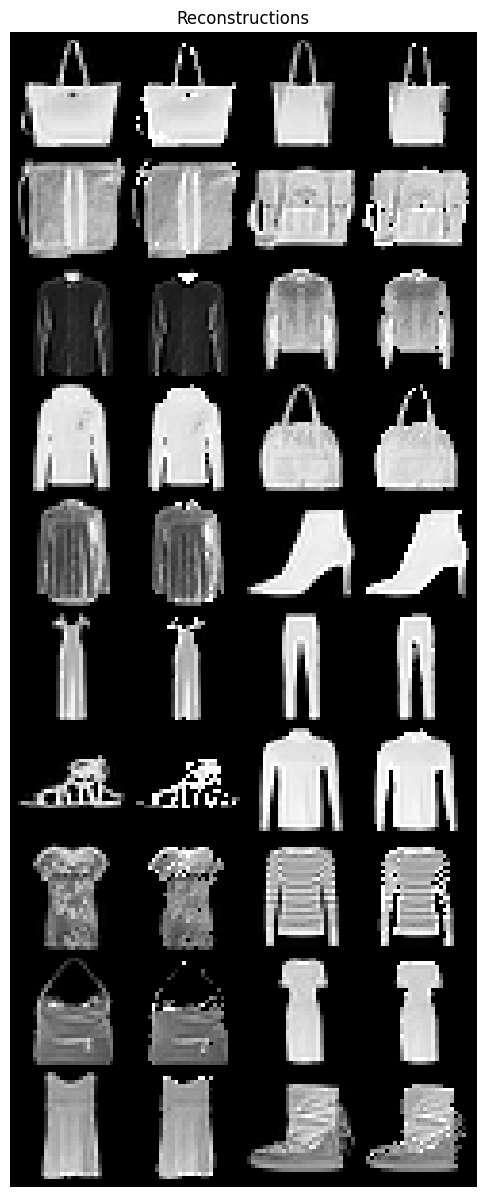


Validation bpd: 2.771

Validation bpd: 2.912

Validation bpd: 2.835

Validation bpd: 2.827

Validation bpd: 2.826

Validation bpd: 2.798

Validation bpd: 2.801

Validation bpd: 2.877

Validation bpd: 2.739

Validation bpd: 3.032

Validation bpd: 2.787

Validation bpd: 2.805

Validation bpd: 2.783

Validation bpd: 2.735

Validation bpd: 2.883

Validation bpd: 2.814

Validation bpd: 2.808

Validation bpd: 2.841

Validation bpd: 2.850

Validation bpd: 2.875

Validation bpd: 2.883

Validation bpd: 2.814

Validation bpd: 2.887

Validation bpd: 2.737

Validation bpd: 2.882

Validation bpd: 2.750

Validation bpd: 2.676

Validation bpd: 2.749

Validation bpd: 2.747

Validation bpd: 2.876

Validation bpd: 2.755

Validation bpd: 2.803

Validation bpd: 2.766

Validation bpd: 2.679

Validation bpd: 2.783

Validation bpd: 2.766

Validation bpd: 2.861

Validation bpd: 2.885

Validation bpd: 2.714

Validation bpd: 2.748

Validation bpd: 2.756

Validation bpd: 2.766

Validation bpd: 2.814

Validation

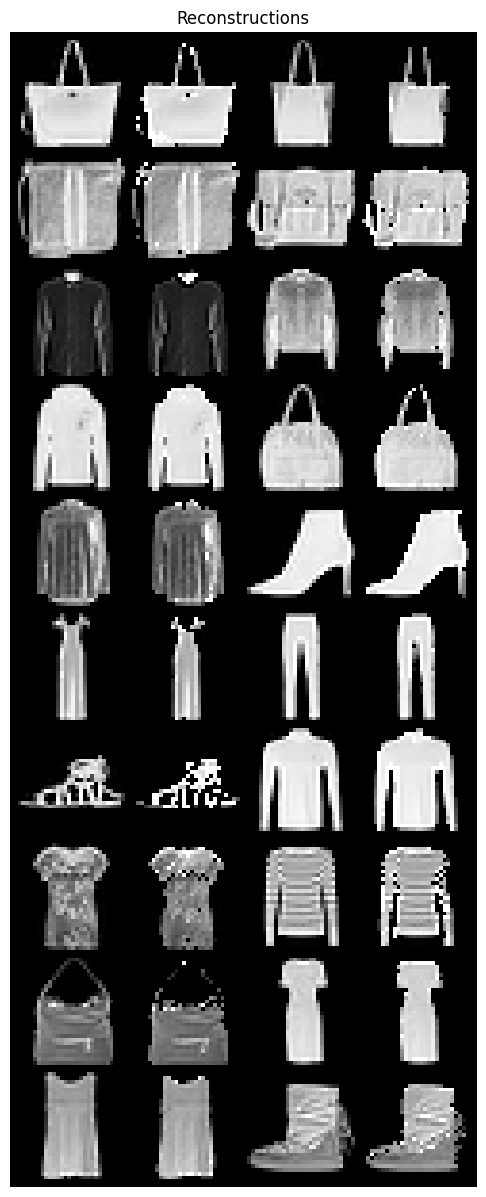


Validation bpd: 2.765

Validation bpd: 2.907

Validation bpd: 2.829

Validation bpd: 2.821

Validation bpd: 2.824

Validation bpd: 2.795

Validation bpd: 2.798

Validation bpd: 2.871

Validation bpd: 2.734

Validation bpd: 3.027

Validation bpd: 2.782

Validation bpd: 2.800

Validation bpd: 2.780

Validation bpd: 2.728

Validation bpd: 2.876

Validation bpd: 2.807

Validation bpd: 2.801

Validation bpd: 2.838

Validation bpd: 2.842

Validation bpd: 2.870

Validation bpd: 2.881

Validation bpd: 2.810

Validation bpd: 2.883

Validation bpd: 2.733

Validation bpd: 2.878

Validation bpd: 2.746

Validation bpd: 2.673

Validation bpd: 2.744

Validation bpd: 2.744

Validation bpd: 2.869

Validation bpd: 2.750

Validation bpd: 2.797

Validation bpd: 2.759

Validation bpd: 2.676

Validation bpd: 2.779

Validation bpd: 2.757

Validation bpd: 2.856

Validation bpd: 2.879

Validation bpd: 2.708

Validation bpd: 2.742

Validation bpd: 2.754

Validation bpd: 2.762

Validation bpd: 2.810

Validation

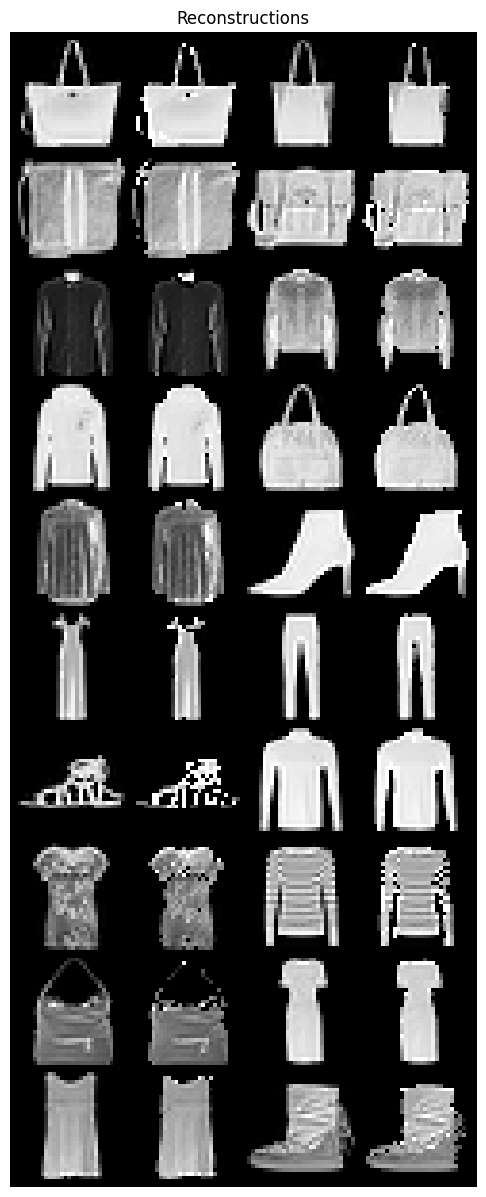


Validation bpd: 2.763

Validation bpd: 2.904

Validation bpd: 2.826

Validation bpd: 2.816

Validation bpd: 2.819

Validation bpd: 2.794

Validation bpd: 2.794

Validation bpd: 2.868

Validation bpd: 2.733

Validation bpd: 3.022

Validation bpd: 2.778

Validation bpd: 2.796

Validation bpd: 2.777

Validation bpd: 2.726

Validation bpd: 2.875

Validation bpd: 2.806

Validation bpd: 2.797

Validation bpd: 2.835

Validation bpd: 2.841

Validation bpd: 2.867

Validation bpd: 2.877

Validation bpd: 2.806

Validation bpd: 2.878

Validation bpd: 2.730

Validation bpd: 2.876

Validation bpd: 2.742

Validation bpd: 2.668

Validation bpd: 2.738

Validation bpd: 2.739

Validation bpd: 2.864

Validation bpd: 2.747

Validation bpd: 2.794

Validation bpd: 2.757

Validation bpd: 2.674

Validation bpd: 2.776

Validation bpd: 2.755

Validation bpd: 2.853

Validation bpd: 2.877

Validation bpd: 2.705

Validation bpd: 2.737

Validation bpd: 2.750

Validation bpd: 2.757

Validation bpd: 2.806

Validation

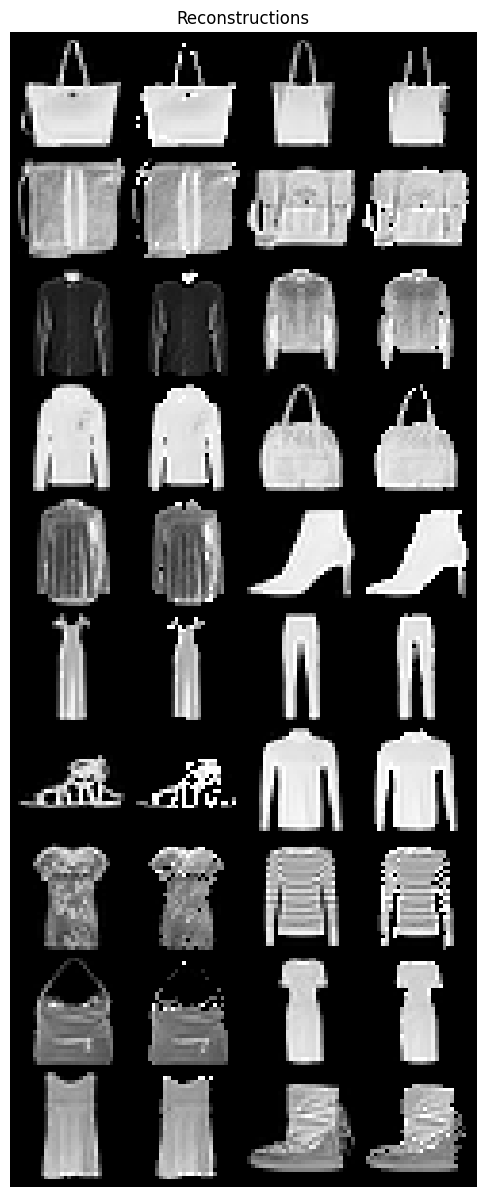


Validation bpd: 2.777

Validation bpd: 2.920

Validation bpd: 2.846

Validation bpd: 2.835

Validation bpd: 2.835

Validation bpd: 2.812

Validation bpd: 2.808

Validation bpd: 2.885

Validation bpd: 2.751

Validation bpd: 3.039

Validation bpd: 2.792

Validation bpd: 2.814

Validation bpd: 2.791

Validation bpd: 2.754

Validation bpd: 2.887

Validation bpd: 2.820

Validation bpd: 2.817

Validation bpd: 2.849

Validation bpd: 2.852

Validation bpd: 2.881

Validation bpd: 2.889

Validation bpd: 2.821

Validation bpd: 2.892

Validation bpd: 2.744

Validation bpd: 2.888

Validation bpd: 2.757

Validation bpd: 2.684

Validation bpd: 2.756

Validation bpd: 2.753

Validation bpd: 2.882

Validation bpd: 2.761

Validation bpd: 2.809

Validation bpd: 2.773

Validation bpd: 2.689

Validation bpd: 2.791

Validation bpd: 2.772

Validation bpd: 2.868

Validation bpd: 2.895

Validation bpd: 2.725

Validation bpd: 2.752

Validation bpd: 2.764

Validation bpd: 2.773

Validation bpd: 2.821

Validation

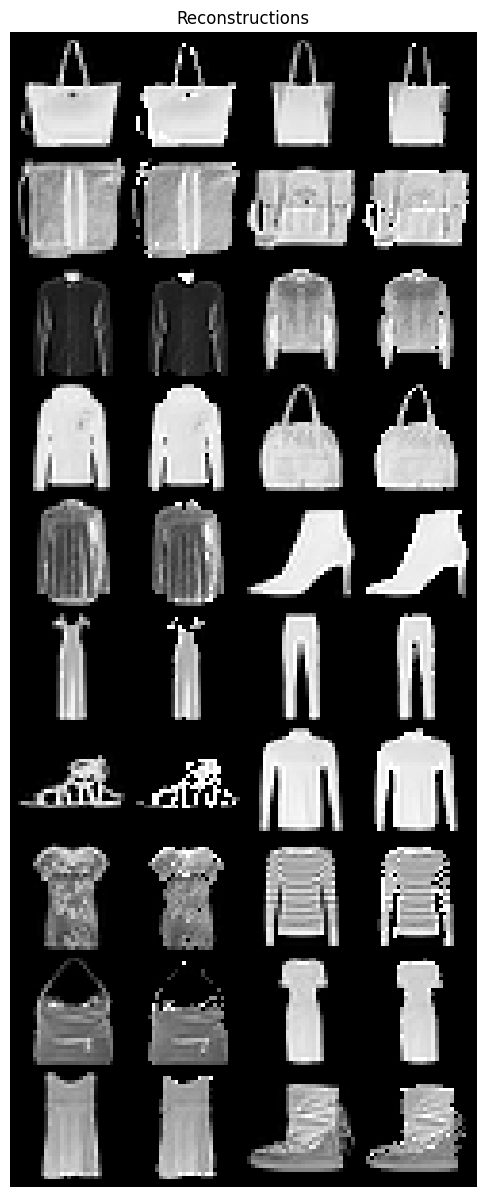


Validation bpd: 2.757

Validation bpd: 2.899

Validation bpd: 2.821

Validation bpd: 2.813

Validation bpd: 2.815

Validation bpd: 2.787

Validation bpd: 2.787

Validation bpd: 2.861

Validation bpd: 2.725

Validation bpd: 3.018

Validation bpd: 2.772

Validation bpd: 2.792

Validation bpd: 2.771

Validation bpd: 2.722

Validation bpd: 2.868

Validation bpd: 2.800

Validation bpd: 2.792

Validation bpd: 2.830

Validation bpd: 2.835

Validation bpd: 2.861

Validation bpd: 2.873

Validation bpd: 2.801

Validation bpd: 2.873

Validation bpd: 2.725

Validation bpd: 2.871

Validation bpd: 2.737

Validation bpd: 2.663

Validation bpd: 2.734

Validation bpd: 2.735

Validation bpd: 2.860

Validation bpd: 2.740

Validation bpd: 2.788

Validation bpd: 2.753

Validation bpd: 2.670

Validation bpd: 2.770

Validation bpd: 2.751

Validation bpd: 2.847

Validation bpd: 2.871

Validation bpd: 2.700

Validation bpd: 2.733

Validation bpd: 2.743

Validation bpd: 2.752

Validation bpd: 2.800

Validation

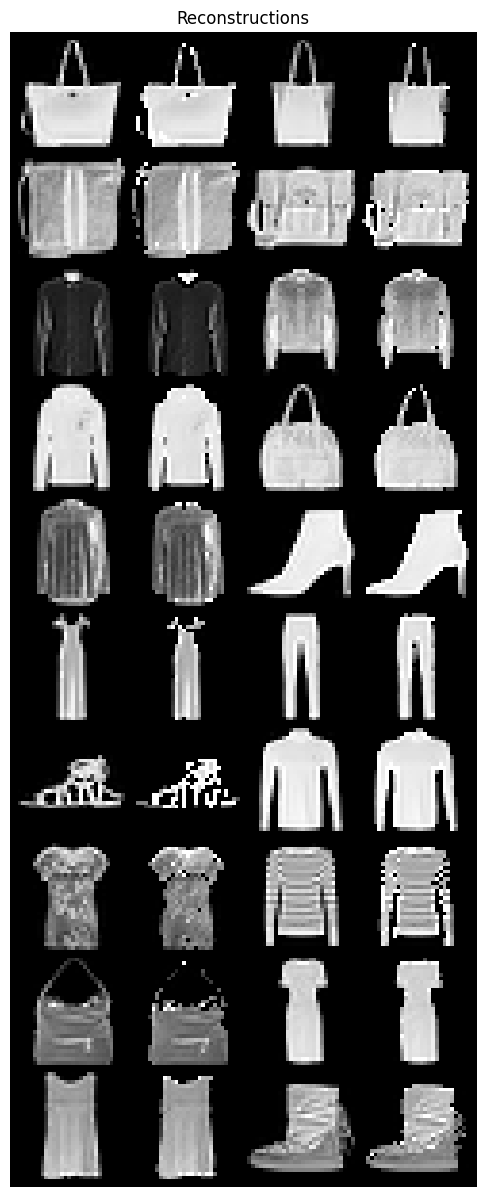


Validation bpd: 2.752

Validation bpd: 2.893

Validation bpd: 2.813

Validation bpd: 2.807

Validation bpd: 2.809

Validation bpd: 2.783

Validation bpd: 2.782

Validation bpd: 2.855

Validation bpd: 2.721

Validation bpd: 3.011

Validation bpd: 2.767

Validation bpd: 2.785

Validation bpd: 2.763

Validation bpd: 2.714

Validation bpd: 2.861

Validation bpd: 2.793

Validation bpd: 2.785

Validation bpd: 2.823

Validation bpd: 2.827

Validation bpd: 2.854

Validation bpd: 2.866

Validation bpd: 2.794

Validation bpd: 2.866

Validation bpd: 2.717

Validation bpd: 2.864

Validation bpd: 2.729

Validation bpd: 2.656

Validation bpd: 2.727

Validation bpd: 2.729

Validation bpd: 2.852

Validation bpd: 2.732

Validation bpd: 2.782

Validation bpd: 2.745

Validation bpd: 2.661

Validation bpd: 2.763

Validation bpd: 2.744

Validation bpd: 2.840

Validation bpd: 2.862

Validation bpd: 2.695

Validation bpd: 2.724

Validation bpd: 2.737

Validation bpd: 2.746

Validation bpd: 2.794

Validation

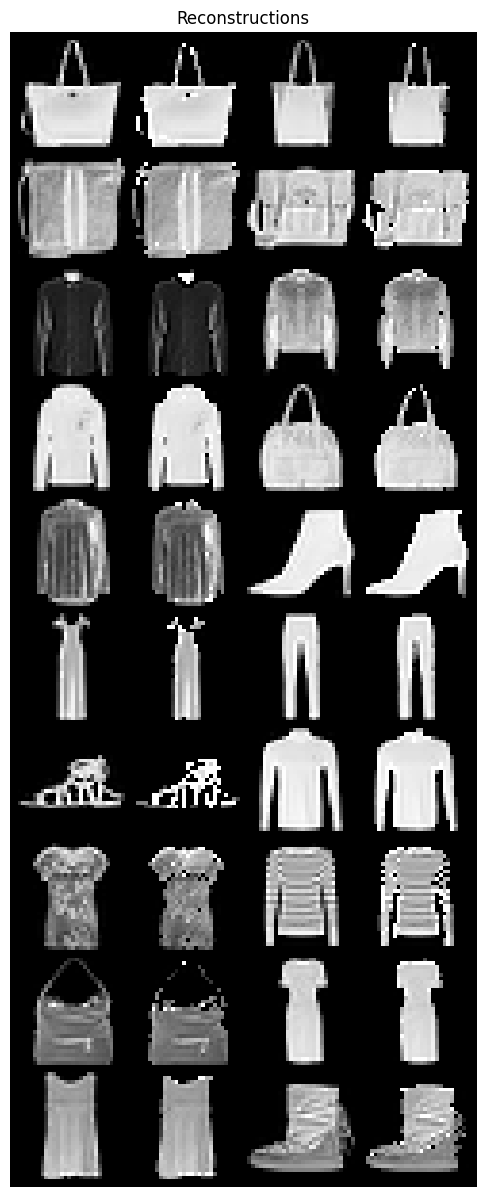


Validation bpd: 2.749

Validation bpd: 2.892

Validation bpd: 2.814

Validation bpd: 2.806

Validation bpd: 2.807

Validation bpd: 2.779

Validation bpd: 2.782

Validation bpd: 2.855

Validation bpd: 2.717

Validation bpd: 3.009

Validation bpd: 2.765

Validation bpd: 2.785

Validation bpd: 2.764

Validation bpd: 2.717

Validation bpd: 2.861

Validation bpd: 2.795

Validation bpd: 2.784

Validation bpd: 2.823

Validation bpd: 2.826

Validation bpd: 2.854

Validation bpd: 2.866

Validation bpd: 2.793

Validation bpd: 2.864

Validation bpd: 2.717

Validation bpd: 2.863

Validation bpd: 2.730

Validation bpd: 2.655

Validation bpd: 2.727

Validation bpd: 2.727

Validation bpd: 2.853

Validation bpd: 2.731

Validation bpd: 2.780

Validation bpd: 2.745

Validation bpd: 2.661

Validation bpd: 2.761

Validation bpd: 2.745

Validation bpd: 2.840

Validation bpd: 2.864

Validation bpd: 2.693

Validation bpd: 2.723

Validation bpd: 2.738

Validation bpd: 2.745

Validation bpd: 2.794

Validation

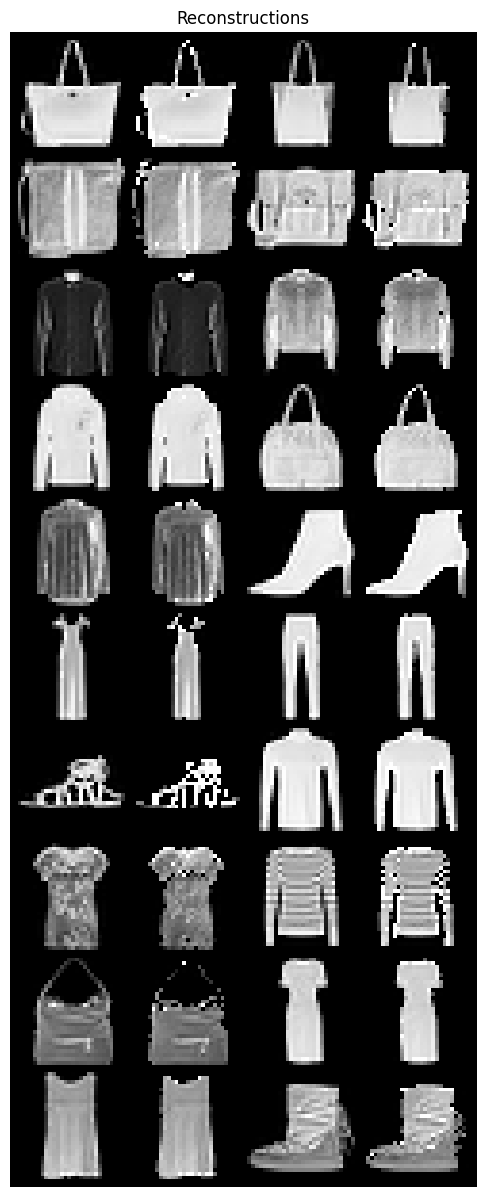


Validation bpd: 2.747

Validation bpd: 2.889

Validation bpd: 2.809

Validation bpd: 2.803

Validation bpd: 2.805

Validation bpd: 2.779

Validation bpd: 2.778

Validation bpd: 2.852

Validation bpd: 2.715

Validation bpd: 3.006

Validation bpd: 2.761

Validation bpd: 2.782

Validation bpd: 2.760

Validation bpd: 2.712

Validation bpd: 2.858

Validation bpd: 2.790

Validation bpd: 2.780

Validation bpd: 2.819

Validation bpd: 2.824

Validation bpd: 2.849

Validation bpd: 2.862

Validation bpd: 2.789

Validation bpd: 2.863

Validation bpd: 2.714

Validation bpd: 2.860

Validation bpd: 2.727

Validation bpd: 2.651

Validation bpd: 2.723

Validation bpd: 2.725

Validation bpd: 2.849

Validation bpd: 2.730

Validation bpd: 2.776

Validation bpd: 2.743

Validation bpd: 2.656

Validation bpd: 2.758

Validation bpd: 2.741

Validation bpd: 2.836

Validation bpd: 2.860

Validation bpd: 2.691

Validation bpd: 2.720

Validation bpd: 2.734

Validation bpd: 2.742

Validation bpd: 2.790

Validation

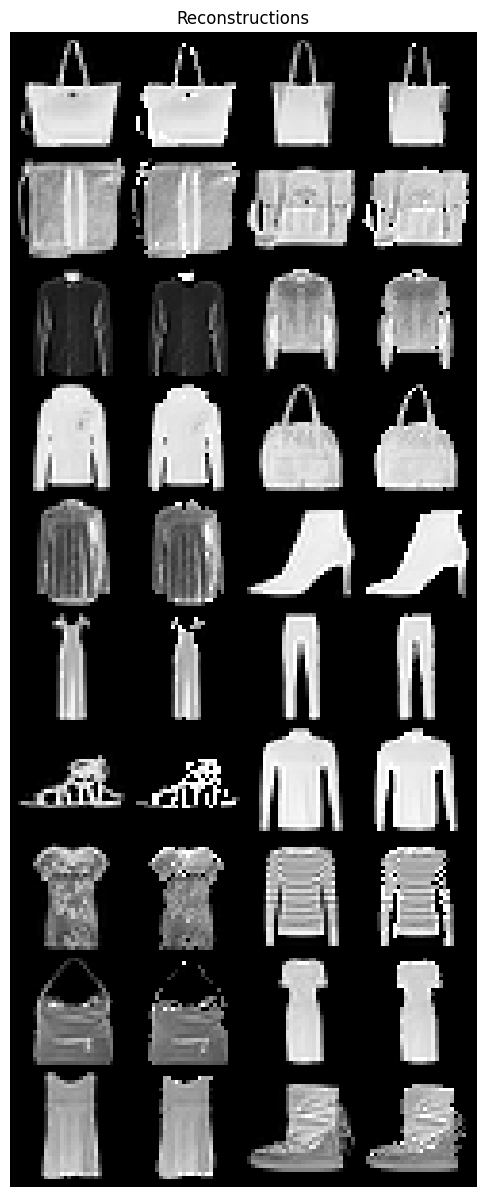


Validation bpd: 2.746

Validation bpd: 2.887

Validation bpd: 2.807

Validation bpd: 2.801

Validation bpd: 2.803

Validation bpd: 2.777

Validation bpd: 2.775

Validation bpd: 2.848

Validation bpd: 2.713

Validation bpd: 3.006

Validation bpd: 2.759

Validation bpd: 2.781

Validation bpd: 2.759

Validation bpd: 2.708

Validation bpd: 2.855

Validation bpd: 2.788

Validation bpd: 2.779

Validation bpd: 2.817

Validation bpd: 2.822

Validation bpd: 2.847

Validation bpd: 2.861

Validation bpd: 2.788

Validation bpd: 2.861

Validation bpd: 2.713

Validation bpd: 2.859

Validation bpd: 2.725

Validation bpd: 2.649

Validation bpd: 2.721

Validation bpd: 2.723

Validation bpd: 2.848

Validation bpd: 2.726

Validation bpd: 2.775

Validation bpd: 2.740

Validation bpd: 2.655

Validation bpd: 2.755

Validation bpd: 2.738

Validation bpd: 2.834

Validation bpd: 2.859

Validation bpd: 2.688

Validation bpd: 2.717

Validation bpd: 2.732

Validation bpd: 2.740

Validation bpd: 2.789

Validation

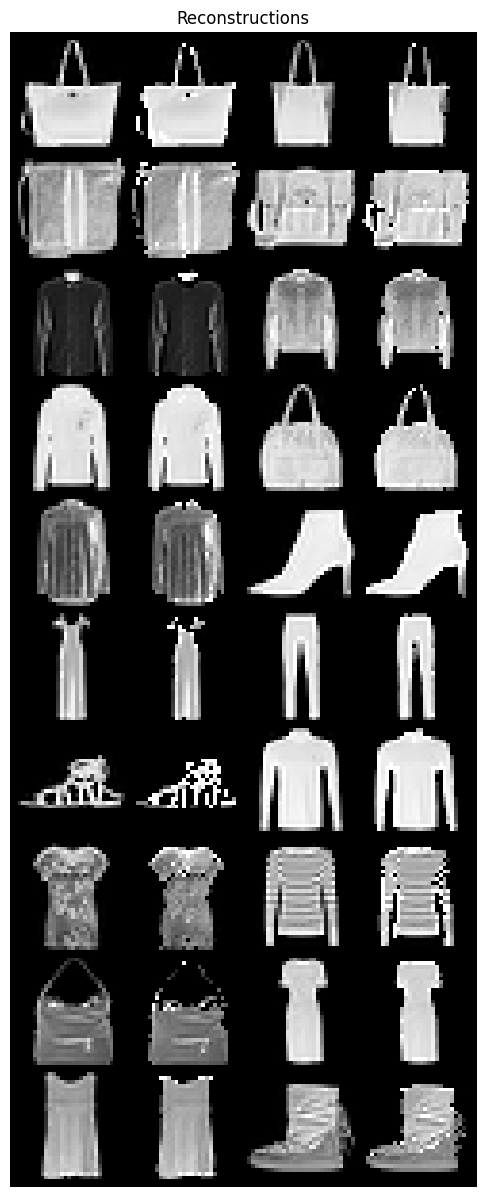


Validation bpd: 2.757

Validation bpd: 2.897

Validation bpd: 2.821

Validation bpd: 2.812

Validation bpd: 2.812

Validation bpd: 2.786

Validation bpd: 2.789

Validation bpd: 2.861

Validation bpd: 2.723

Validation bpd: 3.021

Validation bpd: 2.771

Validation bpd: 2.792

Validation bpd: 2.769

Validation bpd: 2.723

Validation bpd: 2.868

Validation bpd: 2.798

Validation bpd: 2.790

Validation bpd: 2.828

Validation bpd: 2.835

Validation bpd: 2.861

Validation bpd: 2.869

Validation bpd: 2.801

Validation bpd: 2.873

Validation bpd: 2.723

Validation bpd: 2.872

Validation bpd: 2.736

Validation bpd: 2.661

Validation bpd: 2.735

Validation bpd: 2.734

Validation bpd: 2.859

Validation bpd: 2.743

Validation bpd: 2.788

Validation bpd: 2.752

Validation bpd: 2.667

Validation bpd: 2.769

Validation bpd: 2.752

Validation bpd: 2.846

Validation bpd: 2.869

Validation bpd: 2.701

Validation bpd: 2.732

Validation bpd: 2.743

Validation bpd: 2.751

Validation bpd: 2.799

Validation

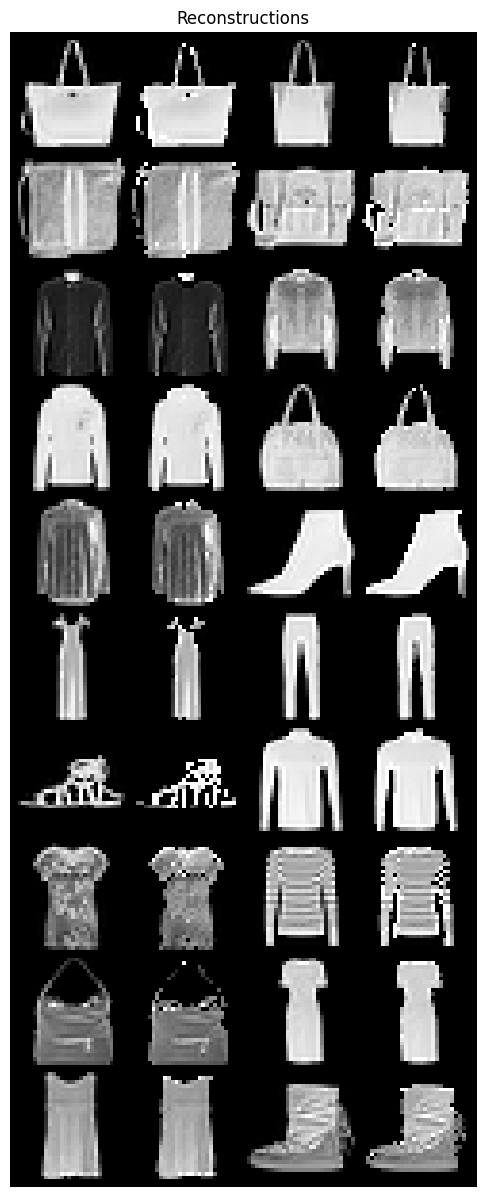


Validation bpd: 2.741

Validation bpd: 2.883

Validation bpd: 2.803

Validation bpd: 2.797

Validation bpd: 2.798

Validation bpd: 2.771

Validation bpd: 2.772

Validation bpd: 2.844

Validation bpd: 2.709

Validation bpd: 3.002

Validation bpd: 2.757

Validation bpd: 2.776

Validation bpd: 2.754

Validation bpd: 2.705

Validation bpd: 2.851

Validation bpd: 2.784

Validation bpd: 2.774

Validation bpd: 2.813

Validation bpd: 2.817

Validation bpd: 2.844

Validation bpd: 2.857

Validation bpd: 2.784

Validation bpd: 2.854

Validation bpd: 2.707

Validation bpd: 2.854

Validation bpd: 2.721

Validation bpd: 2.644

Validation bpd: 2.717

Validation bpd: 2.718

Validation bpd: 2.842

Validation bpd: 2.723

Validation bpd: 2.770

Validation bpd: 2.736

Validation bpd: 2.650

Validation bpd: 2.751

Validation bpd: 2.734

Validation bpd: 2.830

Validation bpd: 2.852

Validation bpd: 2.684

Validation bpd: 2.712

Validation bpd: 2.726

Validation bpd: 2.735

Validation bpd: 2.782

Validation

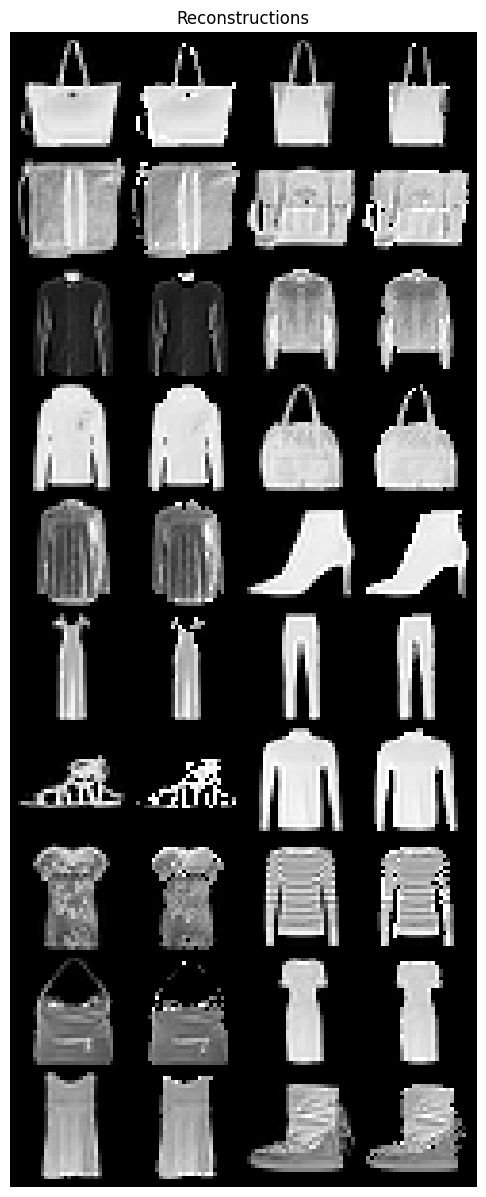


Validation bpd: 2.750

Validation bpd: 2.892

Validation bpd: 2.815

Validation bpd: 2.809

Validation bpd: 2.808

Validation bpd: 2.785

Validation bpd: 2.782

Validation bpd: 2.856

Validation bpd: 2.720

Validation bpd: 3.011

Validation bpd: 2.767

Validation bpd: 2.788

Validation bpd: 2.768

Validation bpd: 2.723

Validation bpd: 2.862

Validation bpd: 2.795

Validation bpd: 2.785

Validation bpd: 2.823

Validation bpd: 2.827

Validation bpd: 2.854

Validation bpd: 2.865

Validation bpd: 2.796

Validation bpd: 2.865

Validation bpd: 2.720

Validation bpd: 2.864

Validation bpd: 2.733

Validation bpd: 2.655

Validation bpd: 2.728

Validation bpd: 2.730

Validation bpd: 2.853

Validation bpd: 2.738

Validation bpd: 2.781

Validation bpd: 2.746

Validation bpd: 2.662

Validation bpd: 2.765

Validation bpd: 2.745

Validation bpd: 2.842

Validation bpd: 2.867

Validation bpd: 2.695

Validation bpd: 2.726

Validation bpd: 2.739

Validation bpd: 2.745

Validation bpd: 2.793

Validation

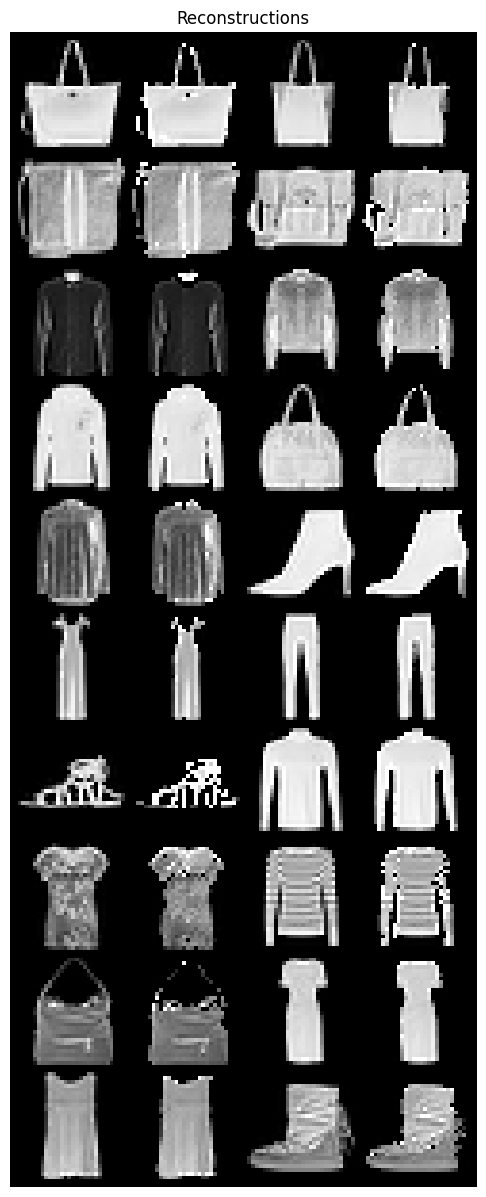


Validation bpd: 2.740

Validation bpd: 2.882

Validation bpd: 2.800

Validation bpd: 2.797

Validation bpd: 2.797

Validation bpd: 2.770

Validation bpd: 2.769

Validation bpd: 2.841

Validation bpd: 2.706

Validation bpd: 2.998

Validation bpd: 2.754

Validation bpd: 2.775

Validation bpd: 2.751

Validation bpd: 2.703

Validation bpd: 2.849

Validation bpd: 2.783

Validation bpd: 2.774

Validation bpd: 2.812

Validation bpd: 2.815

Validation bpd: 2.841

Validation bpd: 2.855

Validation bpd: 2.783

Validation bpd: 2.853

Validation bpd: 2.704

Validation bpd: 2.852

Validation bpd: 2.717

Validation bpd: 2.642

Validation bpd: 2.716

Validation bpd: 2.717

Validation bpd: 2.839

Validation bpd: 2.721

Validation bpd: 2.769

Validation bpd: 2.734

Validation bpd: 2.648

Validation bpd: 2.748

Validation bpd: 2.731

Validation bpd: 2.829

Validation bpd: 2.852

Validation bpd: 2.682

Validation bpd: 2.711

Validation bpd: 2.724

Validation bpd: 2.733

Validation bpd: 2.781

Validation

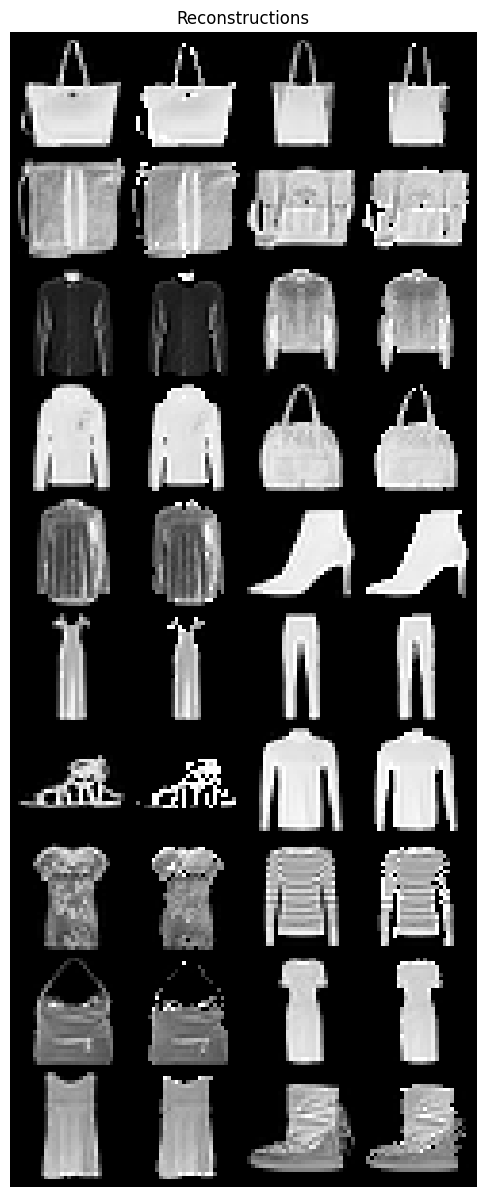


Validation bpd: 2.737

Validation bpd: 2.878

Validation bpd: 2.797

Validation bpd: 2.794

Validation bpd: 2.794

Validation bpd: 2.767

Validation bpd: 2.767

Validation bpd: 2.838

Validation bpd: 2.704

Validation bpd: 2.994

Validation bpd: 2.752

Validation bpd: 2.771

Validation bpd: 2.750

Validation bpd: 2.700

Validation bpd: 2.847

Validation bpd: 2.780

Validation bpd: 2.770

Validation bpd: 2.809

Validation bpd: 2.814

Validation bpd: 2.838

Validation bpd: 2.852

Validation bpd: 2.780

Validation bpd: 2.849

Validation bpd: 2.703

Validation bpd: 2.849

Validation bpd: 2.716

Validation bpd: 2.640

Validation bpd: 2.713

Validation bpd: 2.714

Validation bpd: 2.837

Validation bpd: 2.719

Validation bpd: 2.765

Validation bpd: 2.731

Validation bpd: 2.645

Validation bpd: 2.745

Validation bpd: 2.730

Validation bpd: 2.826

Validation bpd: 2.848

Validation bpd: 2.679

Validation bpd: 2.709

Validation bpd: 2.723

Validation bpd: 2.732

Validation bpd: 2.778

Validation

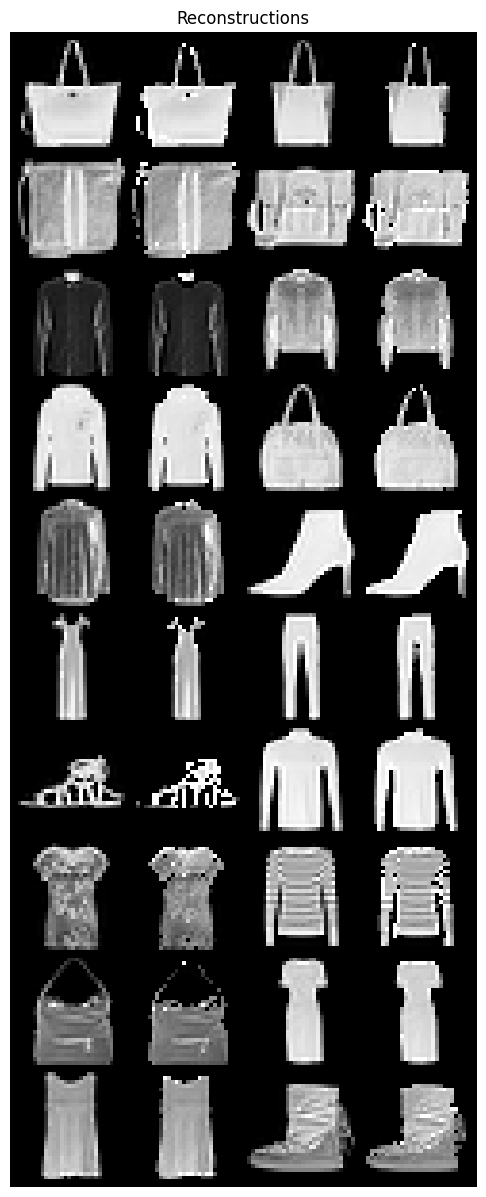


Validation bpd: 2.747

Validation bpd: 2.886

Validation bpd: 2.807

Validation bpd: 2.801

Validation bpd: 2.802

Validation bpd: 2.776

Validation bpd: 2.775

Validation bpd: 2.850

Validation bpd: 2.712

Validation bpd: 3.006

Validation bpd: 2.760

Validation bpd: 2.781

Validation bpd: 2.758

Validation bpd: 2.711

Validation bpd: 2.855

Validation bpd: 2.790

Validation bpd: 2.781

Validation bpd: 2.816

Validation bpd: 2.823

Validation bpd: 2.847

Validation bpd: 2.860

Validation bpd: 2.787

Validation bpd: 2.862

Validation bpd: 2.712

Validation bpd: 2.858

Validation bpd: 2.725

Validation bpd: 2.648

Validation bpd: 2.722

Validation bpd: 2.721

Validation bpd: 2.847

Validation bpd: 2.726

Validation bpd: 2.775

Validation bpd: 2.739

Validation bpd: 2.653

Validation bpd: 2.754

Validation bpd: 2.739

Validation bpd: 2.834

Validation bpd: 2.857

Validation bpd: 2.689

Validation bpd: 2.716

Validation bpd: 2.730

Validation bpd: 2.740

Validation bpd: 2.787

Validation

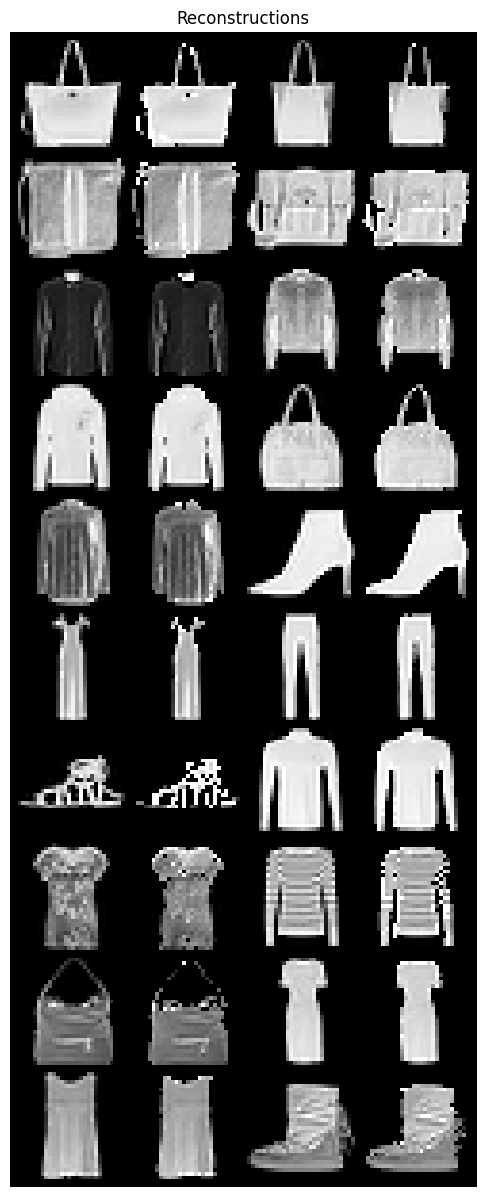


Validation bpd: 2.733

Validation bpd: 2.876

Validation bpd: 2.795

Validation bpd: 2.789

Validation bpd: 2.791

Validation bpd: 2.765

Validation bpd: 2.763

Validation bpd: 2.833

Validation bpd: 2.699

Validation bpd: 2.991

Validation bpd: 2.749

Validation bpd: 2.769

Validation bpd: 2.745

Validation bpd: 2.698

Validation bpd: 2.843

Validation bpd: 2.777

Validation bpd: 2.767

Validation bpd: 2.806

Validation bpd: 2.809

Validation bpd: 2.835

Validation bpd: 2.850

Validation bpd: 2.776

Validation bpd: 2.848

Validation bpd: 2.699

Validation bpd: 2.846

Validation bpd: 2.711

Validation bpd: 2.636

Validation bpd: 2.709

Validation bpd: 2.710

Validation bpd: 2.832

Validation bpd: 2.715

Validation bpd: 2.763

Validation bpd: 2.728

Validation bpd: 2.641

Validation bpd: 2.741

Validation bpd: 2.728

Validation bpd: 2.822

Validation bpd: 2.844

Validation bpd: 2.676

Validation bpd: 2.704

Validation bpd: 2.718

Validation bpd: 2.727

Validation bpd: 2.775

Validation

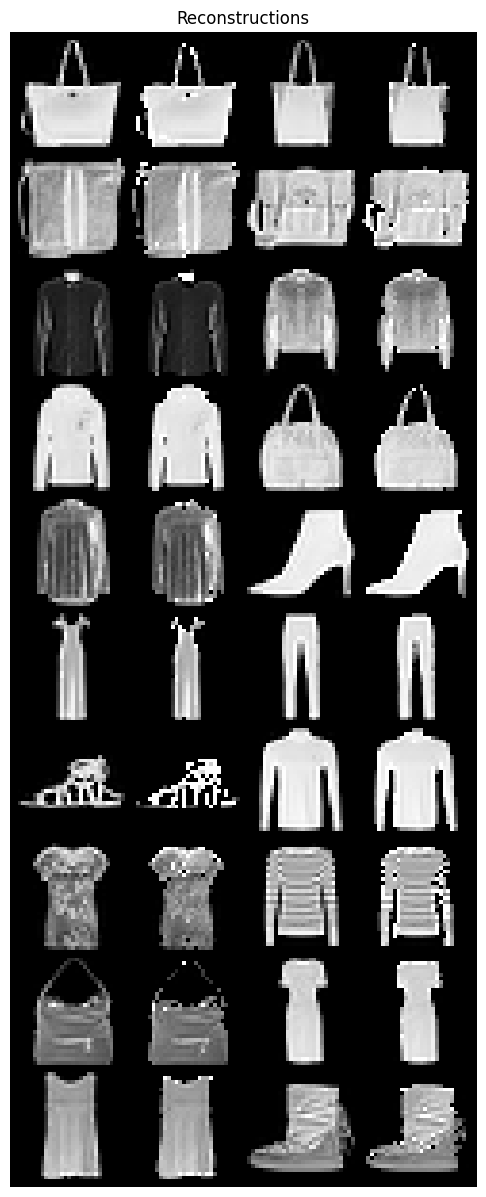


Validation bpd: 2.737

Validation bpd: 2.879

Validation bpd: 2.798

Validation bpd: 2.792

Validation bpd: 2.795

Validation bpd: 2.769

Validation bpd: 2.768

Validation bpd: 2.837

Validation bpd: 2.703

Validation bpd: 2.996

Validation bpd: 2.754

Validation bpd: 2.773

Validation bpd: 2.749

Validation bpd: 2.701

Validation bpd: 2.847

Validation bpd: 2.781

Validation bpd: 2.770

Validation bpd: 2.810

Validation bpd: 2.813

Validation bpd: 2.840

Validation bpd: 2.853

Validation bpd: 2.780

Validation bpd: 2.851

Validation bpd: 2.704

Validation bpd: 2.850

Validation bpd: 2.715

Validation bpd: 2.639

Validation bpd: 2.714

Validation bpd: 2.715

Validation bpd: 2.837

Validation bpd: 2.719

Validation bpd: 2.767

Validation bpd: 2.732

Validation bpd: 2.646

Validation bpd: 2.745

Validation bpd: 2.733

Validation bpd: 2.827

Validation bpd: 2.849

Validation bpd: 2.680

Validation bpd: 2.708

Validation bpd: 2.723

Validation bpd: 2.732

Validation bpd: 2.780

Validation

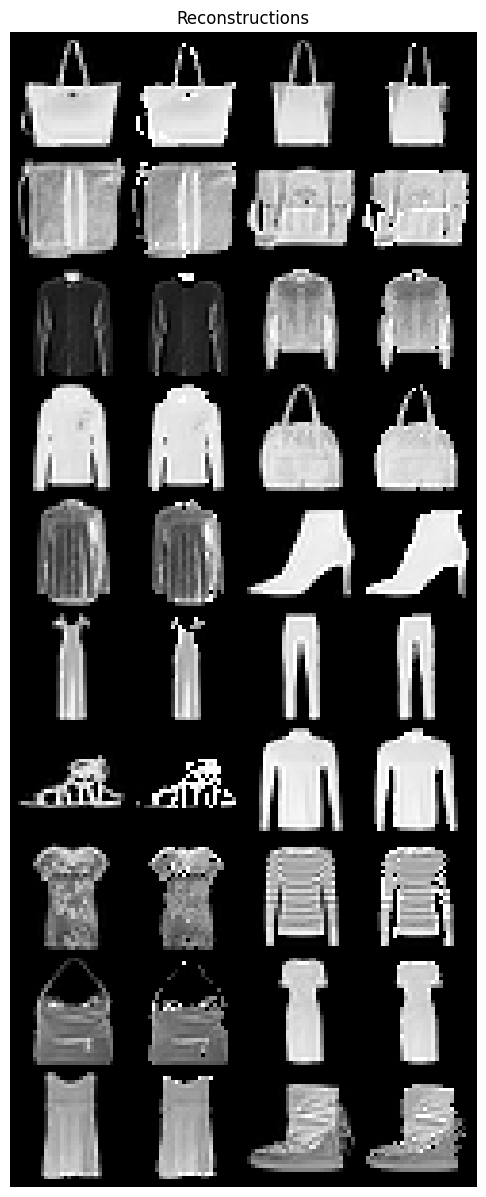


Validation bpd: 2.733

Validation bpd: 2.878

Validation bpd: 2.798

Validation bpd: 2.791

Validation bpd: 2.792

Validation bpd: 2.765

Validation bpd: 2.767

Validation bpd: 2.836

Validation bpd: 2.699

Validation bpd: 2.992

Validation bpd: 2.752

Validation bpd: 2.771

Validation bpd: 2.747

Validation bpd: 2.699

Validation bpd: 2.845

Validation bpd: 2.779

Validation bpd: 2.767

Validation bpd: 2.808

Validation bpd: 2.812

Validation bpd: 2.838

Validation bpd: 2.852

Validation bpd: 2.779

Validation bpd: 2.850

Validation bpd: 2.702

Validation bpd: 2.847

Validation bpd: 2.712

Validation bpd: 2.637

Validation bpd: 2.712

Validation bpd: 2.712

Validation bpd: 2.834

Validation bpd: 2.717

Validation bpd: 2.765

Validation bpd: 2.729

Validation bpd: 2.643

Validation bpd: 2.745

Validation bpd: 2.731

Validation bpd: 2.823

Validation bpd: 2.846

Validation bpd: 2.678

Validation bpd: 2.708

Validation bpd: 2.722

Validation bpd: 2.730

Validation bpd: 2.777

Validation

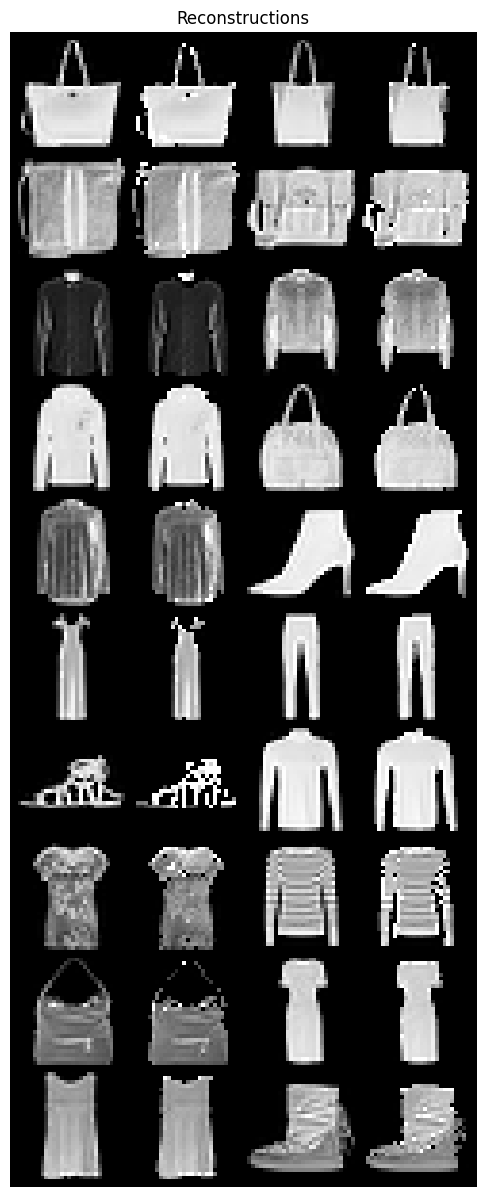


Validation bpd: 2.734

Validation bpd: 2.876

Validation bpd: 2.795

Validation bpd: 2.787

Validation bpd: 2.790

Validation bpd: 2.765

Validation bpd: 2.764

Validation bpd: 2.835

Validation bpd: 2.698

Validation bpd: 2.992

Validation bpd: 2.748

Validation bpd: 2.769

Validation bpd: 2.746

Validation bpd: 2.696

Validation bpd: 2.842

Validation bpd: 2.775

Validation bpd: 2.767

Validation bpd: 2.805

Validation bpd: 2.810

Validation bpd: 2.835

Validation bpd: 2.850

Validation bpd: 2.777

Validation bpd: 2.846

Validation bpd: 2.698

Validation bpd: 2.845

Validation bpd: 2.710

Validation bpd: 2.637

Validation bpd: 2.708

Validation bpd: 2.708

Validation bpd: 2.832

Validation bpd: 2.714

Validation bpd: 2.762

Validation bpd: 2.727

Validation bpd: 2.641

Validation bpd: 2.741

Validation bpd: 2.727

Validation bpd: 2.821

Validation bpd: 2.844

Validation bpd: 2.675

Validation bpd: 2.704

Validation bpd: 2.719

Validation bpd: 2.727

Validation bpd: 2.774

Validation

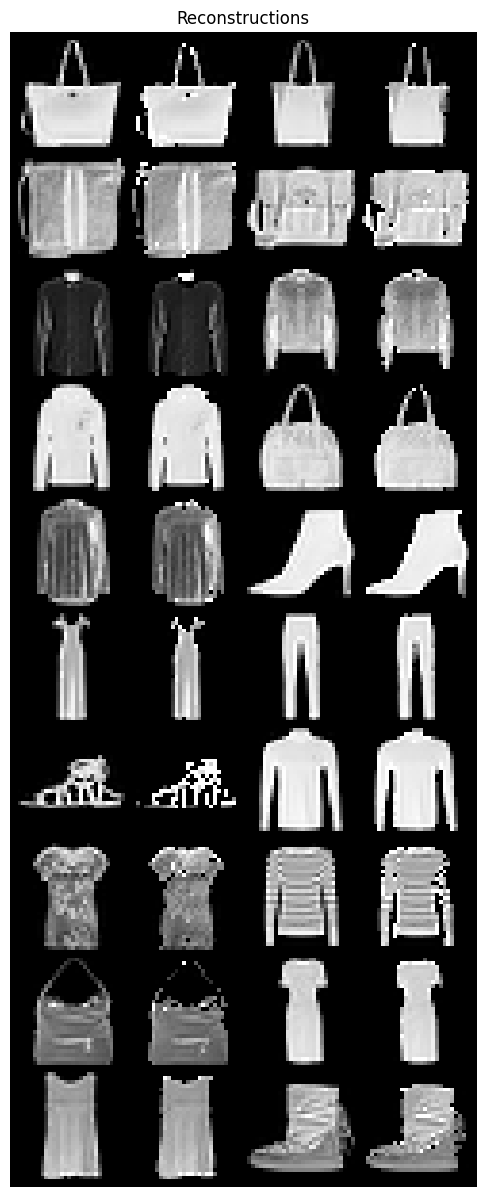


Validation bpd: 2.733

Validation bpd: 2.873

Validation bpd: 2.794

Validation bpd: 2.785

Validation bpd: 2.791

Validation bpd: 2.763

Validation bpd: 2.765

Validation bpd: 2.834

Validation bpd: 2.698

Validation bpd: 2.991

Validation bpd: 2.749

Validation bpd: 2.769

Validation bpd: 2.745

Validation bpd: 2.696

Validation bpd: 2.843

Validation bpd: 2.776

Validation bpd: 2.765

Validation bpd: 2.806

Validation bpd: 2.810

Validation bpd: 2.835

Validation bpd: 2.850

Validation bpd: 2.776

Validation bpd: 2.847

Validation bpd: 2.699

Validation bpd: 2.846

Validation bpd: 2.711

Validation bpd: 2.635

Validation bpd: 2.708

Validation bpd: 2.712

Validation bpd: 2.833

Validation bpd: 2.716

Validation bpd: 2.763

Validation bpd: 2.727

Validation bpd: 2.641

Validation bpd: 2.741

Validation bpd: 2.727

Validation bpd: 2.822

Validation bpd: 2.845

Validation bpd: 2.675

Validation bpd: 2.704

Validation bpd: 2.719

Validation bpd: 2.727

Validation bpd: 2.775

Validation

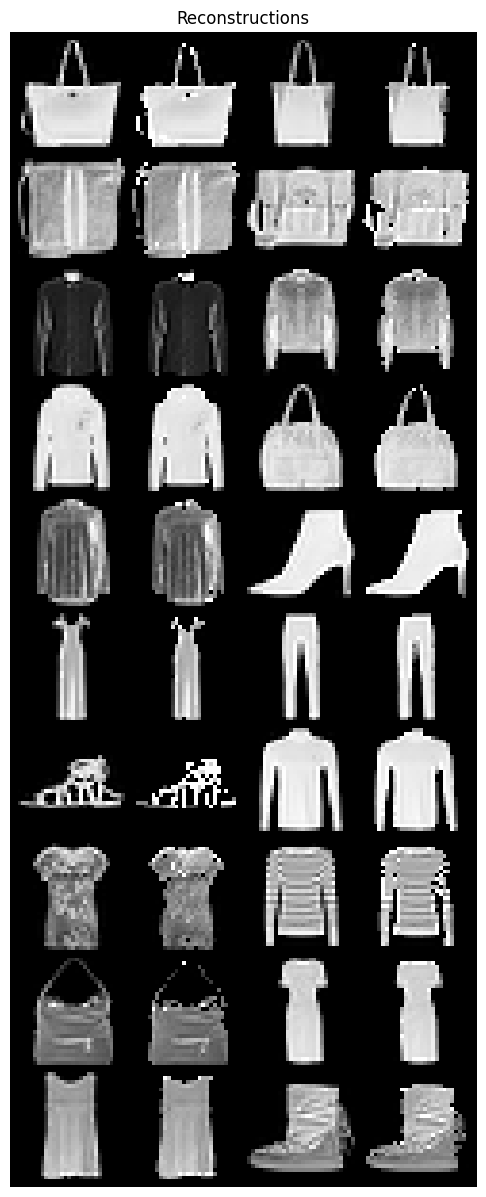


Validation bpd: 2.729

Validation bpd: 2.871

Validation bpd: 2.788

Validation bpd: 2.782

Validation bpd: 2.786

Validation bpd: 2.760

Validation bpd: 2.759

Validation bpd: 2.829

Validation bpd: 2.694

Validation bpd: 2.985

Validation bpd: 2.744

Validation bpd: 2.765

Validation bpd: 2.740

Validation bpd: 2.690

Validation bpd: 2.838

Validation bpd: 2.771

Validation bpd: 2.761

Validation bpd: 2.800

Validation bpd: 2.803

Validation bpd: 2.829

Validation bpd: 2.845

Validation bpd: 2.772

Validation bpd: 2.842

Validation bpd: 2.694

Validation bpd: 2.841

Validation bpd: 2.706

Validation bpd: 2.631

Validation bpd: 2.703

Validation bpd: 2.705

Validation bpd: 2.828

Validation bpd: 2.709

Validation bpd: 2.758

Validation bpd: 2.722

Validation bpd: 2.635

Validation bpd: 2.735

Validation bpd: 2.723

Validation bpd: 2.816

Validation bpd: 2.839

Validation bpd: 2.671

Validation bpd: 2.698

Validation bpd: 2.712

Validation bpd: 2.724

Validation bpd: 2.770

Validation

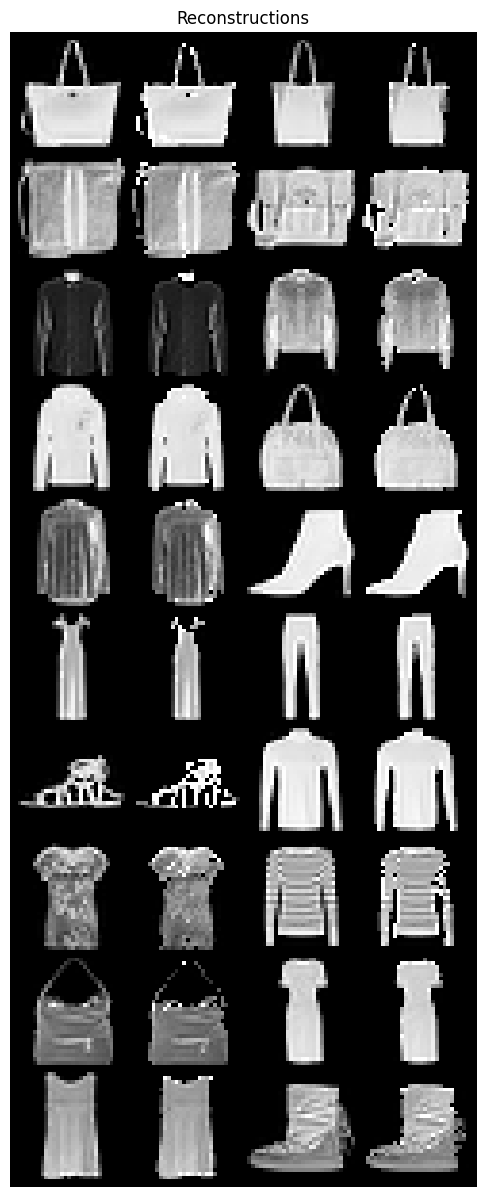


Validation bpd: 2.730

Validation bpd: 2.874

Validation bpd: 2.791

Validation bpd: 2.786

Validation bpd: 2.789

Validation bpd: 2.764

Validation bpd: 2.762

Validation bpd: 2.833

Validation bpd: 2.697

Validation bpd: 2.988

Validation bpd: 2.746

Validation bpd: 2.764

Validation bpd: 2.744

Validation bpd: 2.695

Validation bpd: 2.841

Validation bpd: 2.775

Validation bpd: 2.763

Validation bpd: 2.805

Validation bpd: 2.808

Validation bpd: 2.833

Validation bpd: 2.847

Validation bpd: 2.776

Validation bpd: 2.846

Validation bpd: 2.699

Validation bpd: 2.845

Validation bpd: 2.709

Validation bpd: 2.636

Validation bpd: 2.705

Validation bpd: 2.710

Validation bpd: 2.830

Validation bpd: 2.713

Validation bpd: 2.760

Validation bpd: 2.726

Validation bpd: 2.639

Validation bpd: 2.742

Validation bpd: 2.725

Validation bpd: 2.820

Validation bpd: 2.841

Validation bpd: 2.673

Validation bpd: 2.707

Validation bpd: 2.718

Validation bpd: 2.724

Validation bpd: 2.773

Validation

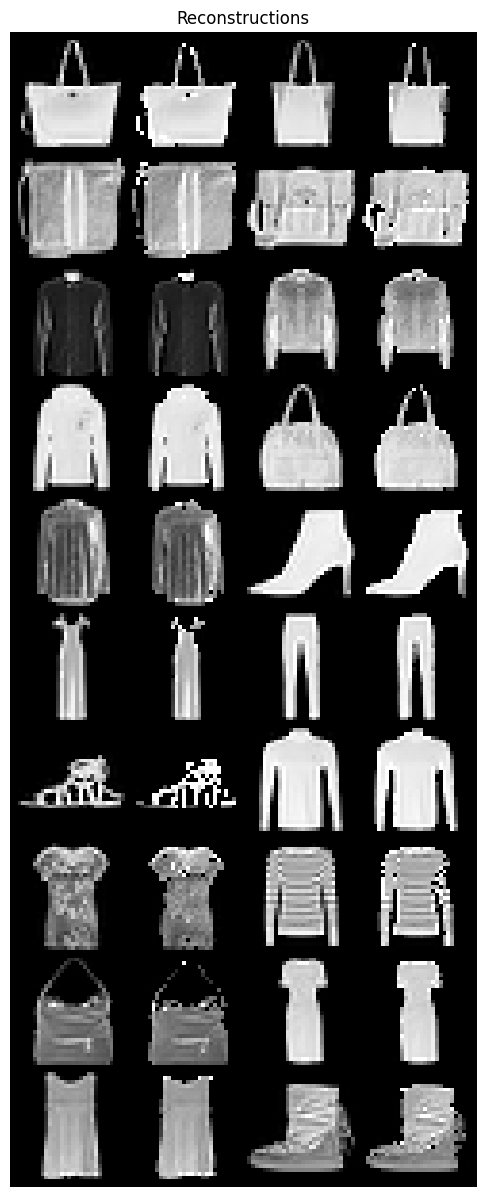


Validation bpd: 2.729

Validation bpd: 2.869

Validation bpd: 2.789

Validation bpd: 2.783

Validation bpd: 2.786

Validation bpd: 2.760

Validation bpd: 2.758

Validation bpd: 2.829

Validation bpd: 2.695

Validation bpd: 2.985

Validation bpd: 2.743

Validation bpd: 2.766

Validation bpd: 2.740

Validation bpd: 2.693

Validation bpd: 2.839

Validation bpd: 2.773

Validation bpd: 2.762

Validation bpd: 2.802

Validation bpd: 2.807

Validation bpd: 2.831

Validation bpd: 2.846

Validation bpd: 2.772

Validation bpd: 2.841

Validation bpd: 2.695

Validation bpd: 2.841

Validation bpd: 2.706

Validation bpd: 2.633

Validation bpd: 2.705

Validation bpd: 2.706

Validation bpd: 2.828

Validation bpd: 2.712

Validation bpd: 2.758

Validation bpd: 2.723

Validation bpd: 2.636

Validation bpd: 2.735

Validation bpd: 2.723

Validation bpd: 2.816

Validation bpd: 2.841

Validation bpd: 2.671

Validation bpd: 2.700

Validation bpd: 2.714

Validation bpd: 2.724

Validation bpd: 2.770

Validation

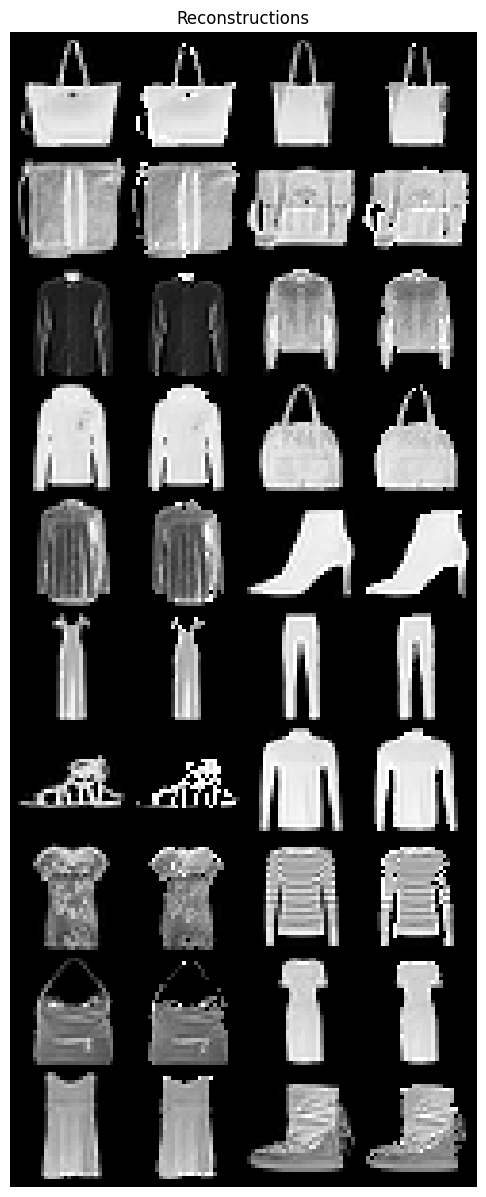


Validation bpd: 2.727

Validation bpd: 2.869

Validation bpd: 2.786

Validation bpd: 2.780

Validation bpd: 2.784

Validation bpd: 2.758

Validation bpd: 2.755

Validation bpd: 2.824

Validation bpd: 2.691

Validation bpd: 2.983

Validation bpd: 2.741

Validation bpd: 2.760

Validation bpd: 2.737

Validation bpd: 2.688

Validation bpd: 2.834

Validation bpd: 2.768

Validation bpd: 2.757

Validation bpd: 2.798

Validation bpd: 2.801

Validation bpd: 2.827

Validation bpd: 2.843

Validation bpd: 2.768

Validation bpd: 2.839

Validation bpd: 2.692

Validation bpd: 2.838

Validation bpd: 2.702

Validation bpd: 2.629

Validation bpd: 2.699

Validation bpd: 2.702

Validation bpd: 2.823

Validation bpd: 2.706

Validation bpd: 2.754

Validation bpd: 2.719

Validation bpd: 2.633

Validation bpd: 2.732

Validation bpd: 2.720

Validation bpd: 2.814

Validation bpd: 2.836

Validation bpd: 2.668

Validation bpd: 2.694

Validation bpd: 2.710

Validation bpd: 2.719

Validation bpd: 2.767

Validation

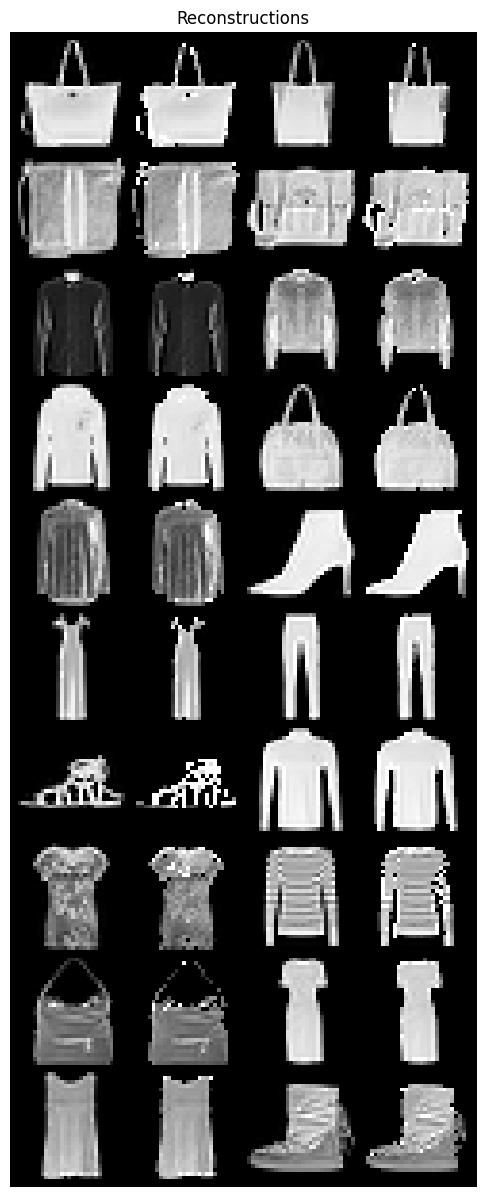


Validation bpd: 2.729

Validation bpd: 2.871

Validation bpd: 2.790

Validation bpd: 2.784

Validation bpd: 2.787

Validation bpd: 2.761

Validation bpd: 2.759

Validation bpd: 2.829

Validation bpd: 2.693

Validation bpd: 2.987

Validation bpd: 2.743

Validation bpd: 2.765

Validation bpd: 2.740

Validation bpd: 2.693

Validation bpd: 2.840

Validation bpd: 2.773

Validation bpd: 2.763

Validation bpd: 2.800

Validation bpd: 2.805

Validation bpd: 2.832

Validation bpd: 2.847

Validation bpd: 2.772

Validation bpd: 2.843

Validation bpd: 2.696

Validation bpd: 2.843

Validation bpd: 2.707

Validation bpd: 2.632

Validation bpd: 2.704

Validation bpd: 2.705

Validation bpd: 2.829

Validation bpd: 2.708

Validation bpd: 2.759

Validation bpd: 2.722

Validation bpd: 2.636

Validation bpd: 2.736

Validation bpd: 2.725

Validation bpd: 2.817

Validation bpd: 2.839

Validation bpd: 2.671

Validation bpd: 2.698

Validation bpd: 2.714

Validation bpd: 2.723

Validation bpd: 2.771

Validation

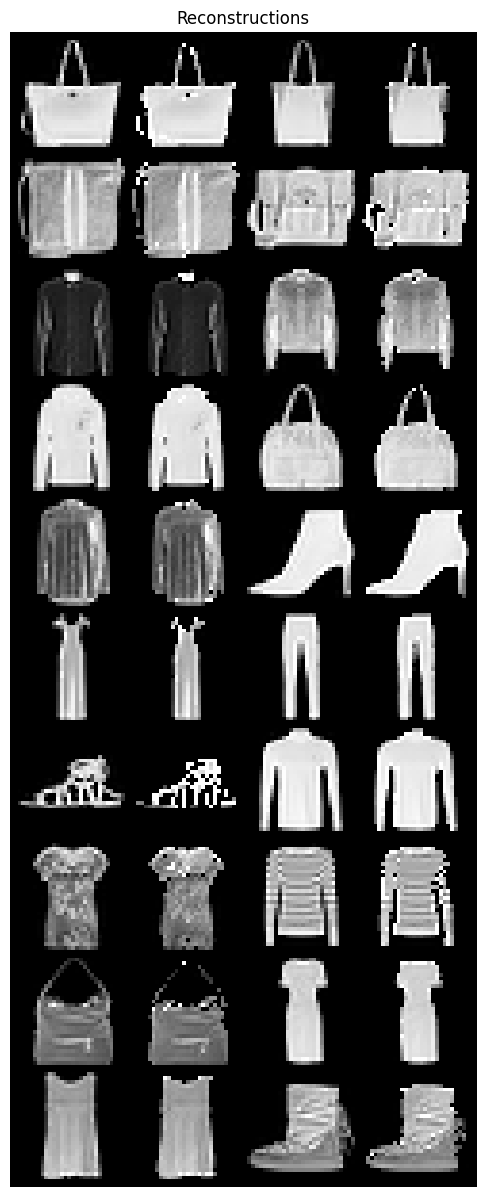


Validation bpd: 2.725

Validation bpd: 2.865

Validation bpd: 2.784

Validation bpd: 2.779

Validation bpd: 2.783

Validation bpd: 2.756

Validation bpd: 2.754

Validation bpd: 2.824

Validation bpd: 2.689

Validation bpd: 2.981

Validation bpd: 2.739

Validation bpd: 2.758

Validation bpd: 2.735

Validation bpd: 2.685

Validation bpd: 2.833

Validation bpd: 2.767

Validation bpd: 2.756

Validation bpd: 2.797

Validation bpd: 2.799

Validation bpd: 2.826

Validation bpd: 2.841

Validation bpd: 2.768

Validation bpd: 2.837

Validation bpd: 2.689

Validation bpd: 2.837

Validation bpd: 2.703

Validation bpd: 2.627

Validation bpd: 2.696

Validation bpd: 2.702

Validation bpd: 2.821

Validation bpd: 2.703

Validation bpd: 2.753

Validation bpd: 2.717

Validation bpd: 2.630

Validation bpd: 2.732

Validation bpd: 2.718

Validation bpd: 2.812

Validation bpd: 2.832

Validation bpd: 2.665

Validation bpd: 2.692

Validation bpd: 2.712

Validation bpd: 2.717

Validation bpd: 2.765

Validation

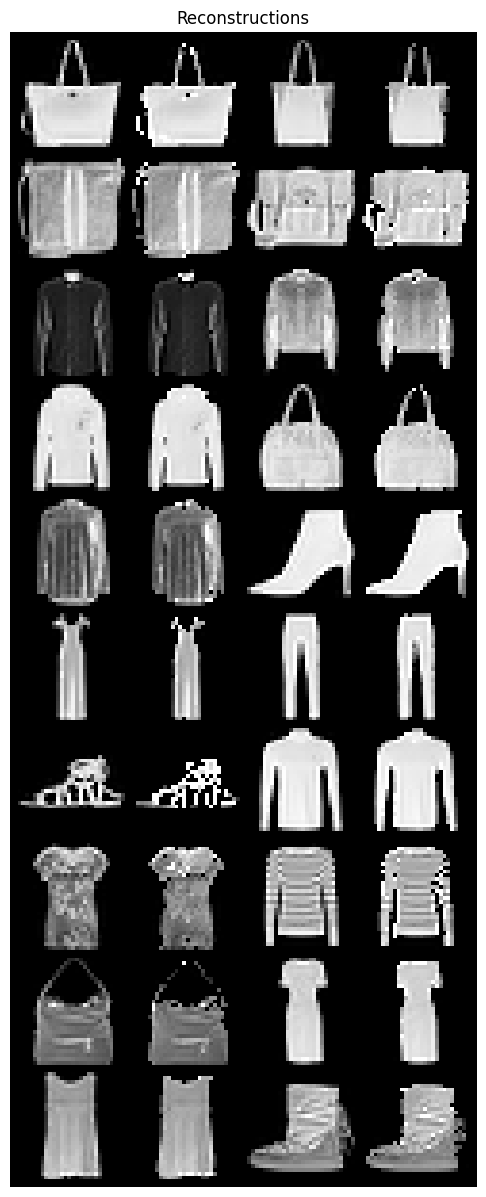


Validation bpd: 2.723

Validation bpd: 2.864

Validation bpd: 2.782

Validation bpd: 2.777

Validation bpd: 2.780

Validation bpd: 2.753

Validation bpd: 2.751

Validation bpd: 2.821

Validation bpd: 2.687

Validation bpd: 2.977

Validation bpd: 2.737

Validation bpd: 2.757

Validation bpd: 2.732

Validation bpd: 2.685

Validation bpd: 2.831

Validation bpd: 2.765

Validation bpd: 2.754

Validation bpd: 2.795

Validation bpd: 2.798

Validation bpd: 2.824

Validation bpd: 2.838

Validation bpd: 2.764

Validation bpd: 2.836

Validation bpd: 2.688

Validation bpd: 2.835

Validation bpd: 2.698

Validation bpd: 2.624

Validation bpd: 2.696

Validation bpd: 2.699

Validation bpd: 2.820

Validation bpd: 2.701

Validation bpd: 2.751

Validation bpd: 2.716

Validation bpd: 2.630

Validation bpd: 2.728

Validation bpd: 2.717

Validation bpd: 2.810

Validation bpd: 2.830

Validation bpd: 2.664

Validation bpd: 2.691

Validation bpd: 2.706

Validation bpd: 2.717

Validation bpd: 2.764

Validation

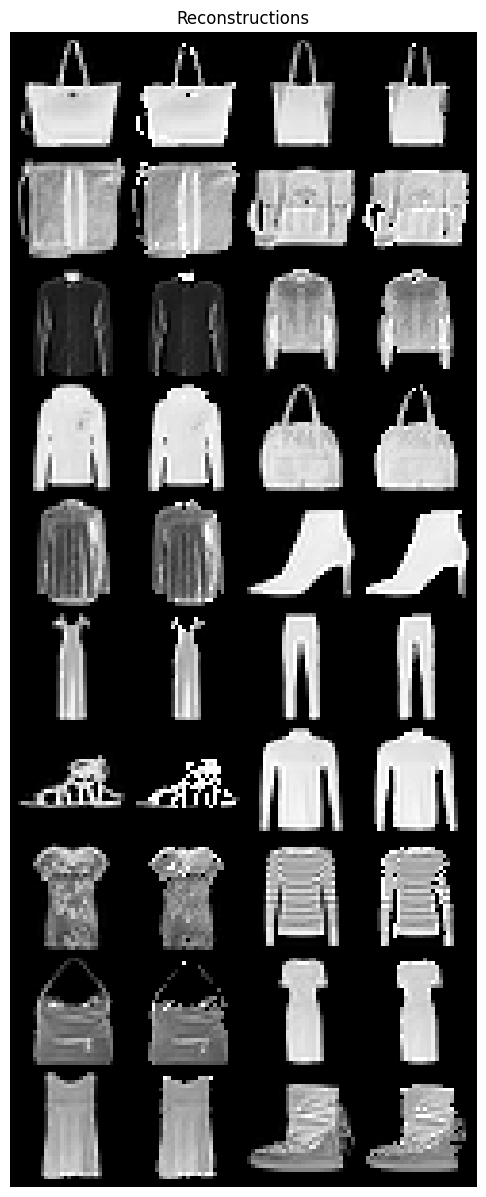


Validation bpd: 2.726

Validation bpd: 2.867

Validation bpd: 2.787

Validation bpd: 2.779

Validation bpd: 2.784

Validation bpd: 2.756

Validation bpd: 2.758

Validation bpd: 2.827

Validation bpd: 2.692

Validation bpd: 2.985

Validation bpd: 2.742

Validation bpd: 2.761

Validation bpd: 2.738

Validation bpd: 2.689

Validation bpd: 2.836

Validation bpd: 2.770

Validation bpd: 2.758

Validation bpd: 2.799

Validation bpd: 2.804

Validation bpd: 2.830

Validation bpd: 2.844

Validation bpd: 2.771

Validation bpd: 2.840

Validation bpd: 2.692

Validation bpd: 2.840

Validation bpd: 2.702

Validation bpd: 2.629

Validation bpd: 2.701

Validation bpd: 2.704

Validation bpd: 2.824

Validation bpd: 2.709

Validation bpd: 2.757

Validation bpd: 2.720

Validation bpd: 2.635

Validation bpd: 2.734

Validation bpd: 2.722

Validation bpd: 2.815

Validation bpd: 2.837

Validation bpd: 2.668

Validation bpd: 2.699

Validation bpd: 2.713

Validation bpd: 2.720

Validation bpd: 2.768

Validation

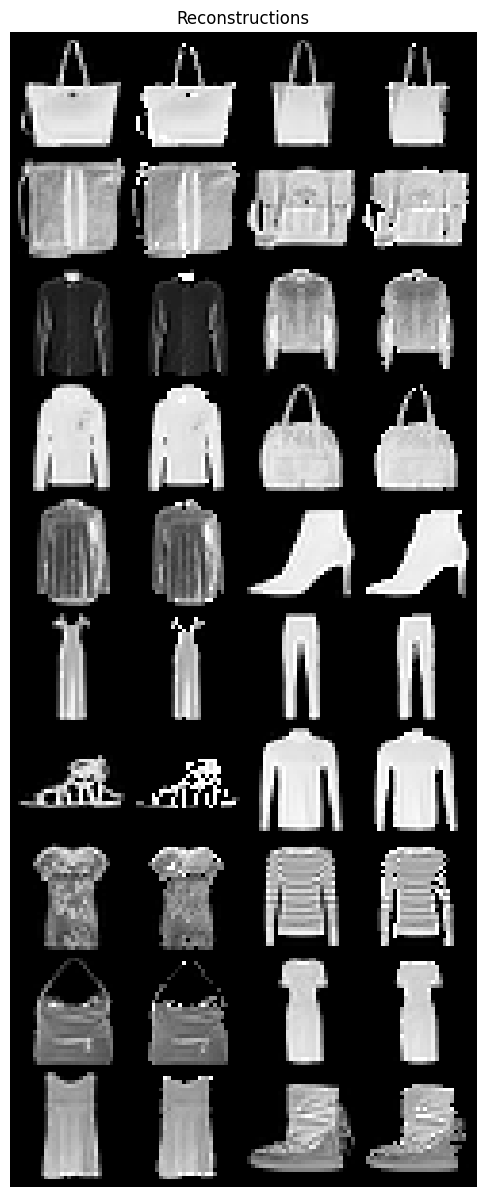


Validation bpd: 2.722

Validation bpd: 2.864

Validation bpd: 2.780

Validation bpd: 2.775

Validation bpd: 2.780

Validation bpd: 2.753

Validation bpd: 2.750

Validation bpd: 2.820

Validation bpd: 2.686

Validation bpd: 2.977

Validation bpd: 2.737

Validation bpd: 2.757

Validation bpd: 2.733

Validation bpd: 2.685

Validation bpd: 2.830

Validation bpd: 2.764

Validation bpd: 2.754

Validation bpd: 2.794

Validation bpd: 2.796

Validation bpd: 2.823

Validation bpd: 2.838

Validation bpd: 2.764

Validation bpd: 2.836

Validation bpd: 2.687

Validation bpd: 2.834

Validation bpd: 2.697

Validation bpd: 2.623

Validation bpd: 2.695

Validation bpd: 2.697

Validation bpd: 2.819

Validation bpd: 2.700

Validation bpd: 2.752

Validation bpd: 2.714

Validation bpd: 2.629

Validation bpd: 2.726

Validation bpd: 2.716

Validation bpd: 2.810

Validation bpd: 2.831

Validation bpd: 2.662

Validation bpd: 2.690

Validation bpd: 2.706

Validation bpd: 2.715

Validation bpd: 2.763

Validation

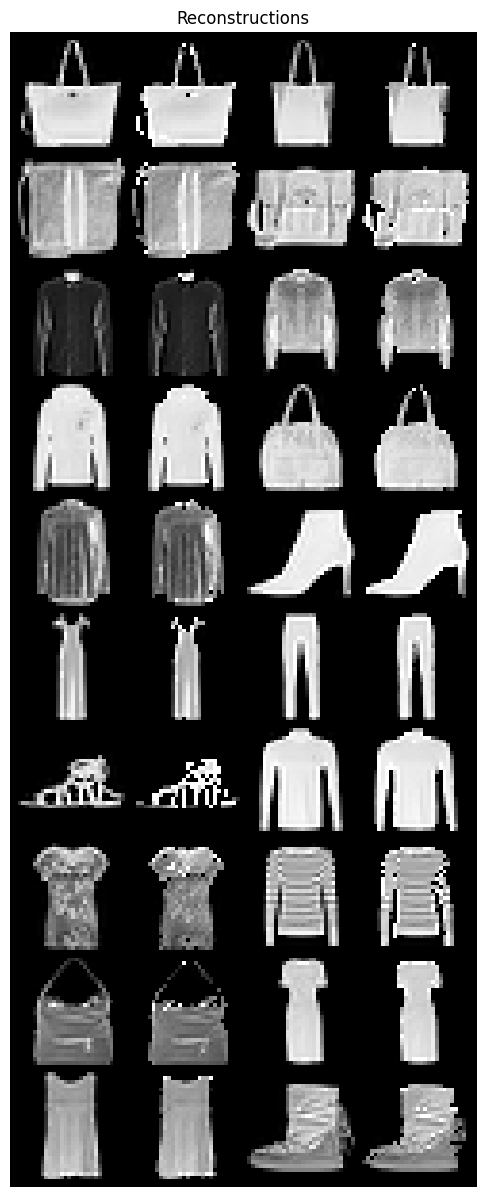


Validation bpd: 2.722

Validation bpd: 2.865

Validation bpd: 2.780

Validation bpd: 2.777

Validation bpd: 2.781

Validation bpd: 2.755

Validation bpd: 2.750

Validation bpd: 2.822

Validation bpd: 2.687

Validation bpd: 2.978

Validation bpd: 2.738

Validation bpd: 2.758

Validation bpd: 2.732

Validation bpd: 2.684

Validation bpd: 2.830

Validation bpd: 2.766

Validation bpd: 2.755

Validation bpd: 2.794

Validation bpd: 2.797

Validation bpd: 2.822

Validation bpd: 2.839

Validation bpd: 2.765

Validation bpd: 2.835

Validation bpd: 2.689

Validation bpd: 2.835

Validation bpd: 2.699

Validation bpd: 2.624

Validation bpd: 2.697

Validation bpd: 2.699

Validation bpd: 2.820

Validation bpd: 2.700

Validation bpd: 2.752

Validation bpd: 2.716

Validation bpd: 2.630

Validation bpd: 2.727

Validation bpd: 2.717

Validation bpd: 2.809

Validation bpd: 2.833

Validation bpd: 2.664

Validation bpd: 2.690

Validation bpd: 2.706

Validation bpd: 2.716

Validation bpd: 2.763

Validation

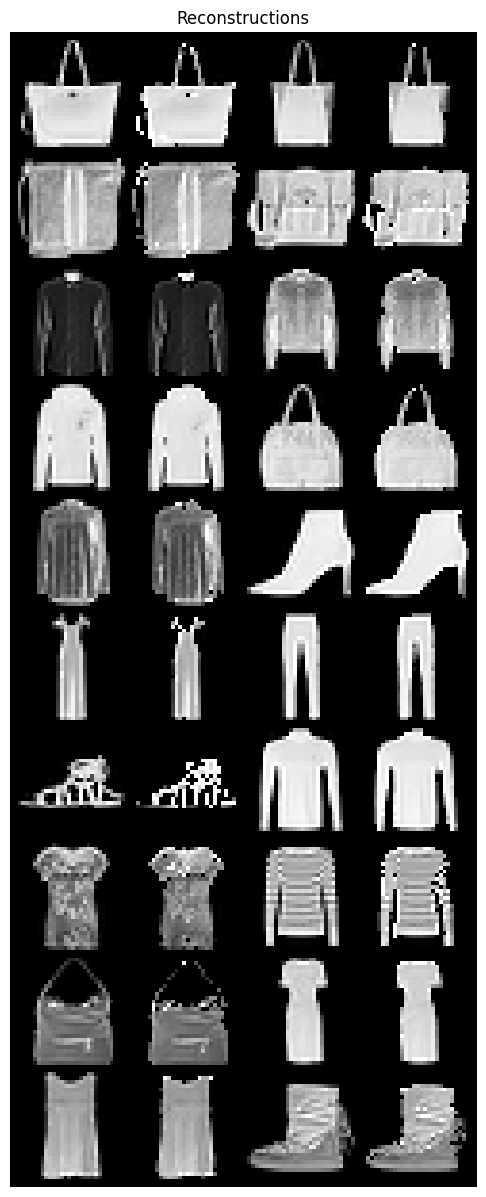


Validation bpd: 2.722

Validation bpd: 2.864

Validation bpd: 2.780

Validation bpd: 2.776

Validation bpd: 2.780

Validation bpd: 2.754

Validation bpd: 2.752

Validation bpd: 2.823

Validation bpd: 2.687

Validation bpd: 2.977

Validation bpd: 2.736

Validation bpd: 2.755

Validation bpd: 2.733

Validation bpd: 2.684

Validation bpd: 2.830

Validation bpd: 2.765

Validation bpd: 2.754

Validation bpd: 2.794

Validation bpd: 2.796

Validation bpd: 2.824

Validation bpd: 2.838

Validation bpd: 2.764

Validation bpd: 2.835

Validation bpd: 2.688

Validation bpd: 2.834

Validation bpd: 2.698

Validation bpd: 2.624

Validation bpd: 2.697

Validation bpd: 2.698

Validation bpd: 2.819

Validation bpd: 2.701

Validation bpd: 2.751

Validation bpd: 2.713

Validation bpd: 2.627

Validation bpd: 2.728

Validation bpd: 2.716

Validation bpd: 2.810

Validation bpd: 2.831

Validation bpd: 2.663

Validation bpd: 2.691

Validation bpd: 2.706

Validation bpd: 2.714

Validation bpd: 2.765

Validation

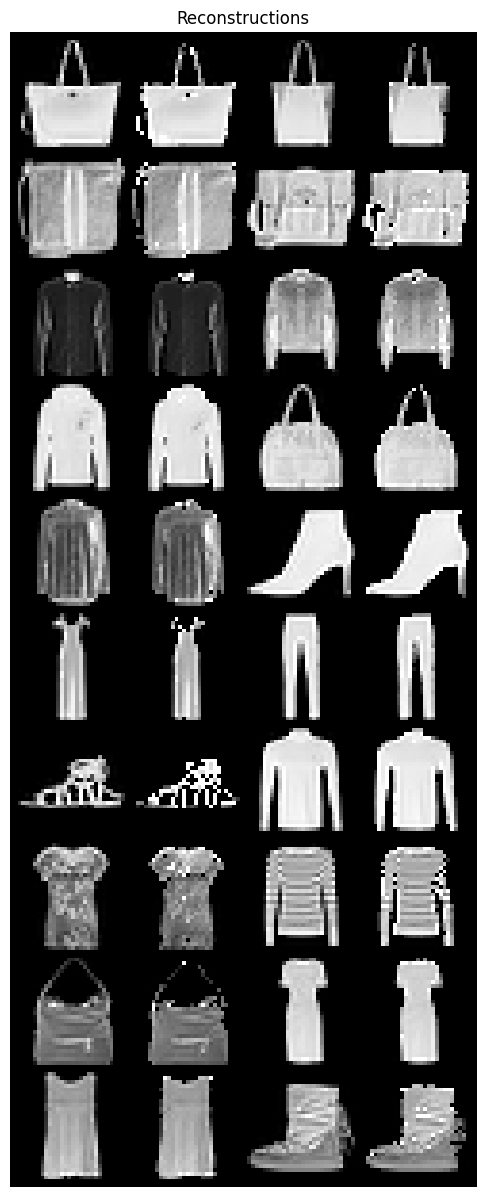


Validation bpd: 2.728

Validation bpd: 2.870

Validation bpd: 2.786

Validation bpd: 2.781

Validation bpd: 2.785

Validation bpd: 2.760

Validation bpd: 2.755

Validation bpd: 2.826

Validation bpd: 2.694

Validation bpd: 2.982

Validation bpd: 2.744

Validation bpd: 2.762

Validation bpd: 2.739

Validation bpd: 2.688

Validation bpd: 2.835

Validation bpd: 2.769

Validation bpd: 2.761

Validation bpd: 2.799

Validation bpd: 2.801

Validation bpd: 2.828

Validation bpd: 2.843

Validation bpd: 2.771

Validation bpd: 2.842

Validation bpd: 2.694

Validation bpd: 2.839

Validation bpd: 2.706

Validation bpd: 2.632

Validation bpd: 2.700

Validation bpd: 2.704

Validation bpd: 2.824

Validation bpd: 2.708

Validation bpd: 2.755

Validation bpd: 2.719

Validation bpd: 2.634

Validation bpd: 2.732

Validation bpd: 2.722

Validation bpd: 2.815

Validation bpd: 2.836

Validation bpd: 2.668

Validation bpd: 2.695

Validation bpd: 2.713

Validation bpd: 2.722

Validation bpd: 2.768

Validation

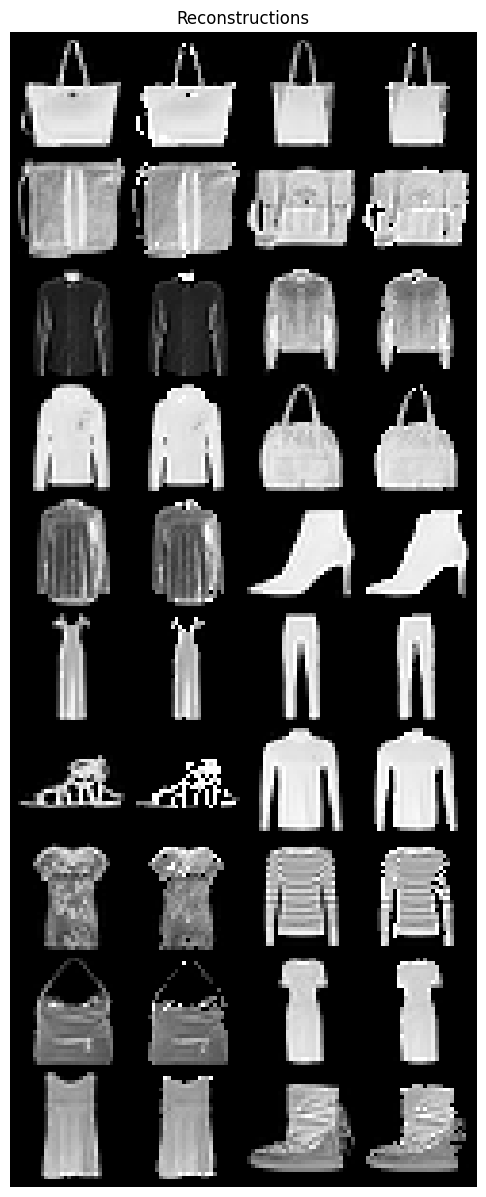


Validation bpd: 2.719

Validation bpd: 2.861

Validation bpd: 2.776

Validation bpd: 2.772

Validation bpd: 2.777

Validation bpd: 2.749

Validation bpd: 2.747

Validation bpd: 2.817

Validation bpd: 2.683

Validation bpd: 2.972

Validation bpd: 2.734

Validation bpd: 2.754

Validation bpd: 2.726

Validation bpd: 2.679

Validation bpd: 2.827

Validation bpd: 2.761

Validation bpd: 2.750

Validation bpd: 2.790

Validation bpd: 2.793

Validation bpd: 2.818

Validation bpd: 2.836

Validation bpd: 2.762

Validation bpd: 2.830

Validation bpd: 2.686

Validation bpd: 2.831

Validation bpd: 2.695

Validation bpd: 2.622

Validation bpd: 2.691

Validation bpd: 2.694

Validation bpd: 2.815

Validation bpd: 2.696

Validation bpd: 2.747

Validation bpd: 2.711

Validation bpd: 2.624

Validation bpd: 2.723

Validation bpd: 2.713

Validation bpd: 2.805

Validation bpd: 2.828

Validation bpd: 2.660

Validation bpd: 2.686

Validation bpd: 2.704

Validation bpd: 2.712

Validation bpd: 2.759

Validation

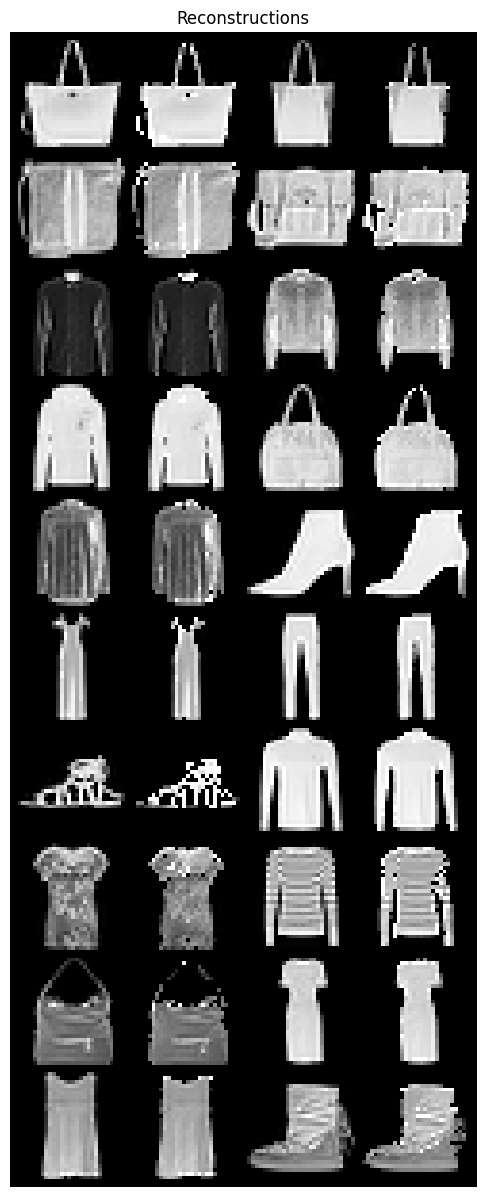


Validation bpd: 2.740

Validation bpd: 2.877

Validation bpd: 2.798

Validation bpd: 2.792

Validation bpd: 2.795

Validation bpd: 2.771

Validation bpd: 2.765

Validation bpd: 2.840

Validation bpd: 2.704

Validation bpd: 2.996

Validation bpd: 2.751

Validation bpd: 2.777

Validation bpd: 2.750

Validation bpd: 2.705

Validation bpd: 2.847

Validation bpd: 2.781

Validation bpd: 2.771

Validation bpd: 2.809

Validation bpd: 2.813

Validation bpd: 2.840

Validation bpd: 2.853

Validation bpd: 2.783

Validation bpd: 2.853

Validation bpd: 2.703

Validation bpd: 2.849

Validation bpd: 2.716

Validation bpd: 2.642

Validation bpd: 2.714

Validation bpd: 2.713

Validation bpd: 2.838

Validation bpd: 2.720

Validation bpd: 2.768

Validation bpd: 2.730

Validation bpd: 2.643

Validation bpd: 2.745

Validation bpd: 2.732

Validation bpd: 2.828

Validation bpd: 2.850

Validation bpd: 2.681

Validation bpd: 2.710

Validation bpd: 2.724

Validation bpd: 2.732

Validation bpd: 2.779

Validation

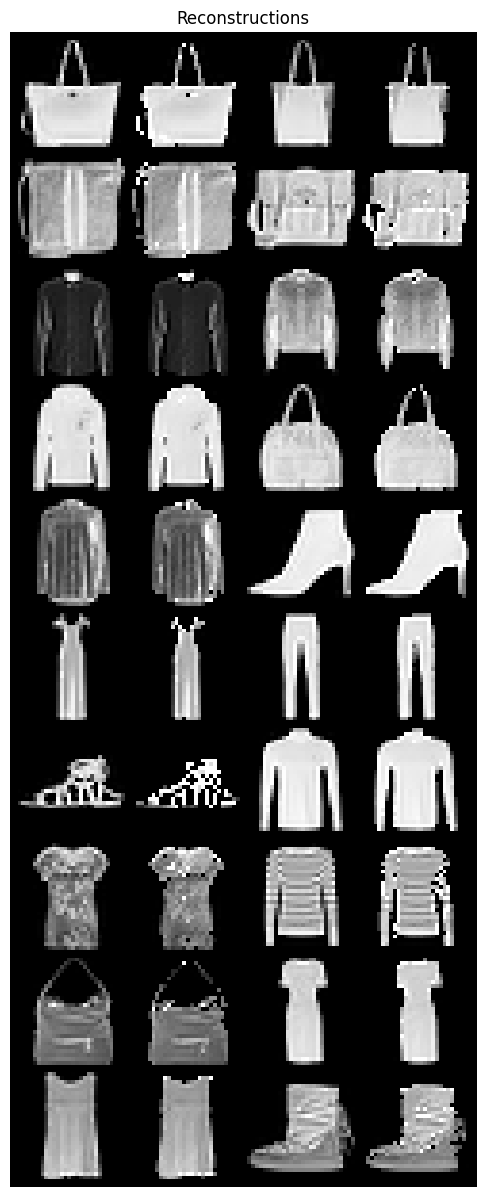


Validation bpd: 2.717

Validation bpd: 2.860

Validation bpd: 2.774

Validation bpd: 2.772

Validation bpd: 2.776

Validation bpd: 2.749

Validation bpd: 2.746

Validation bpd: 2.815

Validation bpd: 2.682

Validation bpd: 2.972

Validation bpd: 2.732

Validation bpd: 2.753

Validation bpd: 2.727

Validation bpd: 2.678

Validation bpd: 2.825

Validation bpd: 2.760

Validation bpd: 2.750

Validation bpd: 2.789

Validation bpd: 2.791

Validation bpd: 2.818

Validation bpd: 2.833

Validation bpd: 2.759

Validation bpd: 2.830

Validation bpd: 2.683

Validation bpd: 2.830

Validation bpd: 2.693

Validation bpd: 2.619

Validation bpd: 2.690

Validation bpd: 2.693

Validation bpd: 2.814

Validation bpd: 2.695

Validation bpd: 2.746

Validation bpd: 2.709

Validation bpd: 2.623

Validation bpd: 2.721

Validation bpd: 2.713

Validation bpd: 2.805

Validation bpd: 2.824

Validation bpd: 2.658

Validation bpd: 2.684

Validation bpd: 2.702

Validation bpd: 2.711

Validation bpd: 2.758

Validation

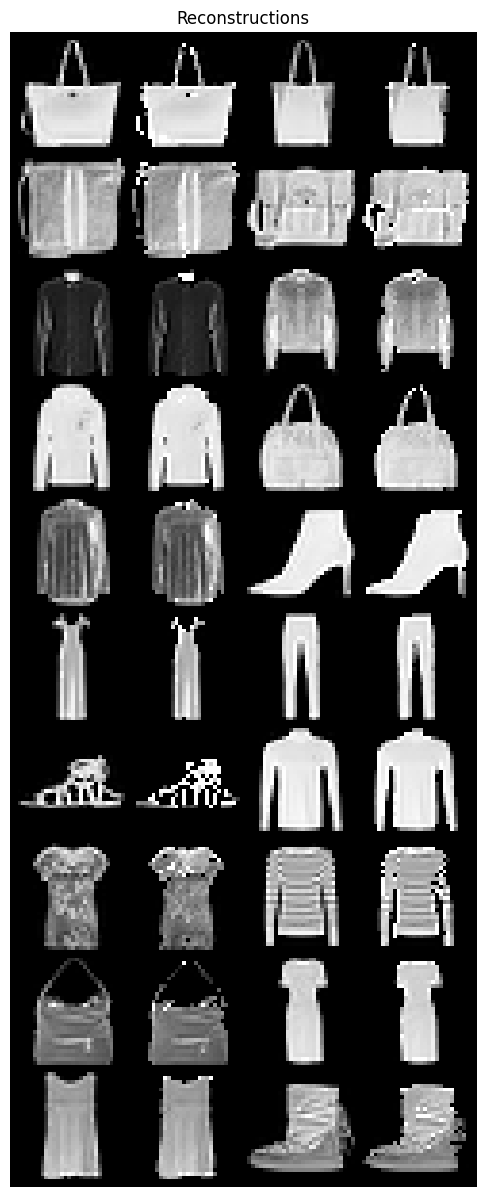


Validation bpd: 2.720

Validation bpd: 2.862

Validation bpd: 2.778

Validation bpd: 2.775

Validation bpd: 2.778

Validation bpd: 2.752

Validation bpd: 2.749

Validation bpd: 2.819

Validation bpd: 2.683

Validation bpd: 2.976

Validation bpd: 2.738

Validation bpd: 2.757

Validation bpd: 2.731

Validation bpd: 2.681

Validation bpd: 2.829

Validation bpd: 2.764

Validation bpd: 2.753

Validation bpd: 2.793

Validation bpd: 2.797

Validation bpd: 2.821

Validation bpd: 2.837

Validation bpd: 2.763

Validation bpd: 2.833

Validation bpd: 2.688

Validation bpd: 2.833

Validation bpd: 2.699

Validation bpd: 2.622

Validation bpd: 2.693

Validation bpd: 2.698

Validation bpd: 2.818

Validation bpd: 2.700

Validation bpd: 2.749

Validation bpd: 2.713

Validation bpd: 2.626

Validation bpd: 2.726

Validation bpd: 2.715

Validation bpd: 2.808

Validation bpd: 2.827

Validation bpd: 2.660

Validation bpd: 2.688

Validation bpd: 2.707

Validation bpd: 2.713

Validation bpd: 2.762

Validation

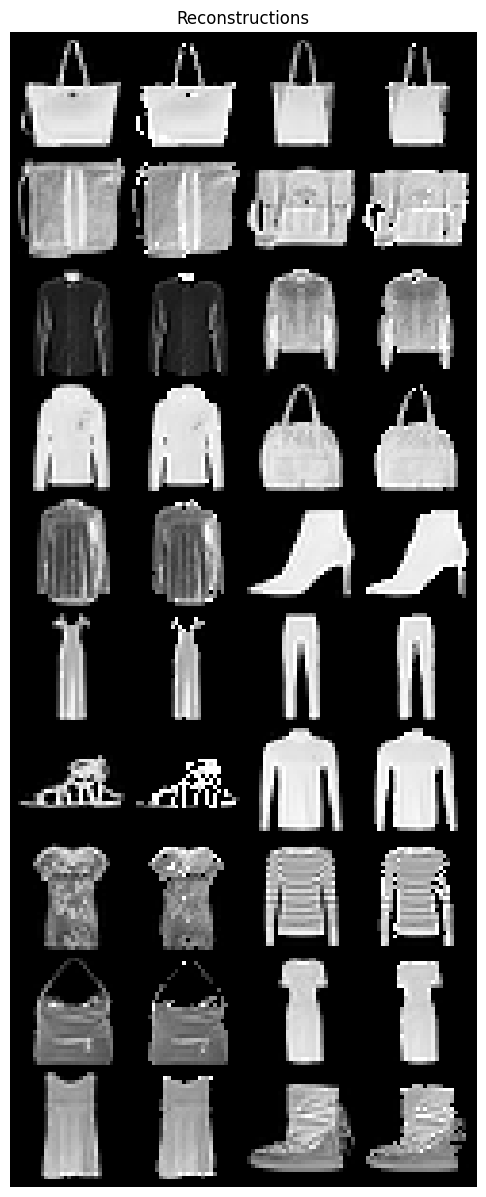


Validation bpd: 2.717

Validation bpd: 2.858

Validation bpd: 2.773

Validation bpd: 2.770

Validation bpd: 2.775

Validation bpd: 2.746

Validation bpd: 2.744

Validation bpd: 2.814

Validation bpd: 2.679

Validation bpd: 2.970

Validation bpd: 2.731

Validation bpd: 2.751

Validation bpd: 2.726

Validation bpd: 2.678

Validation bpd: 2.824

Validation bpd: 2.759

Validation bpd: 2.747

Validation bpd: 2.788

Validation bpd: 2.791

Validation bpd: 2.816

Validation bpd: 2.832

Validation bpd: 2.757

Validation bpd: 2.828

Validation bpd: 2.683

Validation bpd: 2.828

Validation bpd: 2.691

Validation bpd: 2.618

Validation bpd: 2.688

Validation bpd: 2.691

Validation bpd: 2.813

Validation bpd: 2.693

Validation bpd: 2.744

Validation bpd: 2.707

Validation bpd: 2.622

Validation bpd: 2.718

Validation bpd: 2.710

Validation bpd: 2.803

Validation bpd: 2.823

Validation bpd: 2.657

Validation bpd: 2.683

Validation bpd: 2.699

Validation bpd: 2.709

Validation bpd: 2.756

Validation

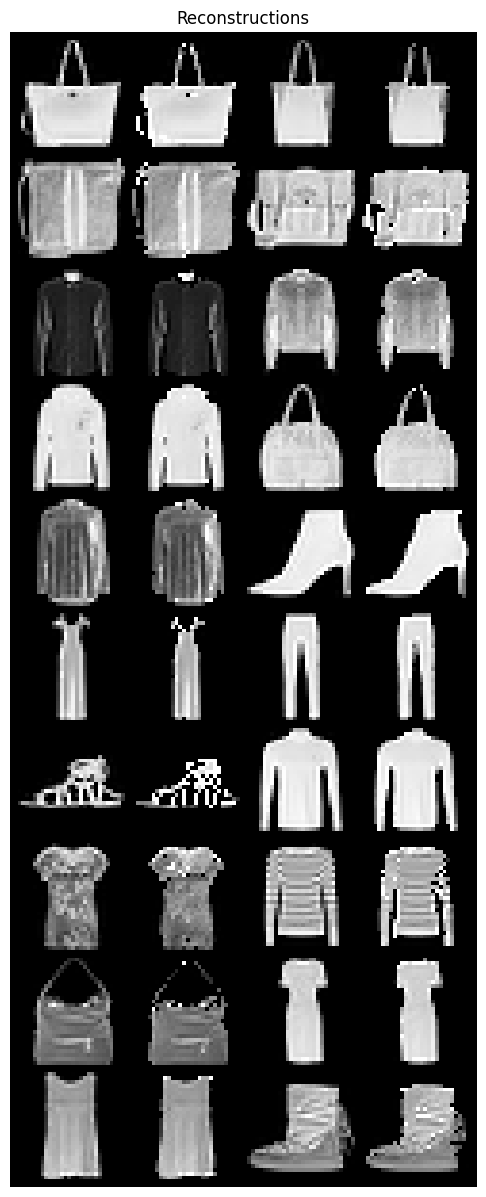


Validation bpd: 2.720

Validation bpd: 2.860

Validation bpd: 2.775

Validation bpd: 2.773

Validation bpd: 2.776

Validation bpd: 2.750

Validation bpd: 2.746

Validation bpd: 2.817

Validation bpd: 2.684

Validation bpd: 2.972

Validation bpd: 2.734

Validation bpd: 2.752

Validation bpd: 2.729

Validation bpd: 2.679

Validation bpd: 2.826

Validation bpd: 2.761

Validation bpd: 2.749

Validation bpd: 2.790

Validation bpd: 2.793

Validation bpd: 2.819

Validation bpd: 2.836

Validation bpd: 2.759

Validation bpd: 2.831

Validation bpd: 2.683

Validation bpd: 2.831

Validation bpd: 2.695

Validation bpd: 2.621

Validation bpd: 2.690

Validation bpd: 2.694

Validation bpd: 2.815

Validation bpd: 2.695

Validation bpd: 2.747

Validation bpd: 2.710

Validation bpd: 2.623

Validation bpd: 2.724

Validation bpd: 2.712

Validation bpd: 2.807

Validation bpd: 2.827

Validation bpd: 2.658

Validation bpd: 2.685

Validation bpd: 2.703

Validation bpd: 2.712

Validation bpd: 2.759

Validation

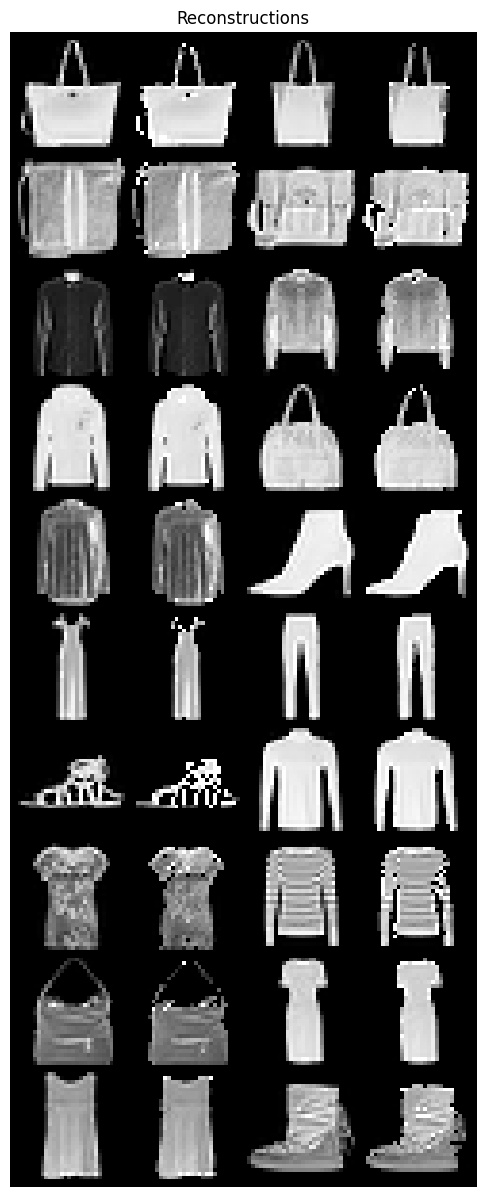


Validation bpd: 2.716

Validation bpd: 2.857

Validation bpd: 2.772

Validation bpd: 2.769

Validation bpd: 2.774

Validation bpd: 2.746

Validation bpd: 2.743

Validation bpd: 2.814

Validation bpd: 2.680

Validation bpd: 2.968

Validation bpd: 2.730

Validation bpd: 2.751

Validation bpd: 2.725

Validation bpd: 2.677

Validation bpd: 2.823

Validation bpd: 2.757

Validation bpd: 2.748

Validation bpd: 2.787

Validation bpd: 2.789

Validation bpd: 2.815

Validation bpd: 2.832

Validation bpd: 2.758

Validation bpd: 2.829

Validation bpd: 2.681

Validation bpd: 2.828

Validation bpd: 2.691

Validation bpd: 2.617

Validation bpd: 2.687

Validation bpd: 2.692

Validation bpd: 2.812

Validation bpd: 2.692

Validation bpd: 2.744

Validation bpd: 2.706

Validation bpd: 2.620

Validation bpd: 2.718

Validation bpd: 2.709

Validation bpd: 2.803

Validation bpd: 2.823

Validation bpd: 2.655

Validation bpd: 2.682

Validation bpd: 2.699

Validation bpd: 2.708

Validation bpd: 2.756

Validation

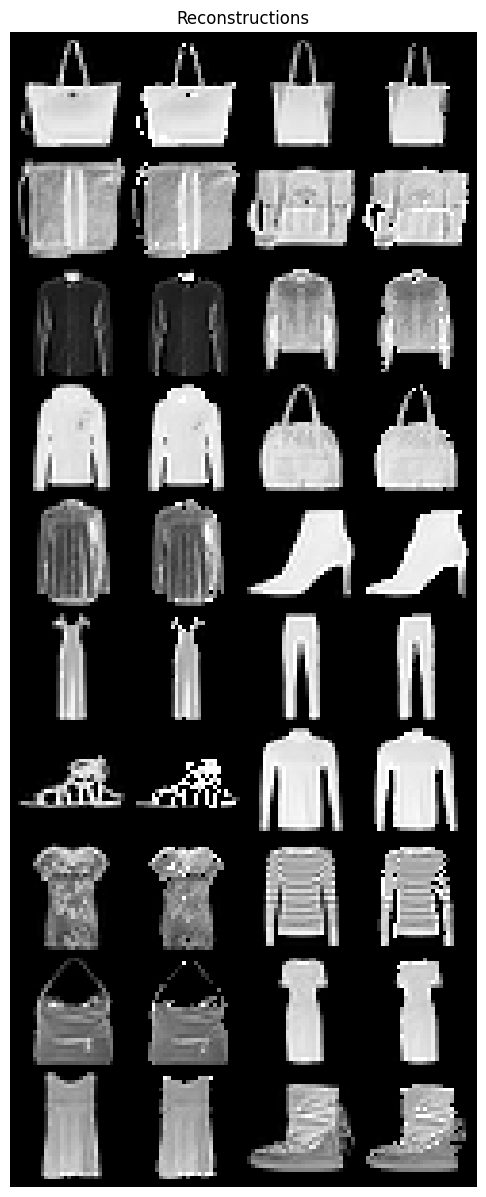


Validation bpd: 2.717

Validation bpd: 2.857

Validation bpd: 2.773

Validation bpd: 2.770

Validation bpd: 2.774

Validation bpd: 2.746

Validation bpd: 2.743

Validation bpd: 2.814

Validation bpd: 2.681

Validation bpd: 2.970

Validation bpd: 2.731

Validation bpd: 2.750

Validation bpd: 2.726

Validation bpd: 2.679

Validation bpd: 2.823

Validation bpd: 2.759

Validation bpd: 2.748

Validation bpd: 2.788

Validation bpd: 2.790

Validation bpd: 2.816

Validation bpd: 2.832

Validation bpd: 2.758

Validation bpd: 2.830

Validation bpd: 2.682

Validation bpd: 2.829

Validation bpd: 2.692

Validation bpd: 2.618

Validation bpd: 2.690

Validation bpd: 2.692

Validation bpd: 2.813

Validation bpd: 2.695

Validation bpd: 2.745

Validation bpd: 2.708

Validation bpd: 2.622

Validation bpd: 2.719

Validation bpd: 2.709

Validation bpd: 2.803

Validation bpd: 2.824

Validation bpd: 2.656

Validation bpd: 2.681

Validation bpd: 2.700

Validation bpd: 2.709

Validation bpd: 2.757

Validation

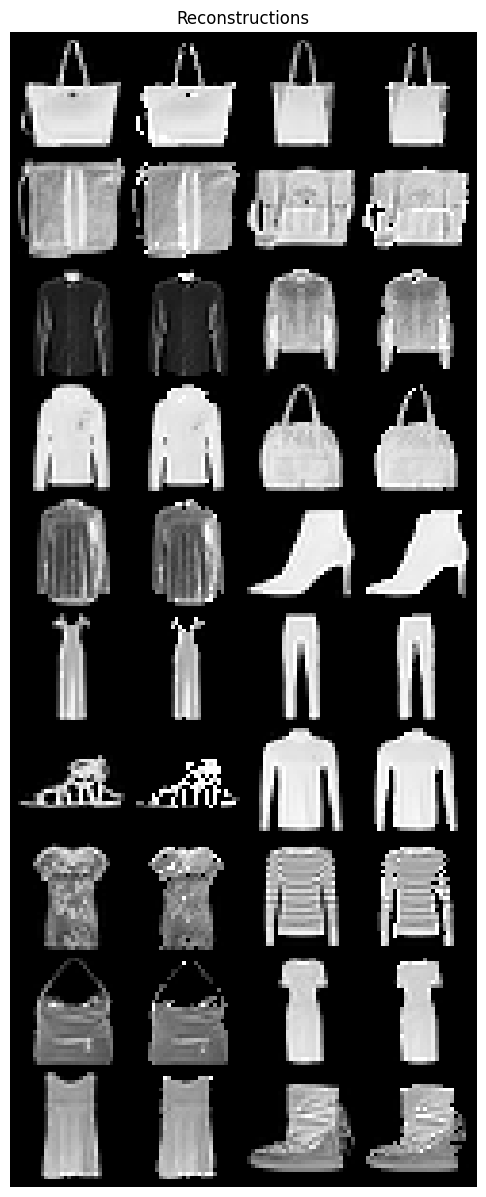


Validation bpd: 2.717

Validation bpd: 2.857

Validation bpd: 2.773

Validation bpd: 2.769

Validation bpd: 2.775

Validation bpd: 2.746

Validation bpd: 2.743

Validation bpd: 2.815

Validation bpd: 2.679

Validation bpd: 2.969

Validation bpd: 2.731

Validation bpd: 2.752

Validation bpd: 2.724

Validation bpd: 2.676

Validation bpd: 2.823

Validation bpd: 2.759

Validation bpd: 2.746

Validation bpd: 2.788

Validation bpd: 2.790

Validation bpd: 2.815

Validation bpd: 2.831

Validation bpd: 2.757

Validation bpd: 2.829

Validation bpd: 2.681

Validation bpd: 2.829

Validation bpd: 2.691

Validation bpd: 2.618

Validation bpd: 2.687

Validation bpd: 2.691

Validation bpd: 2.811

Validation bpd: 2.692

Validation bpd: 2.744

Validation bpd: 2.708

Validation bpd: 2.620

Validation bpd: 2.719

Validation bpd: 2.709

Validation bpd: 2.802

Validation bpd: 2.823

Validation bpd: 2.655

Validation bpd: 2.683

Validation bpd: 2.699

Validation bpd: 2.708

Validation bpd: 2.756

Validation

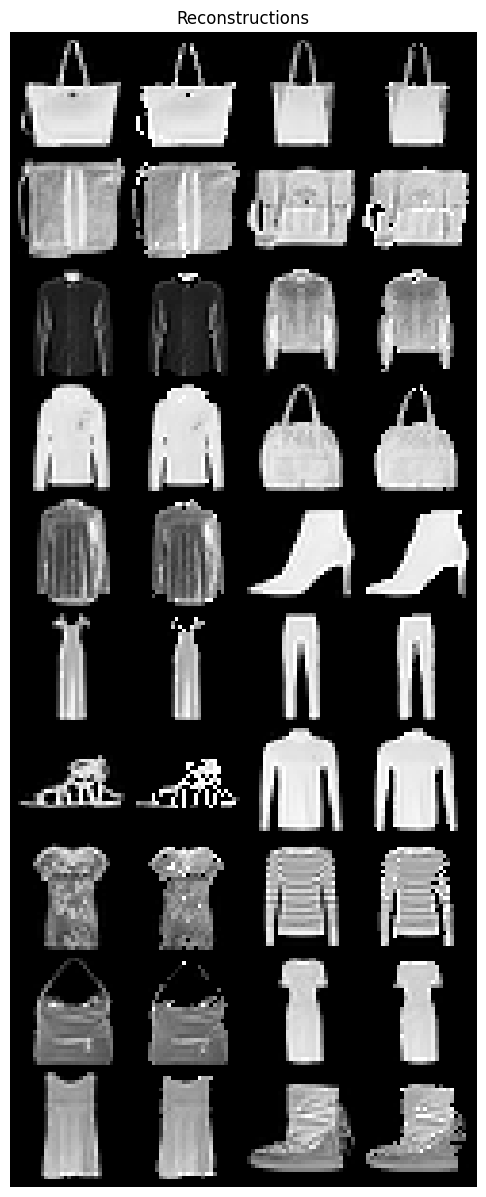


Validation bpd: 2.744

Validation bpd: 2.883

Validation bpd: 2.802

Validation bpd: 2.795

Validation bpd: 2.798

Validation bpd: 2.774

Validation bpd: 2.772

Validation bpd: 2.846

Validation bpd: 2.711

Validation bpd: 2.999

Validation bpd: 2.761

Validation bpd: 2.780

Validation bpd: 2.754

Validation bpd: 2.709

Validation bpd: 2.850

Validation bpd: 2.785

Validation bpd: 2.776

Validation bpd: 2.814

Validation bpd: 2.814

Validation bpd: 2.848

Validation bpd: 2.858

Validation bpd: 2.786

Validation bpd: 2.854

Validation bpd: 2.707

Validation bpd: 2.853

Validation bpd: 2.721

Validation bpd: 2.647

Validation bpd: 2.716

Validation bpd: 2.719

Validation bpd: 2.839

Validation bpd: 2.724

Validation bpd: 2.772

Validation bpd: 2.735

Validation bpd: 2.649

Validation bpd: 2.753

Validation bpd: 2.736

Validation bpd: 2.830

Validation bpd: 2.849

Validation bpd: 2.686

Validation bpd: 2.714

Validation bpd: 2.731

Validation bpd: 2.739

Validation bpd: 2.787

Validation

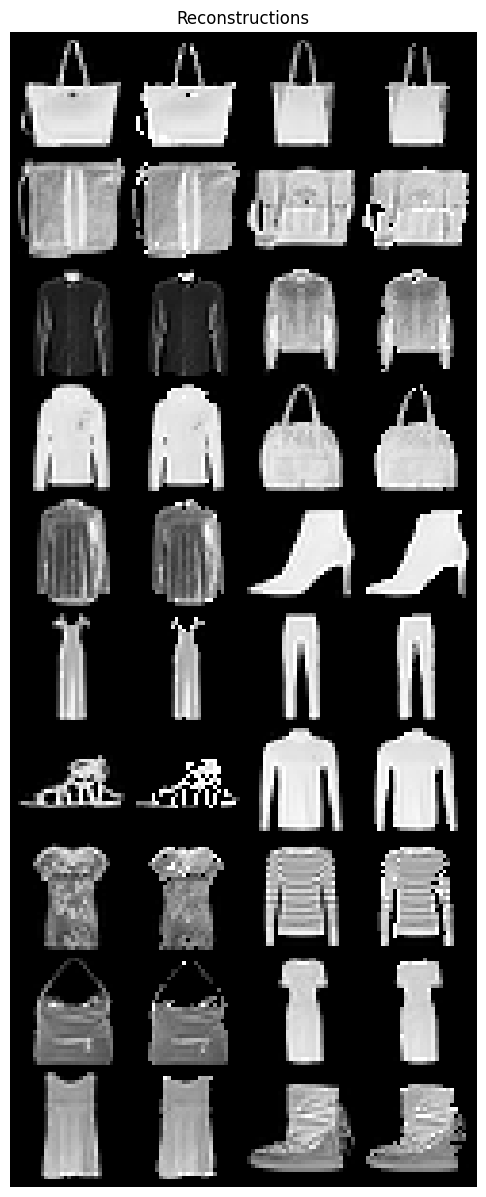


Validation bpd: 2.715

Validation bpd: 2.856

Validation bpd: 2.771

Validation bpd: 2.769

Validation bpd: 2.773

Validation bpd: 2.746

Validation bpd: 2.742

Validation bpd: 2.811

Validation bpd: 2.676

Validation bpd: 2.967

Validation bpd: 2.730

Validation bpd: 2.750

Validation bpd: 2.723

Validation bpd: 2.675

Validation bpd: 2.821

Validation bpd: 2.757

Validation bpd: 2.745

Validation bpd: 2.787

Validation bpd: 2.787

Validation bpd: 2.815

Validation bpd: 2.831

Validation bpd: 2.756

Validation bpd: 2.828

Validation bpd: 2.680

Validation bpd: 2.826

Validation bpd: 2.690

Validation bpd: 2.617

Validation bpd: 2.685

Validation bpd: 2.691

Validation bpd: 2.812

Validation bpd: 2.691

Validation bpd: 2.742

Validation bpd: 2.707

Validation bpd: 2.619

Validation bpd: 2.718

Validation bpd: 2.708

Validation bpd: 2.802

Validation bpd: 2.821

Validation bpd: 2.656

Validation bpd: 2.679

Validation bpd: 2.698

Validation bpd: 2.706

Validation bpd: 2.755

Validation

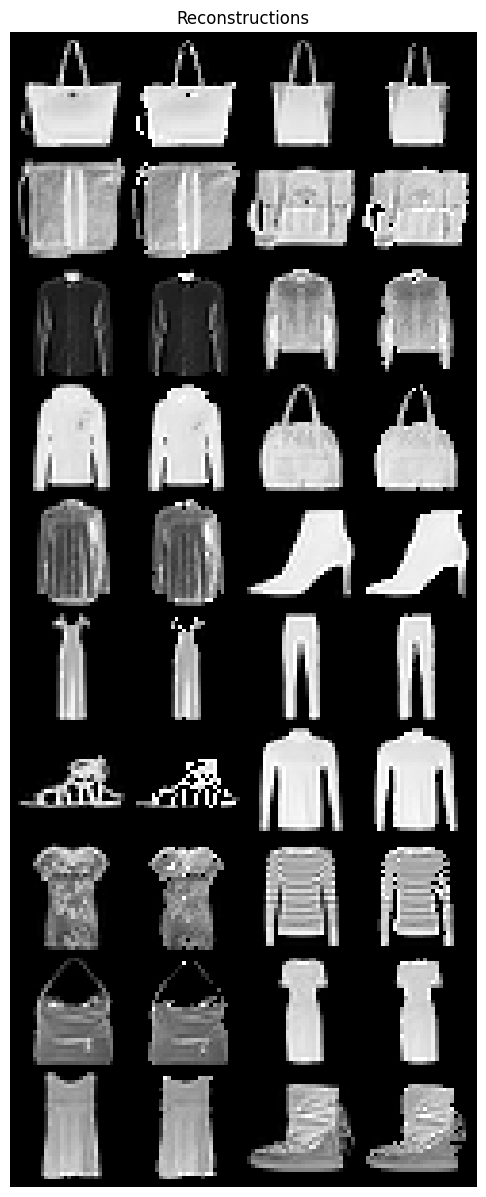


Validation bpd: 2.724

Validation bpd: 2.864

Validation bpd: 2.780

Validation bpd: 2.775

Validation bpd: 2.781

Validation bpd: 2.753

Validation bpd: 2.751

Validation bpd: 2.822

Validation bpd: 2.687

Validation bpd: 2.981

Validation bpd: 2.741

Validation bpd: 2.759

Validation bpd: 2.732

Validation bpd: 2.684

Validation bpd: 2.831

Validation bpd: 2.765

Validation bpd: 2.753

Validation bpd: 2.793

Validation bpd: 2.798

Validation bpd: 2.823

Validation bpd: 2.839

Validation bpd: 2.764

Validation bpd: 2.838

Validation bpd: 2.688

Validation bpd: 2.836

Validation bpd: 2.699

Validation bpd: 2.624

Validation bpd: 2.695

Validation bpd: 2.700

Validation bpd: 2.819

Validation bpd: 2.701

Validation bpd: 2.752

Validation bpd: 2.714

Validation bpd: 2.630

Validation bpd: 2.728

Validation bpd: 2.716

Validation bpd: 2.812

Validation bpd: 2.830

Validation bpd: 2.665

Validation bpd: 2.694

Validation bpd: 2.708

Validation bpd: 2.713

Validation bpd: 2.761

Validation

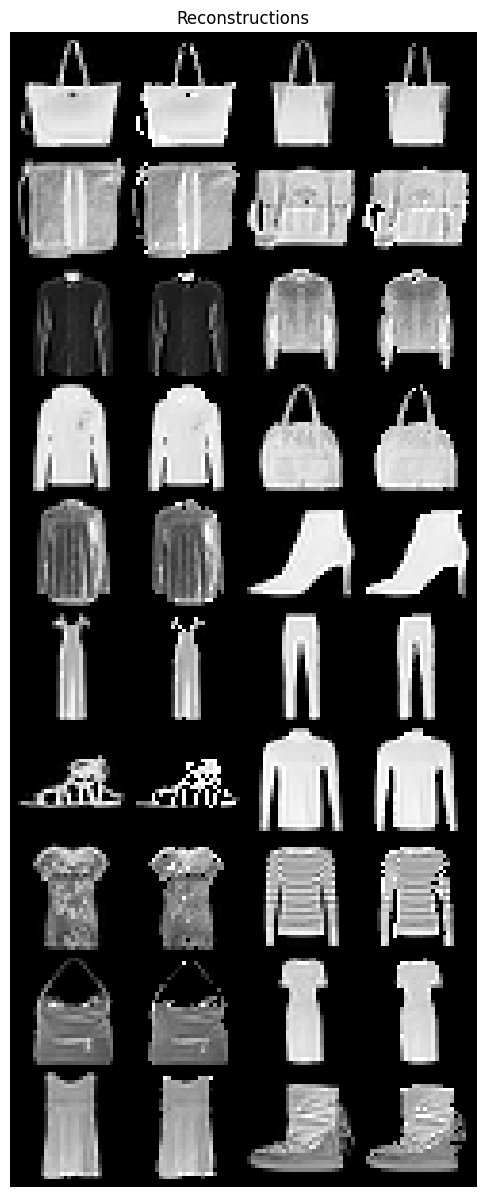


Validation bpd: 2.712

Validation bpd: 2.855

Validation bpd: 2.769

Validation bpd: 2.767

Validation bpd: 2.771

Validation bpd: 2.743

Validation bpd: 2.739

Validation bpd: 2.809

Validation bpd: 2.674

Validation bpd: 2.966

Validation bpd: 2.729

Validation bpd: 2.748

Validation bpd: 2.721

Validation bpd: 2.672

Validation bpd: 2.819

Validation bpd: 2.755

Validation bpd: 2.742

Validation bpd: 2.783

Validation bpd: 2.786

Validation bpd: 2.812

Validation bpd: 2.828

Validation bpd: 2.754

Validation bpd: 2.825

Validation bpd: 2.678

Validation bpd: 2.824

Validation bpd: 2.689

Validation bpd: 2.614

Validation bpd: 2.684

Validation bpd: 2.688

Validation bpd: 2.809

Validation bpd: 2.690

Validation bpd: 2.740

Validation bpd: 2.704

Validation bpd: 2.618

Validation bpd: 2.715

Validation bpd: 2.705

Validation bpd: 2.799

Validation bpd: 2.820

Validation bpd: 2.652

Validation bpd: 2.678

Validation bpd: 2.696

Validation bpd: 2.704

Validation bpd: 2.751

Validation

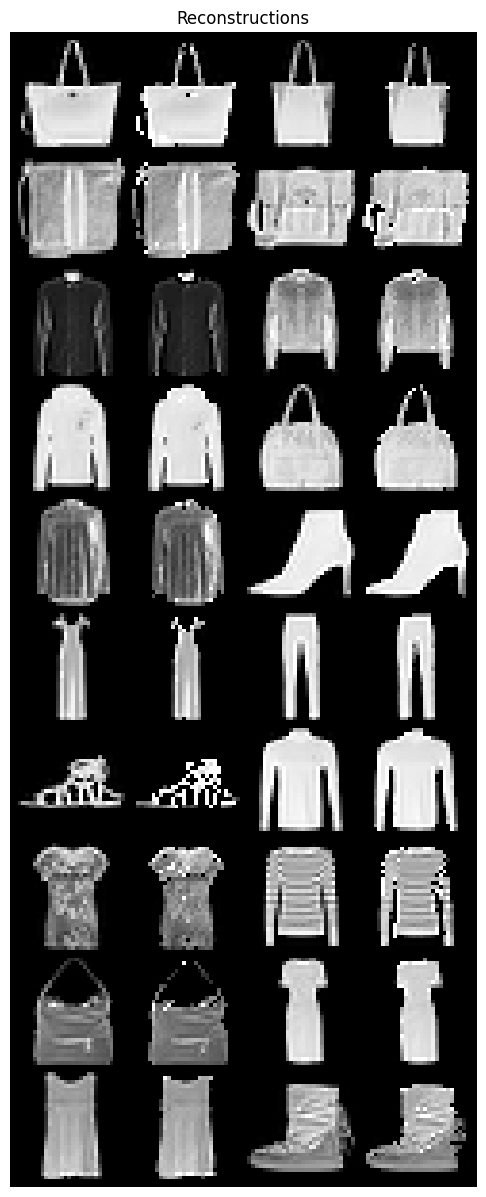


Validation bpd: 2.713

Validation bpd: 2.854

Validation bpd: 2.769

Validation bpd: 2.767

Validation bpd: 2.771

Validation bpd: 2.743

Validation bpd: 2.740

Validation bpd: 2.811

Validation bpd: 2.675

Validation bpd: 2.965

Validation bpd: 2.727

Validation bpd: 2.748

Validation bpd: 2.720

Validation bpd: 2.674

Validation bpd: 2.819

Validation bpd: 2.756

Validation bpd: 2.744

Validation bpd: 2.784

Validation bpd: 2.785

Validation bpd: 2.811

Validation bpd: 2.827

Validation bpd: 2.753

Validation bpd: 2.825

Validation bpd: 2.678

Validation bpd: 2.824

Validation bpd: 2.687

Validation bpd: 2.613

Validation bpd: 2.683

Validation bpd: 2.688

Validation bpd: 2.807

Validation bpd: 2.690

Validation bpd: 2.740

Validation bpd: 2.705

Validation bpd: 2.618

Validation bpd: 2.714

Validation bpd: 2.706

Validation bpd: 2.799

Validation bpd: 2.820

Validation bpd: 2.651

Validation bpd: 2.679

Validation bpd: 2.696

Validation bpd: 2.704

Validation bpd: 2.752

Validation

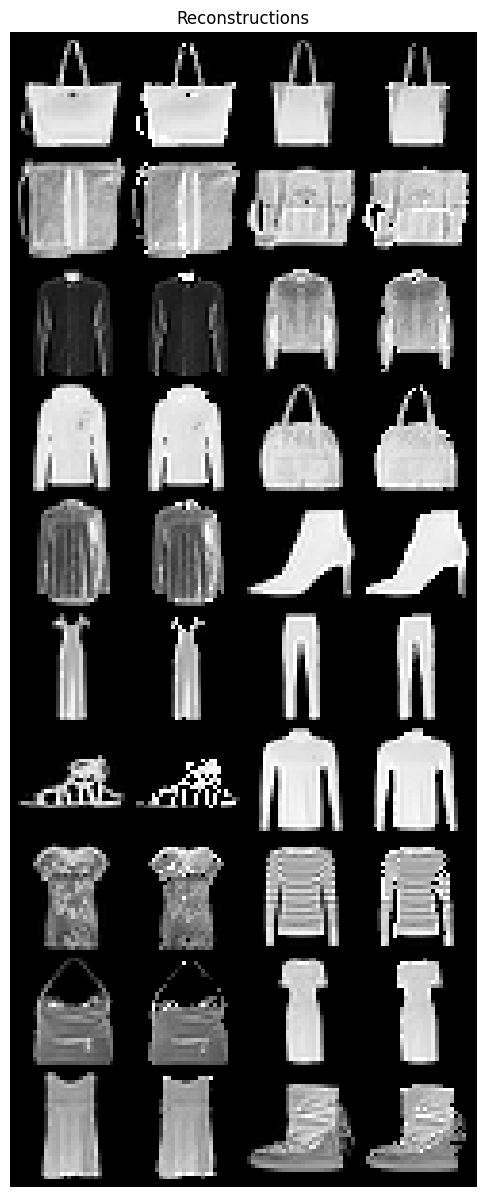


Validation bpd: 2.713

Validation bpd: 2.855

Validation bpd: 2.771

Validation bpd: 2.769

Validation bpd: 2.772

Validation bpd: 2.744

Validation bpd: 2.741

Validation bpd: 2.810

Validation bpd: 2.676

Validation bpd: 2.967

Validation bpd: 2.728

Validation bpd: 2.750

Validation bpd: 2.722

Validation bpd: 2.675

Validation bpd: 2.820

Validation bpd: 2.758

Validation bpd: 2.744

Validation bpd: 2.786

Validation bpd: 2.788

Validation bpd: 2.813

Validation bpd: 2.830

Validation bpd: 2.756

Validation bpd: 2.826

Validation bpd: 2.679

Validation bpd: 2.825

Validation bpd: 2.690

Validation bpd: 2.615

Validation bpd: 2.685

Validation bpd: 2.689

Validation bpd: 2.809

Validation bpd: 2.692

Validation bpd: 2.741

Validation bpd: 2.705

Validation bpd: 2.620

Validation bpd: 2.716

Validation bpd: 2.707

Validation bpd: 2.799

Validation bpd: 2.821

Validation bpd: 2.653

Validation bpd: 2.679

Validation bpd: 2.697

Validation bpd: 2.705

Validation bpd: 2.753

Validation

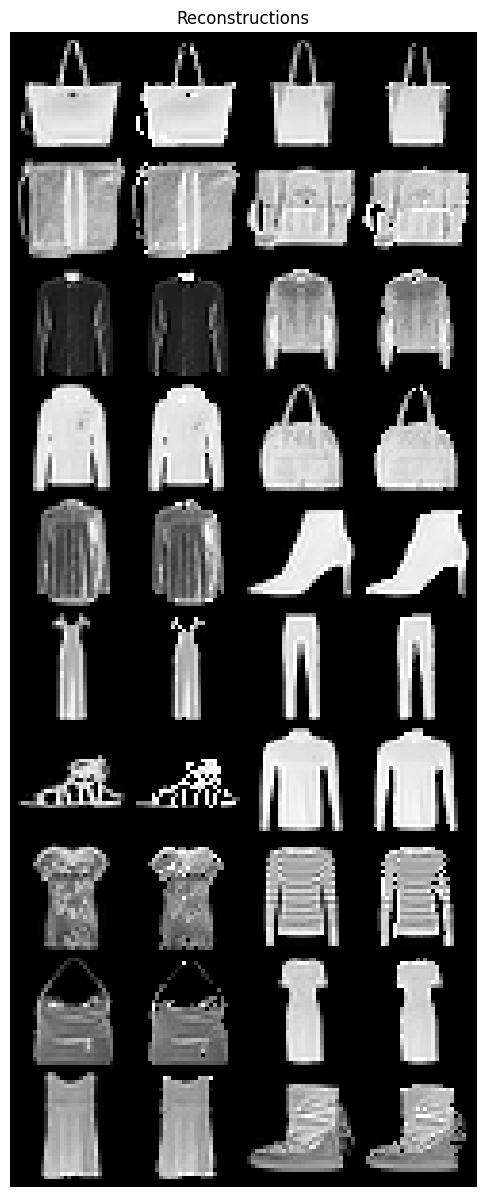


Validation bpd: 2.711

Validation bpd: 2.853

Validation bpd: 2.766

Validation bpd: 2.765

Validation bpd: 2.769

Validation bpd: 2.741

Validation bpd: 2.738

Validation bpd: 2.810

Validation bpd: 2.674

Validation bpd: 2.966

Validation bpd: 2.726

Validation bpd: 2.747

Validation bpd: 2.719

Validation bpd: 2.672

Validation bpd: 2.818

Validation bpd: 2.754

Validation bpd: 2.742

Validation bpd: 2.782

Validation bpd: 2.785

Validation bpd: 2.811

Validation bpd: 2.826

Validation bpd: 2.753

Validation bpd: 2.824

Validation bpd: 2.676

Validation bpd: 2.824

Validation bpd: 2.686

Validation bpd: 2.612

Validation bpd: 2.682

Validation bpd: 2.687

Validation bpd: 2.808

Validation bpd: 2.689

Validation bpd: 2.738

Validation bpd: 2.702

Validation bpd: 2.616

Validation bpd: 2.713

Validation bpd: 2.704

Validation bpd: 2.798

Validation bpd: 2.819

Validation bpd: 2.650

Validation bpd: 2.677

Validation bpd: 2.693

Validation bpd: 2.702

Validation bpd: 2.752

Validation

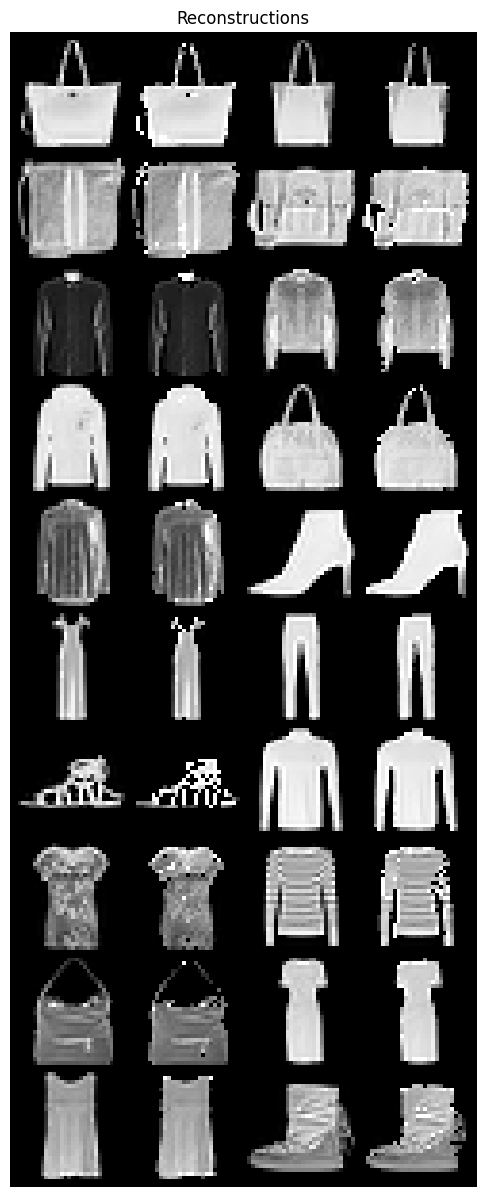


Validation bpd: 2.711

Validation bpd: 2.853

Validation bpd: 2.768

Validation bpd: 2.764

Validation bpd: 2.769

Validation bpd: 2.741

Validation bpd: 2.738

Validation bpd: 2.810

Validation bpd: 2.673

Validation bpd: 2.965

Validation bpd: 2.726

Validation bpd: 2.747

Validation bpd: 2.720

Validation bpd: 2.671

Validation bpd: 2.818

Validation bpd: 2.754

Validation bpd: 2.741

Validation bpd: 2.783

Validation bpd: 2.786

Validation bpd: 2.811

Validation bpd: 2.827

Validation bpd: 2.753

Validation bpd: 2.824

Validation bpd: 2.677

Validation bpd: 2.824

Validation bpd: 2.687

Validation bpd: 2.612

Validation bpd: 2.681

Validation bpd: 2.687

Validation bpd: 2.807

Validation bpd: 2.685

Validation bpd: 2.739

Validation bpd: 2.702

Validation bpd: 2.616

Validation bpd: 2.713

Validation bpd: 2.705

Validation bpd: 2.798

Validation bpd: 2.819

Validation bpd: 2.652

Validation bpd: 2.677

Validation bpd: 2.696

Validation bpd: 2.701

Validation bpd: 2.751

Validation

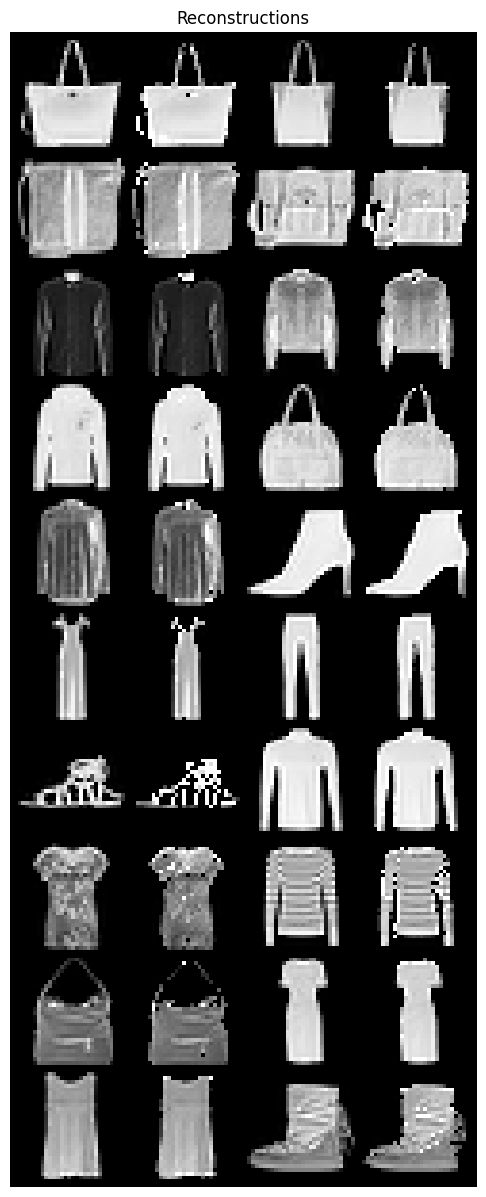


Validation bpd: 2.713

Validation bpd: 2.856

Validation bpd: 2.770

Validation bpd: 2.768

Validation bpd: 2.772

Validation bpd: 2.744

Validation bpd: 2.741

Validation bpd: 2.812

Validation bpd: 2.676

Validation bpd: 2.969

Validation bpd: 2.729

Validation bpd: 2.749

Validation bpd: 2.721

Validation bpd: 2.675

Validation bpd: 2.821

Validation bpd: 2.755

Validation bpd: 2.743

Validation bpd: 2.785

Validation bpd: 2.788

Validation bpd: 2.813

Validation bpd: 2.831

Validation bpd: 2.755

Validation bpd: 2.828

Validation bpd: 2.678

Validation bpd: 2.826

Validation bpd: 2.689

Validation bpd: 2.615

Validation bpd: 2.685

Validation bpd: 2.689

Validation bpd: 2.808

Validation bpd: 2.691

Validation bpd: 2.743

Validation bpd: 2.705

Validation bpd: 2.617

Validation bpd: 2.717

Validation bpd: 2.709

Validation bpd: 2.801

Validation bpd: 2.822

Validation bpd: 2.653

Validation bpd: 2.682

Validation bpd: 2.696

Validation bpd: 2.705

Validation bpd: 2.755

Validation

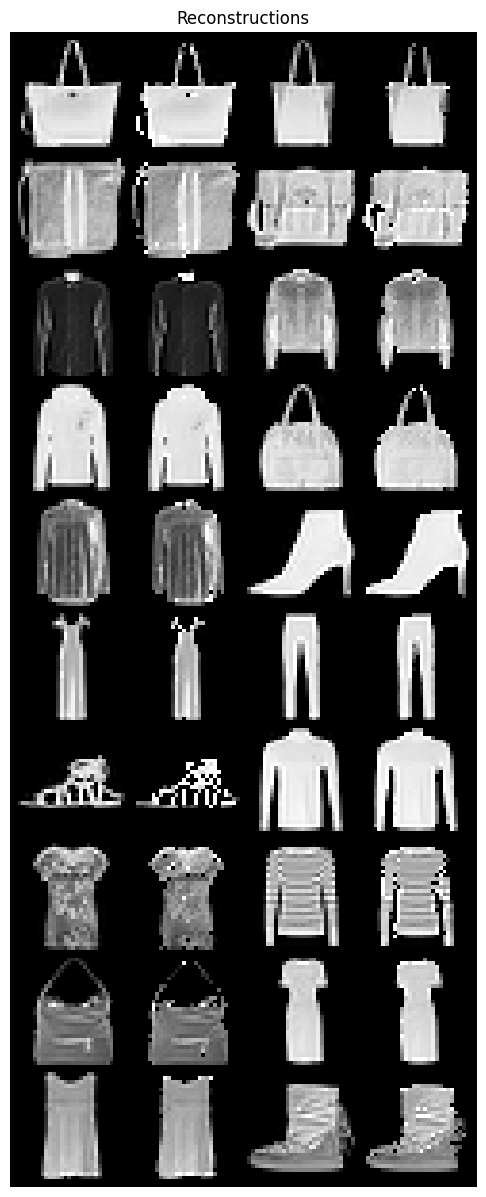


Validation bpd: 2.714

Validation bpd: 2.854

Validation bpd: 2.768

Validation bpd: 2.768

Validation bpd: 2.772

Validation bpd: 2.741

Validation bpd: 2.741

Validation bpd: 2.811

Validation bpd: 2.676

Validation bpd: 2.965

Validation bpd: 2.728

Validation bpd: 2.748

Validation bpd: 2.722

Validation bpd: 2.674

Validation bpd: 2.820

Validation bpd: 2.757

Validation bpd: 2.745

Validation bpd: 2.785

Validation bpd: 2.786

Validation bpd: 2.812

Validation bpd: 2.830

Validation bpd: 2.754

Validation bpd: 2.827

Validation bpd: 2.677

Validation bpd: 2.823

Validation bpd: 2.689

Validation bpd: 2.614

Validation bpd: 2.685

Validation bpd: 2.688

Validation bpd: 2.808

Validation bpd: 2.688

Validation bpd: 2.741

Validation bpd: 2.703

Validation bpd: 2.617

Validation bpd: 2.716

Validation bpd: 2.707

Validation bpd: 2.800

Validation bpd: 2.822

Validation bpd: 2.654

Validation bpd: 2.680

Validation bpd: 2.696

Validation bpd: 2.705

Validation bpd: 2.753

Validation

`Trainer.fit` stopped: `max_epochs=70` reached.


Epoch 69: 100%|██████████| 421/421 [02:54<00:00,  2.41it/s, v_num=3]


/Users/kwasus/Desktop/STUDIA/SEM6/LLM/PROJECT/Autoregressive-Image-Generation/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:429: Consider setting `persistent_workers=True` in 'test_dataloader' to speed up the dataloader worker initialization.


Testing DataLoader 0: 100%|██████████| 79/79 [00:16<00:00,  4.70it/s]


In [8]:
channels_hidden = 64    # for more complex datasets like cifar10 channels_dim=128 would be more appropriate (better results)
model_path = "../pretrained_models/pixel_cnn"
epochs = 70
# epochs = 1
num_classes = 256   # it's numer of possible pixels values [0..255]

start = time.time()
model, result = train_pixel_cnn(epochs=epochs, dataloaders=dataloaders, device=device, model_path=model_path, c_in=input_channels, c_hidden=channels_hidden, num_classes=num_classes)
end = time.time()

In [9]:
torch.save(model.state_dict(), f=os.path.join(model_path, "pixel_cnn.pth"))

In [10]:
test_res = result["test"][0]
print("Test bits per dimension: %4.3fbpd" % (test_res["test_loss"] if "test_loss" in test_res else test_res["test_bpd"]))

Test bits per dimension: 2.751bpd


In [11]:
training_time = (end - start) / 60
print(f"Training lasted for {training_time} minutes")

Training lasted for 203.85767826636632 minutes


Seed set to 1


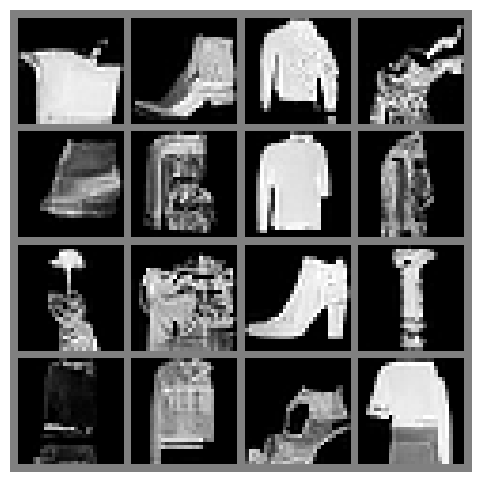

In [13]:
num_samples = 16
pl.seed_everything(1)

samples = model.sample(img_shape=(num_samples, input_channels, input_size, input_size))
show_imgs(samples.cpu())